# YOLOX-S — DIMER anchor-free detection and bounded detection fine-tuning (standalone)

[![GitHub](https://img.shields.io/badge/GitHub-181717?style=flat&logo=github&logoColor=white)](https://github.com/kurtvalcorza/yolox-detection-pipeline) [![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/kurtvalcorza/yolox-detection-pipeline/blob/main/tutorials/yolox_detection_finetune_colab.ipynb) [![Upstream](https://img.shields.io/badge/Upstream-Megvii--BaseDetection%2FYOLOX-181717?style=flat&logo=github&logoColor=white)](https://github.com/Megvii-BaseDetection/YOLOX) [![Weights](https://img.shields.io/badge/Weights-yolox__s.pth%20%400.1.1rc0-blue?style=flat)](https://github.com/Megvii-BaseDetection/YOLOX/releases/tag/0.1.1rc0) [![arXiv](https://img.shields.io/badge/arXiv-2107.08430-b31b1b.svg)](https://arxiv.org/abs/2107.08430) [![License](https://img.shields.io/badge/License-Apache--2.0-green.svg)](https://github.com/Megvii-BaseDetection/YOLOX/blob/main/LICENSE)

> **⚠️ Notice.** For research, training and evaluation only. Not validated for production,
> clinical, diagnostic or safety-critical use. Running this notebook downloads third-party
> model weights and datasets under their own licenses (see the model card) and uses compute
> on your own Colab or Kaggle account. Data you bring stays in your runtime, and you are
> responsible for having the right to use it. Results here are tutorial evidence, not
> benchmarks. Everything is provided "as is", without warranty of any kind. To the maximum
> extent permitted by law, the maintainers and the DIMER platform accept no liability for
> its use.

**Profile:** `E2E`  
**Kind:** `TUTORIAL`  
**Mode:** `GUIDED`  
**Notebook specification:** DIMER Notebook Specification 2.5 — **standalone** (§4)  
**Capability:** anchor-free object detection over the 80 COCO classes, and a bounded SimOTA fine-tune that re-heads the detector onto your own class vocabulary, chooses its configuration on a validation pool by a pre-registered grid, scores a fresh test with COCO-style average precision only under the pre-registered settings, and exports a reloadable artifact

**This notebook is standalone.** It carries the repository's package (11 modules under `src/yolox_detection_pipeline/`, at revision `ab130f33d564`) verbatim in Section 2, the pinned model identity and the per-file SHA-256 manifest in Section 3, and the exact runtime pins in Section 1, so it keeps working after export even if the repository changes or disappears. Its only external dependencies are the pinned Python distributions and the immutable GitHub release assets of upstream tag `0.1.1rc0` (~72 MB, digest-verified before loading). It was generated by `tools/build_notebook.py` (build_notebook.py/2.2-swc-yolox); edit the repository and regenerate rather than editing cells.

**Run all:** Selecting **Run all** in a fresh supported runtime installs the pinned dependencies, downloads and digest-verifies the pinned release asset, draws the COCO demonstration scene and scores it, builds and validates the labelled adaptation dataset, splits it, measures the pre-adaptation baseline, **runs the bounded SimOTA fine-tune** (the pre-registered grid on a GPU, the recorded selection C0 on a CPU), re-checks every pre-registered setting and scores the fresh test only if they all hold, detects on unseen images, exports the adapted artifact, reloads it from disk and confirms the reloaded model scores identically, and writes every result as JSON with provenance. Nothing is skipped behind a default-off flag, and the path needs no repository clone, no DIMER worker or service, no credential, no upload dialog, no configuration edit and no runtime restart: the pinned dependencies go into an isolated environment built from a hash lock, leaving the kernel's own packages alone (NOTEBOOK_SPEC 2.5 §5, RUN7, FT2). A CPU (or non-T4) Run all is exploratory by design; the evaluation of record is a hosted T4 run (`docs/release-verification.md`).

**Bring Your Own Data:** Two BYOD branches are provided and both are optional and off by default. `USE_BYOD_IMAGE` runs your own image through the same validation and detection contract as the sample. `USE_BYOD_DATASET` takes your own labelled records and runs them through the *same* local stages the sample used — validate, split, baseline, fine-tune, evaluate — rather than only detecting with them, because this is an adaptation profile (NOTEBOOK_SPEC 2.5 DAT14, §25.10), followed by the same export, fresh reload and identical-score check, and a result JSON. A BYOD run is exploratory: it never scores the tutorial's fresh test, and a refused input prints one message and keeps the earlier outputs. `BYOD_IMAGE_PATH` and `BYOD_DATASET_DIR` read from a location without an upload dialog; the record format and the ceilings are stated in the Prerequisites and in Section 13; uploads stay inside this runtime.

YOLOX-S is a small anchor-free detector: a CSPDarknet backbone and a PAFPN neck feed a **decoupled head** that emits, at each of 8400 anchor points over a 640×640 letterboxed image, one box, one objectness logit and one logit per class. There are no anchor boxes to tune and no class softmax — objectness and class probability are independent sigmoids whose product is the score, and per-class NMS does the rest. At training time the same head runs **SimOTA**: it decides for itself which anchor points should be responsible for which ground-truth object, by solving a small assignment problem over an IoU-and-classification cost, instead of using a fixed rule.

That last property is why this notebook can fine-tune a detector in a few minutes on a CPU. **The default path really adapts the model:** it re-heads YOLOX onto a three-class sign vocabulary that does not exist in COCO, measures a pre-adaptation baseline, runs a bounded SimOTA fine-tune with the backbone frozen (a pre-registered three-config grid on a GPU, chosen on a validation pool), scores the result on a fresh test only under the pre-registered settings, runs the adapted model on unseen images, exports the weights as one artifact and reloads that artifact as if from a cold start. Every number you will see comes from cells in this notebook, in this runtime.

Two facts about the input pipeline are load-bearing and the notebook will show you both. Channel order is **BGR**, raw 0–255, with no `/255` and no mean/std normalisation — that is what upstream feeds the network, and handing it RGB instead measurably degrades detection. And the letterbox pads with grey 114 rather than black. The carried package owns both, so you do not have to.

**Learning objectives:** install the pinned runtime; read what the carried package guarantees and which of its modules are vendored upstream YOLOX rather than DIMER code; stage and digest-verify an immutable GitHub release asset (not a Hub revision) before anything unpickles it; run COCO detection on a drawn scene and read the objectness × class score, the two caller-owned thresholds and the per-object `box_iou` correctly, including one object the pretrained model gets wrong; build and validate a labelled detection dataset in the record shape the fine-tuner accepts; split it and measure a **baseline before adapting**; run a bounded SimOTA fine-tune onto a new class vocabulary and choose its configuration on validation by a pre-registered rule; tell a validation score, an exposed development test and a fresh test apart, and read a paired bootstrap interval; detect on images from an unseen seed; and export, reload and re-verify the resulting artifact.

**This notebook does not demonstrate:** real traffic-sign detection or any deployment claim — the adaptation dataset is drawn in code, so the fine-tuned model has learned these renderings and nothing about photographs; published COCO numbers (upstream reports 40.5 AP for YOLOX-S on COCO test-dev, which this notebook neither reproduces nor checks, and the average-precision helper here is a small faithful implementation without pycocotools' area ranges or crowd handling); upstream's mosaic/mixup augmentation, its 300-epoch schedule, its EMA and its learning-rate warmup, none of which a bounded tutorial run uses; the L1 box-refinement term, which upstream only enables for the last 15 epochs; full-network fine-tuning (the default freezes the backbone, and an earlier held-out grid found that unfreezing it at 1e-3 collapsed the model); any comparison with the YOLOX-X tutorial; instance segmentation, tracking, batched or video inference, quantisation, ONNX/TensorRT export, and upstream's latency figures.

## How to use this notebook

**Who this notebook is for.** Learners who can open a hosted notebook (Google Colab, Kaggle or Jupyter), run cells in order and read short Python, and who want to see how a pretrained object detector is checked, adapted to new classes, evaluated and exported honestly. No prior experience with YOLOX is assumed: each term is explained where it is first needed and again in the glossary below. A CPU runtime is enough. The **Prerequisites** give the details.

**Running it.** Choose *Runtime → Run all*. The default path needs no edit, no upload, no account, no token and no runtime restart. Section 1 builds the isolated environment (the pinned `torch` is the largest download, so it is the slowest step); a second Run all in the same runtime reuses it.

**Where the code runs.** The first two code cells run in the notebook kernel: they build the environment and start one Python process inside it. Every later cell is sent to that process, so the pinned `torch`, `torchvision` and `numpy` are used without replacing anything the hosted runtime had already loaded. Printed output, images and errors come back to the notebook as usual, and variables persist from cell to cell.

**Two kinds of cell.** *Infrastructure cells* (Sections 1–3: the isolated install and router, the carried package — mostly vendored upstream YOLOX code — and the pinned-checkpoint staging) are collapsed and labelled **Infrastructure**; you may run them without studying their implementation. *Learner cells* (Sections 4–13) are the machine-learning workflow.

**Form controls.** Learner cells start with fields Colab renders as a form: `threshold`, `nms_threshold` (Section 4); `N_IMAGES`, `DATASET_SEED` (Section 6); `HOLDOUT`, `SEED` (Section 7); `RUN_GRID`, `BATCH_SIZE`, `FREEZE_BACKBONE` (Section 8); `NEW_DATA_SEED` (Section 10); the BYOD switches and paths (Section 13). Leave them at their defaults for the first run. After a change, select the changed cell and choose *Runtime → Run after*. **Only a T4 GPU runtime with every field at its default runs the pre-registered evaluation.** A CPU or any other GPU, `RUN_GRID = "off"`, or a changed field in Sections 6–8 makes the run exploratory: Section 9 then shows validation and the exposed development test, and does not score the fresh test.

**Section tags.** Each learner heading carries one tag. **[Concept]** — what the model does and why. **[Evaluation practice]** — how the evidence is produced and how to read it. **[Engineering]** — reproducibility, provenance and packaging.

**Predict, then check.** Before each principal result a **Predict before running** prompt asks you to commit to an expectation; after it, **What to notice** describes normal output and a collapsed **Check your reasoning** block gives a worked answer. Write your own answer first, then open it. Each number an answer quotes names its run. Most come from the hosted T4 evaluation of record: the Colab CLI run of 18 October 2026 (commit `ad795d2`, notebook blob `5fe2ef5d`), in which the grid selected configuration C1. A few earlier figures name the Colab T4 run of 10 October 2026 (commit `2c3d8bc`, notebook blob `fe56cb69`), which ran configuration C0 before the grid and the fresh test existed. A later run with the same settings is a reproduction; `docs/release-verification.md` lists the record and its reproductions.

## The task: Input → Model/System → Output

| Stage | Input | Model / system | Output |
|---|---|---|---|
| **Detect (COCO)** | one RGB image, letterboxed to 640×640, fed as BGR 0–255 | YOLOX-S: CSPDarknet backbone, PAFPN neck, decoupled head at 8400 anchor points | boxes (xyxy, input pixels), labels, objectness × class scores after per-class NMS |
| **Validate** | labelled records `{image, boxes, labels}` over a vocabulary | the carried `validate_dataset` | a dataset manifest with boxes per class |
| **Adapt** | 30 training images over three new sign classes; a 40-image validation pool | re-headed classification branch; head trained with upstream's SimOTA loss, backbone frozen; a pre-registered grid chosen on validation | an adapted detector |
| **Evaluate and export** | a 200-image fresh test, the 10-image exposed development test, 3 unseen images | COCO-style AP with a paired bootstrap; then one artifact reloaded from disk | AP before/after, a verdict, unseen-image results, an identical-score reload |

## Roadmap

| Section | Tag | What happens | What you read |
|---|---|---|---|
| 1. Install the pinned runtime | [Engineering] | isolated environment built; later cells routed to it | versions, CUDA |
| 2. Package code | [Engineering] | vendored YOLOX plus the repository's modules, carried verbatim | nothing to run by hand |
| 3. Pin, stage and verify the model | [Engineering] | release asset downloaded and digest-checked | the verified file |
| 4. COCO detection on a drawn scene | [Concept] | the pretrained detector at 0.3 / 0.3 | boxes, per-object IoU |
| 5. Channel order and degenerate inputs | [Evaluation practice] | BGR versus RGB; blank and noise images | what changes |
| 6. Adaptation dataset | [Evaluation practice] | 40 drawn sign images and a 40-image validation pool validated | boxes per class |
| 7. Split and baseline | [Evaluation practice] | 30 / 10 split, re-headed model scored on validation and the exposed development test | baseline AP |
| 8. Fine-tune | [Concept] | the pre-registered grid (GPU) or the recorded selection (CPU) | losses, `num_fg`, the selection |
| 9. Evaluate | [Evaluation practice] | the pre-registered checks, then the fresh test | `test_look`, the verdict, why AP50 saturates |
| 10. New data | [Concept] | three images from an unseen seed | signs found |
| 11. Export and reload | [Engineering] | artifact, fresh reload, tamper check | identical scores |
| 12. Outputs | [Engineering] | JSON with provenance, written atomically | the file list |
| 13. BYOD (optional) | [Engineering] | your image or labelled directory | the same stages |
| 14. Activity (optional) | [Concept] | unfreeze the backbone and compare | your comparison |
| Troubleshooting, Conclusion | — | recovery, your notes | when needed |

**Fast path.** Short on time? Run all, then read Sections 5, 7 and 9 and the conclusion.

<details>
<summary><strong>Glossary</strong> — open when a term is unfamiliar</summary>

| Term | Meaning in this notebook |
|---|---|
| **Anchor point** | One of 8400 grid positions over the 640×640 input (strides 8, 16, 32) at which the head predicts one box. |
| **Decoupled head** | Separate branches for the box, the objectness and the class scores. |
| **Objectness** | The head's estimate that an anchor point holds any object; the score is objectness × class probability. |
| **Letterbox** | Resizing to fit 640×640 while keeping the aspect ratio, padding the rest with grey 114. |
| **BGR** | Blue-green-red channel order, what upstream's `cv2.imread` produces and the network was trained on. |
| **NMS** | Non-maximum suppression: drop a box that overlaps a higher-scoring box of the same class by more than the NMS threshold. |
| **SimOTA** | Upstream's training-time assignment: it chooses which anchor points learn each ground-truth object by a cost over IoU and class. |
| **`num_fg`** | The number of anchor points SimOTA assigned as positives per image during training. |
| **CSPDarknet / PAFPN** | The backbone that extracts features, and the neck that mixes them across three scales. |
| **Re-heading** | Rebuilding the classification branch for your classes; it starts random. |
| **AP50 / AP@[.50:.95]** | Average precision with a match at IoU ≥ 0.50, and averaged over IoU 0.50–0.95 (which rewards tight boxes). |
| **Saturated** | A test so easy that the score is at its ceiling (1.0), so it cannot show further improvement. |
| **Validation pool** | 40 drawn images from their own seed, used only to choose the configuration; its score is optimistic. |
| **Exposed development test** | The 10 held-out images an earlier grid chose the defaults on; shown for continuity, decides nothing. |
| **Fresh test** | 200 drawn images (fresh test 3, seed 1162, amendment 2), pinned by digest, scored only under the pre-registered settings. The earlier fresh pool (seed 1160) is an exposed test, scored by the round-2 record. |
| **Pre-registration** | `docs/yolox-preregistration.md`: the grid, the selection rule and the reading rule, committed before the code. |
| **Exploratory run** | Any run whose settings differ from the pre-registration; it never scores the fresh test. |
| **Artifact** | One file with the adapted weights and the metadata to rebuild the model; reloaded and re-scored in Section 11. |
| **Isolated environment** | A separate Python built from hash-locked pins, in which every learner cell runs. |

</details>

## Prerequisites

- **Runtime:** a fresh supported runtime (Google Colab or Jupyter, Python 3.12). **For the full lesson choose a T4 GPU** (*Runtime → Change runtime type → T4 GPU*): only a T4 run scores the fresh test. A CPU runtime works, but its run is exploratory — this profile is float32 on both CPU and GPU, and CUDA is used automatically when present. For scale: on the repository's Windows CPU venv (Intel Core Ultra 9 275HX) loading takes 2.6 s, one `detect` 0.11 s, and a ten-epoch C1 fine-tune (the CPU default, at learning rate 1e-3) 71.5 s in the masked CPU check of 18 October 2026 (code `825771a`); an older six-epoch C0 fit took 25.9 s. A hosted CPU runtime is slower; budget a few minutes for the adaptation cell. On CPU the grid is off by default, so a CPU run trains only the recorded selection, C1 (10 epochs at 1e-3, the hosted record's choice), and is exploratory (it never scores the fresh test). On a GPU the grid of three configs runs by default, and only a T4 run is the pre-registered evaluation. In the evaluation of record (Colab CLI T4, 18 October 2026, commit `ad795d2`) the three fine-tunes took 6.4 s (C0), 7.4 s (C1) and 6.0 s (C2), and the whole run took 134.6 s wall, including the 46 s environment build. The Colab T4 run of 10 October 2026 (blob `fe56cb69`, C0 only, before the grid existed) took 103.3 s end to end. The kernel's own Python version does not matter: Section 1 builds a separate **Linux x86_64** environment with CPython 3.12.12 from the hash-locked pins, and every later cell runs there. The Linux build of `torch==2.14.0` with its CUDA libraries (several GB) and the 72 MB checkpoint are the large downloads.
- **Knowledge:** basic Python and PIL; what a bounding box in xyxy pixel coordinates is; what intersection-over-union measures; roughly what average precision summarises. You do **not** need to know YOLOX internals — SimOTA assignment and the loss are upstream's code, carried and called, not reimplemented here.
- **Data:** everything is drawn in code by the carried `samples` module, so nothing is downloaded and no private data is needed: one 640×640 COCO demonstration scene with reference boxes, a deterministic 40-image labelled sign dataset for the adaptation, a 40-image validation pool and a 200-image fresh test, each from its own seed and pinned by SHA-256. **Pretraining overlap (DAT9):** every evaluation image is rendered at run time by `samples.py`, so none can be in COCO train2017, the data `yolox_s.pth` was trained on; the COCO scene's classes are COCO classes, so Section 4 tests category transfer to renderings, not memorised images. The pools are disjoint from each other as images and box layouts, but they come from one renderer, so the fresh test measures in-distribution generalisation on drawn signs. Optional BYOD is gated off by default. Expected BYOD input: for detection, one image decodable by Pillow, sides 16–4096 px; for adaptation, a directory (`BYOD_DATASET_DIR`, or the files chosen in the upload dialog) holding `annotations.json` — a list of `{'file': 'name.png', 'boxes': [[x0, y0, x1, y1], ...], 'labels': [name, ...]}` objects, boxes in that image's own pixels — and the image files it names, at least 8 records. Do not upload confidential or restricted data to a hosted notebook environment unless you are authorized to do so; uploaded inputs stay in this runtime and are not sent to any inference API.
- **External access:** `github.com` only, to download the pinned `yolox_s.pth` release asset (~72 MB) from upstream tag `0.1.1rc0`. YOLOX publishes no Hugging Face model repository, so the checkpoint is a release asset rather than a Hub revision; the SHA-256 in the manifest below is what makes that download trustworthy. No credentials are required, and no code is fetched from any repository — the YOLOX model code you need is carried in Section 2. The isolated environment also needs PyPI (`pypi.org`, `files.pythonhosted.org`) for the pinned `uv` wheel and the 32 hash-locked packages, and the managed CPython 3.12.12 build (python-build-standalone) that `uv` downloads.

## 1. Install the pinned runtime (isolated environment)

> **Infrastructure.** You may run this section without studying its implementation; the learning activities start after Section 3.

Hosted runtimes such as Colab import some packages, NumPy among them, before the first cell runs, and Python cannot swap a module that is already loaded. Installing the pins into the notebook's own Python would therefore leave mixed versions or require a manual restart. Instead, the next cell builds a separate environment (`dimer_isolated_env/`) and leaves the kernel's packages untouched: it downloads the pinned `uv` 0.12.15 wheel and refuses it unless its size and SHA-256 match, has `uv` install the managed CPython **3.12.12** (whatever Python the kernel itself runs), and installs the 32 packages of the carried hash-locked requirements (`tutorials/requirements-colab.lock.txt`, compiled from the pins below) with `--require-hashes --only-binary :all:`, so every package, direct or transitive, is the exact file that was locked. No repository code is installed. The lock holds manylinux x86_64 wheels, so the notebook supports **Linux x86_64 runtimes only** (Google Colab, Kaggle or Linux Jupyter); on any other platform the cell stops with that message. The printed dictionary names the isolated Python version and the kernel's.

In [ ]:
# @title Infrastructure: install the locked runtime into an isolated environment
# dimer: kernel cell (runs in the notebook kernel, not in the isolated environment)
import hashlib
import io
import os
import platform
import subprocess
import sys
import time
import urllib.error
import urllib.request
import zipfile
from pathlib import Path

PINS = [
    'torch==2.14.0',
    'torchvision==0.29.0',
    'numpy==2.5.3',
    'pillow==11.3.0',
]
MANAGED_PYTHON = '3.12.12'
UV_URL = 'https://files.pythonhosted.org/packages/1e/fd/432451d732917c49152a291de3ef171aa6b0f1a22d39780fb2c1f085ca4c/uv-0.12.15-py3-none-manylinux_2_17_x86_64.manylinux2014_x86_64.whl'
UV_BYTES = 20081404
UV_SHA256 = 'aee9802f46bae436bd91751bb33ddeb379ef1596b5c19df193219d545d244b60'
LOCK_NAME = 'requirements-colab.lock.txt'
LOCK_SHA256 = '89e4a65a1d120a485e3baf4ee8a783896824fb68bab3b1b573280fe32252acf9'
LOCKED_PACKAGES = 32
# The hash-locked requirements, compiled from the PINS above with `uv pip compile --generate-hashes` for manylinux x86_64.
LOCK_TEXT = r'''# This file was autogenerated by uv via the following command:
#    uv pip compile pyproject.toml --python-version 3.12 --python-platform x86_64-manylinux_2_28 --generate-hashes --only-binary :all: -o tutorials/requirements-colab.lock.txt
cuda-bindings==13.4.3 \
    --hash=sha256:044c03b056dcc5cecfad426a071187dd9e1e6817fbb363bc2f3a7520170b3e67 \
    --hash=sha256:0deff5b22462bb410859684299b1fc6a621780c43a4729342aa6ec28783485b4 \
    --hash=sha256:130ff1daae550db2cef559ba477f3a63d040756bd135f5deba4b5bdc4e110252 \
    --hash=sha256:145cc9b02dfb7bcc3288701b6f19c69c590e4451c62916ba0a8a3db9a64a91a8 \
    --hash=sha256:1fd7d8459b364aedc11f3e59703453ced823135f78a9111ca70feef8d56d4d21 \
    --hash=sha256:3d7a6506e625be59cdc119ef4423afa0fc3a4830b129dc010cbd51324b93d66d \
    --hash=sha256:4796864ce829bd95ef2ef0d23c6ba21bb64e08f7fab0a377302ed1affb6605c7 \
    --hash=sha256:52d7f3f5f7f014dddddc66cd802ed0ddf65ae99ad42b5619fae7b82e5ddd6771 \
    --hash=sha256:6c6bb1a4c4f7520e062669c6f3605a7016b2e65ba51b8922f92edd91d5fadf8d \
    --hash=sha256:7e11cfe8fec4c85ce79feda18124971c52596f0cbd642a94f5dafc257124a4b3 \
    --hash=sha256:81eef62bbb95cb4a705fb423b2ad1c63d716edb352ee2af0c28bf8a29cc8258c \
    --hash=sha256:a9ea13b9cfe711515ae83b5efc99101af4d3f8ad882f99724a839c8b5417fb7e \
    --hash=sha256:b89d6e738494b7b95c38e3413f86d32c24682c8e714870531a5a2b193a2fc50a \
    --hash=sha256:bbacde6f75665b197016b986164cfdaa33b17515e5e635a63ddb75926aaa71c3 \
    --hash=sha256:bc51990309b416e0780a11a921ac597ef9c0e52e1bdf5ae0b8e8c4766b66442b \
    --hash=sha256:bfbd3f7d4ac04dd41dc49121b9e408c8283992f47124c2290ecb79bbbadcca8e \
    --hash=sha256:c2af7e69d2557fdb4e5fc1169159fd08da7e861aa84fb83307a1a0396b6b0973 \
    --hash=sha256:d5f72bcfcdf3be23e1da3c792f68f508586f48d037bca8b10f552c4cca5971f2 \
    --hash=sha256:d6eb969920e28f66f8fc3b0b3afcb6e09381cc96bf8e8158d774e9488ae89980 \
    --hash=sha256:d7c6c9f46fca7f3fc61959ef9a2398ac656172145b43f408e0a6492360cf1c0c \
    --hash=sha256:df8b3767facca8acde216460df684dfc3826d519096c13adfd3030a55870dc79 \
    --hash=sha256:e52f66340785a51b8b77f4487329de188f3cabbf37c62e68f410a8299e8677ae \
    --hash=sha256:f8519603001c92bf83e7095df3b8211e3999a9c4ded096b57de0f3ff52b66368
    # via torch
cuda-pathfinder==1.8.3 \
    --hash=sha256:e29e59829c297a7a5233bd9cc71094fc5bddbd076951482670178f9eade39b1f
    # via cuda-bindings
cuda-toolkit==13.0.3.0 \
    --hash=sha256:d693caaa261214ddd7dbb60d68e71cbed884e68c2be7509778f3051da0b91c3f
    # via torch
filelock==4.0.12 \
    --hash=sha256:5f17ee83ecee8a6f3e389c75822fb70a1c2f0506b99438a6dffa1d56793588c8 \
    --hash=sha256:cf42711a7ac791818b299fab0332a088c65aeeefa36290de98db92c434303b0c
    # via torch
fsspec==2026.9.0 \
    --hash=sha256:0f08147951c8cb31d844c3547d631053b127863b60be04cf06e121333ee0e2fe \
    --hash=sha256:8dd6e646e99ea382bd85f97a45e6b526a442d79423a7dc673f1e2756d05fcb5f
    # via torch
jinja2==3.1.6 \
    --hash=sha256:0137fb05990d35f1275a587e9aee6d56da821fc83491a0fb838183be43f66d6d \
    --hash=sha256:85ece4451f492d0c13c5dd7c13a64681a86afae63a5f347908daf103ce6d2f67
    # via torch
markupsafe==3.0.4 \
    --hash=sha256:007e1ffd9bf65bb6ee96df7b258fc632a4868dd5566037986c64781f35a36e98 \
    --hash=sha256:02fa4acbc6a3fc5c693c34d4dd8c1130b7fe99cc915181b0ddd6f72aeb296002 \
    --hash=sha256:03470d1a8268e692ecf79ecd565593e59d44219377a7ead61f1f1b94c1f7ff6b \
    --hash=sha256:04e7902ba80ee4bac1d50a549606527a1dcf0476cd81403db41099d3b60ec653 \
    --hash=sha256:051417f74bcaaefa316276e0ff723f541616ca51043d070da00249d9bddd3e3c \
    --hash=sha256:05295589e619b9bed252a86b532b8e27350abc372d18ba89b59375325e91ec1e \
    --hash=sha256:06de8ef6331f6e822c28d577dc8bf43fe398800477c49498f38fc38b67ff33fc \
    --hash=sha256:0764a13d34cae40db7bbf3a09b7e9b491bf4603e20b263a7a9d6b8e324975d0a \
    --hash=sha256:077293e425f28ec737dbcad442a71752e28f8ae27cde3d68acd1fb212091cd92 \
    --hash=sha256:0930db9bdc62d22944e10b066448bb65dc9abe9112880c7cab8da54db4284d5f \
    --hash=sha256:0cee7cb0f9a1b6892ea482237d9403b3d1b4603aee057d0ff01f0fac2d019a97 \
    --hash=sha256:0d9c47709875fdb321452056622e930c52afbc07a7d780762fbb8b4d91ce6fa4 \
    --hash=sha256:11935df9bf455ed0c04eb87bcd720f02b1fe5e02128a9430f23aed6f93336fc7 \
    --hash=sha256:12a606a492de952afcb43b59a14aaaaad120e708d3663dd0fdf2d738d427a691 \
    --hash=sha256:14bd2d845d62ab678eaf81da89d7b621b51756c72346745c1a594c09d49207a2 \
    --hash=sha256:15ba9e28640feef770374b116a6f019c21f52404aeabe516aa7f800587b98cfc \
    --hash=sha256:18a801868a884f216e784d7d14db2a4077143ce7610440aee2ce8f734e7cfcde \
    --hash=sha256:1c0df495a977d10460a94941799c72d5b5ab03d3858d949b55b5a66c8f371c99 \
    --hash=sha256:1caa2fa5a6184fb233153b35f654e6687bd555476f6170f29d8ee9be1a8b0af9 \
    --hash=sha256:1e1451fab512d1bcc3dc26988ec1edb0b82c2db909132872cd9356070a6b63df \
    --hash=sha256:1f1f9477e174582b0a1b583d60b66e1f2cf5d3fe12cee985e4aedf44766600e5 \
    --hash=sha256:2628d3a8cb648ecebb3c5d6b0a1052d400e4d8b7ac0fb786be8d285b50040d17 \
    --hash=sha256:26e9867520db70d37f7fb421a7f0d8adb40171011fb84ce869afa1a83370dfa8 \
    --hash=sha256:2a6ef68ae94aed8721934072b27a3b654ea2100b97e4ab864cf1489c90926fbc \
    --hash=sha256:2b2b1e18af909b448bb3cf9e3433366f7a8726271fc214e8b10e0f62a78c724b \
    --hash=sha256:2cb3dd71fc6be918ad4264346a8ed69485f9b7ed7bf35495d8e22807cd6b8bea \
    --hash=sha256:2d1b7d9308288661f56672b1b157d75fc536714d3638487bbea17b6318a78248 \
    --hash=sha256:2dad610540cb2e6272855c178f08ae9a1c7ac258a7fb71660553a5f104b42741 \
    --hash=sha256:2e5a7cd7fdd14fcb1ae5d7d8bf23d24fbd1daefd1fbca2580132e1ea75f098b5 \
    --hash=sha256:2e9ad7dd851bf45fab9f75cbff4cb493fee9979e8d8c7c9c3ee119022518edd6 \
    --hash=sha256:340cbb1957ba99929cbf19a75626d36ba1ae21d1730b287d1cf7f824a20c4fc7 \
    --hash=sha256:34bdde374c5932765d7dc685c4a1d191a3207852d67e8e0a9eb6ea85156181f1 \
    --hash=sha256:353bd63081912ab8cfa6a0c7d185934cdf8426f04c618bba6bc4b394f2069b67 \
    --hash=sha256:387d8cd30e69b3f0a72877b9ae717033396404e19095b17fe89753a981fda44f \
    --hash=sha256:3882fb412298575bae3b9c46868251f15cc69307359f87bb1b382e53d6e5a2c9 \
    --hash=sha256:38fc55594dab834470b6733dead2ee9e3f657fb0608c769dcafa0ba5ab52f45c \
    --hash=sha256:396ec4e65cc889f69786b3b89478b471cee5a3bcf468b9d9bb03e1a30fb291fc \
    --hash=sha256:39dbacefc411633db5b4378b066a9aca70a3d7e2922c9e578d825f844026eeba \
    --hash=sha256:3a93d9616ddecfb393727a0041a562cf0b15a244e20f2bd25efc7949be4c4f17 \
    --hash=sha256:3d23795802fc8bd72534836d64489bbf0f67c088959091bdb22e10735a5107bf \
    --hash=sha256:434139499bb20b502ed3baa1f169e618f924a97e7a777fea1a49446d80106cf6 \
    --hash=sha256:436e3ffc6310d3c41878c601db29098102fe5d8a467c49da4a4125254e0980f2 \
    --hash=sha256:489505b03f692c3f376394e49194fa7a7f9e8558d6e293a7056a0032b0c38163 \
    --hash=sha256:4a540e2d3192792fc84eced57bef37851ccb2b41f73291bb17408eea77bcd278 \
    --hash=sha256:4a7cdc2a420ca01058182da4253329764d4bfa055564d1eced90e6ba1e8b1d3d \
    --hash=sha256:4bced6e2a6dba6a28f7dd3c6ce14df1b2dd495923f16ea484cad03decd463b2b \
    --hash=sha256:4cf3468d5ec187ffffcaca8e61929a37448f215dafc1386a12c750a72fe53634 \
    --hash=sha256:4e2c4809c14559aa7ef426f27fb35afbb38104c349a903bf8f3600456764bb38 \
    --hash=sha256:4ed644d75aa94a2baf7ec3a96eaa160ea58c742eb9d27c6506053c5c40fc84ed \
    --hash=sha256:4f6e0852a0283b1b1fd776eeb7b766a5f440b3e2bd31ab51af3b400585f3965c \
    --hash=sha256:5066b244f576f91afc8ee3ba029a89f99d39c79b1853fe9d39bea9f0afbec148 \
    --hash=sha256:5086f9975abb1ab531ee6afca1761e4b59a19b446f3f6522ed776963228cfe5a \
    --hash=sha256:50b5bedc9ed8a94fc8857a42ef4f84a81ea88f8d4f05dc8705fb23ee6d8dcca7 \
    --hash=sha256:52704c5d36eb6dda8866493decd61111fff86244c9b1ad225ca01b9e91e5970f \
    --hash=sha256:55ffd6ce583d97dc71dc92e930324c8c0d25aea7e3ade6ae54ef77cedb096811 \
    --hash=sha256:569d65055d367e3dcdf30c3f41119467b73d9ee9faf332bdf40402644f5ac08e \
    --hash=sha256:57f9947a7e57a081c1e3e0a2dd0d2dcf290a4531450e6f611e30084c222a7295 \
    --hash=sha256:5989cb26b2e1efc6a42216a9f6b5ee495ce5ace2e5b352a9af489976b32d1ee2 \
    --hash=sha256:5c22873ad1f0532ba40fa1727f3c0fc1bbbaab6d373d4cbe3f0dc74b2e2521c7 \
    --hash=sha256:5e8b3d0b18fd623afa12ecb2ce8d8becef69f9b5440c6330c7972200e0bb84b0 \
    --hash=sha256:61631e08084be9e21a8967ec3139c7616ed7c5e9368e05c86d1b39562c8a57b6 \
    --hash=sha256:64511c54db4e4987aef4c41923235927428729e8174c5dba488429be70a998ed \
    --hash=sha256:6669c1bf34080161ce49c589cc512ef24d4c704ac9d2b2d3667f519c60418378 \
    --hash=sha256:672d207103e6b16ca098611b0f9efad6bc00afd47c03d6ef62186495ca677dc0 \
    --hash=sha256:6768d67d1bce64270e0fdc2e69309d68b9b18ae56ddf6c711d168e9d051c2cac \
    --hash=sha256:6a45c3d514f2436064db00d7fc8778d888f0236ebfed649b53d13a59e69ad51b \
    --hash=sha256:6bd9e1788e15bfcf6a9082de42e30387e7b85d211ab21e57a939bb8cfaaf8d96 \
    --hash=sha256:6d2a9efe686f9de00d0d1ea32a4a5a86d558a2277501bd78d964214eab625e59 \
    --hash=sha256:6da83a088f8ef93b2d483a8232a4dbf4d69d3d8496b568a03c56becac43e1808 \
    --hash=sha256:7018d4af1cd272e847aa5917983ab5e83e4f6579f9dbfecd4a79c0ca80b144c2 \
    --hash=sha256:71f88e749ea29f67f21f3b36433c1dc54c7729ed2a6d9e2da2e0d9e0d7b224eb \
    --hash=sha256:737c9c3981998eba27f11786f84fddcbabc74068b72a4a1f454ea02094b57b65 \
    --hash=sha256:73e77980c7207854f00fc4e71fb1626868d5740ab4012623d55c7a99ad122a72 \
    --hash=sha256:799c39bdf5e2f1292fedd3009f7b3c9e760f10b2420cb9638d56920840ff6db8 \
    --hash=sha256:7a83aa6e4805df46fed18e989d3d16f86ef60cb50bbc8d9ce3a6be89165fbf6e \
    --hash=sha256:7d3391b2188d18737cb2fa147028b1096236eaa7e156446c650a489fa2cadc91 \
    --hash=sha256:7e1636da3d8dfc220b6dd10264db5f2b165e4888c4518594898fbe381049af8a \
    --hash=sha256:805c8b84534fa10891890f0e4be39f3a99e94615d93e8836bf9fa1fdca2feeb2 \
    --hash=sha256:811d02d5122171c1941357efd8f9bf4ffe907b7f0a1a4e729a880e4be3f46e3e \
    --hash=sha256:8138eb83940ec7299024d92d4dee45f601b9e6c5ffde9d25f4e35e326203c707 \
    --hash=sha256:83b3944fea42a8400edf92fd1770fb8d0d4f7de651353bd2d8525a92dba69a21 \
    --hash=sha256:849dd2bb0e5e4ab2b71c7191726a4a8d5aa8a610daa584728cbee0b710ddc4ef \
    --hash=sha256:8698d70a8081ee8c090dbb394768b5789a1da8b131b5499f89d071dd3cfaf6be \
    --hash=sha256:8781a792a070cf2bd1b86d3aa943894115faaba6e88122a7bf32d62072742453 \
    --hash=sha256:88d59b473bfb03259722600839af9bbd7fa13a2eb514beefeedb95997882f69a \
    --hash=sha256:8909c2f1c6dd65e054ac4b573a91c8384d1492281e55d82d159d653f7a13adf6 \
    --hash=sha256:8965520ac587c94a4ac48b729be3d8b8de00af39699b17585dfb599babe77977 \
    --hash=sha256:8b5d563170ff8ba3181caa967c99a3c804d1dedb702c7cb93a6a7c32247da978 \
    --hash=sha256:8e124f974786f831d6043728e38296969d3579db8896fe004682f5758e613581 \
    --hash=sha256:8f0fac8b13d14bb06c68195f849371924ae53dd7b1c00fed24650f704383b692 \
    --hash=sha256:9240187afb63d2f9ddc3e032c670356fe941f6e20662ea168a5dc3f1f317e1b3 \
    --hash=sha256:925f929d6b59a8b3f8b8c6ac363cd0af7eecc81efb3071770b3c6717c450a369 \
    --hash=sha256:9348cbb300d224fe3b89793262cb093504d4ae927004468463f745188a193e4a \
    --hash=sha256:9388003072b95f2f1e3fd908604194d653ba21330d811961a78b7da1a77e9e36 \
    --hash=sha256:9438a2648b2195980cb2dd8e53ed7b8df91319e2d0b70ae61a9e1d1bc8d3bec9 \
    --hash=sha256:94e4c421742086aeee4c32a506eec8859d7634aad943f7e6aacf70f813478768 \
    --hash=sha256:94f5407f7bc64fa6463906b896f9904beeeb7dd8dc116ee8e9056c8714ff9916 \
    --hash=sha256:971a3bbb75d97ae4e2e8f7d4834236f86f85f0c85e04ab2e191db1123b04f80b \
    --hash=sha256:9e227f3dbe6bde7491cf0a9965d00b88c6b1a4a95d11480ddf88bb96d397c19f \
    --hash=sha256:9e25feb9e330b63edb0278a0acdf85e50d0cb0fbf49c3084abbe4e24ae195346 \
    --hash=sha256:9f098115c247e11d138ab83a28fa0323c77015007ea2df73ba5fd714dfefd67c \
    --hash=sha256:a18f38cafc329bac5e3c2b96c765b4c96d3d103421ed22ab7988c1e3fce27464 \
    --hash=sha256:a4bbd2d87dd233b9fc5812160c3d0ffbe42edc22a26ce0469f58479ede633fe9 \
    --hash=sha256:a5fcffb37e602b0b3c1638a97746b9b96125caa9bcf6fa41d337a9261de231ee \
    --hash=sha256:a8e9f292fcda89b324f2f5c91d13f1424a153e40fc2756f38ee23b15835ff300 \
    --hash=sha256:a9f54054101545a9a9cccefddf54316aa6e4491611fcbef9e91b3b6bebec04f6 \
    --hash=sha256:aa2c838cc024642cc04c6854232f32b43e5e22833dd11119c1766c7873b8370d \
    --hash=sha256:ac0c7c9f1609b0c4c114feb1d7a3409564c7fb77e360bed9e97e5d25dfeaf868 \
    --hash=sha256:add96447a86d205ab616665d53b2950ee81083757f56e6ea833c8b2917646b46 \
    --hash=sha256:ae9dcb8fbe244cb82f8a6458b455b927a03685e383d9bacf1ea5ce180b96dc97 \
    --hash=sha256:b4a635a0487774f841cb1fb62e907e7195cc95bc761e053184b8acc3ceb20733 \
    --hash=sha256:b4d12837e0203bbace818ff4a7461afdcd78bcd782351cea148139180d7bcffe \
    --hash=sha256:b61687d0828e72bf5cda24a2690188f37170bd31c9359ac97e4e66569f120a16 \
    --hash=sha256:b807e598953730f82e4eae3bd30f6a122cf6b31c398c6b504c0e04c13c170429 \
    --hash=sha256:b8cd1f918b26fd7b1832ece557cc18f2d8747309ff8b3f0ef9d4250c5ad67a39 \
    --hash=sha256:b91cc9d336957239ff200f30097e6fea2dc6d6fb3c81e853eaa09eac904fd894 \
    --hash=sha256:bd3ce56ae2cbae3ba82b683bc425cd7e48d2ed8b10f3e818186b6f5646d9271c \
    --hash=sha256:be6cb0c799abb0e2ba3e618e6d28ddddf7e485f6c2ce938dfa237daf3905072c \
    --hash=sha256:befb4158af32106b9a93db8d6d1d1cbbd418c0d5aca0cabb7b1780abf0c89169 \
    --hash=sha256:bf053da3c97a4bc5ecfbb218cdd2983febd91c617be8367d139882aa11e490aa \
    --hash=sha256:c02e8f18bdedba082cef725942ac823b9b60656db07f7e265cb31618dfd00d77 \
    --hash=sha256:c1bc67752d5f21013cfe430df4062441714eab79f65a6a05e01505957e9c35fe \
    --hash=sha256:c61750fadcd119d0825bcb7d7d675dd264dcc89cc05292aab5be68ebdbb374ad \
    --hash=sha256:c90d5b3d4e944e065a301d741b3c1d784f6bd1f503aa68b4967e32b2ba313d85 \
    --hash=sha256:c9a7f43c0b202b334cc9184af09bb8f21d3a209e038efaf106936fb69e6b026e \
    --hash=sha256:cb96e6e088d6cf71c1ea977510948320234824cf226e32f6f6e044f7a9c82b34 \
    --hash=sha256:cf63c214fe879a65e69a386f915e36104fc84254ab141240f8854602d8e0be2a \
    --hash=sha256:d1aca03ede943eb80ab3d63bb082c84b7aab85ea83bd0fd0c200260945fb49d9 \
    --hash=sha256:d2e56fd3b00222722abfb3f5f0759ddbae4b90811b5ad4343c64030ad1bde70c \
    --hash=sha256:d5f93ebbeb8032d47e349328ec8662d973d9b05a70b3c35df1f91fe419b84749 \
    --hash=sha256:d882a373d8093c2941e01291b7ced96e9cbe4781da9a7751ca7e6c70385e5214 \
    --hash=sha256:d920abdfa61279ba1a2ef9484aab07bf03331f8c08a10120fa332353d06e6932 \
    --hash=sha256:da2af0d7aebfc2074080d72efa6ab8317c62481ef1f896f65d9999c1c01f4494 \
    --hash=sha256:dd8ea6ebee7aedbf7c749fa80521d9ccf1ba473e0d1e14805caafbaad281c889 \
    --hash=sha256:de8b364c423ef0a4bad9069657d617f9a5d2b2062457a89b1fa16ee199c399c1 \
    --hash=sha256:df1ae86ff54725a01fa1a0510b914ca53a161b7050be74f6204e24aded5971d0 \
    --hash=sha256:dff05cb7016dff1e9fd68f4122c127b65dfc59de5306cfb7ad92f956f230bee2 \
    --hash=sha256:e1a622f13970d81f95d0c72f9dc090dce9085fccfa4c9f2174377ee32bd15786 \
    --hash=sha256:e49fb0d1ce92cfa0cb198cc5b1b11cdf9d0638658e2a2db2687e39db7c87fc78 \
    --hash=sha256:e5c802729725bd07e2bc3ab7b76dc7e0bbfc53129d8f1eb1c002c24cf774717e \
    --hash=sha256:e841068dc0be4cb6dfb5c890eb88cbdcff2f4a332393c7ec94e8e618bd32c1a8 \
    --hash=sha256:e916035e3e9930cbdfdd10abf48861340221857f45509565898e012263f7b289 \
    --hash=sha256:eba154571c16e032112afac0dc2dfe9e63c2ceb7aedd07bb7eecf2ce26d4dd4c \
    --hash=sha256:f03460ff076f70ab595bb45a0205ccea1971443575b6920c52e755dec2b3fbfe \
    --hash=sha256:f0ec3b750b59375eab5b0fb2b9254810c00a3375be6d789899f1055a1d556237 \
    --hash=sha256:f291bcf42ae98eb5107edb162c3c998b4a89648fd8e99ed4cbd12705292788cd \
    --hash=sha256:f61efe1d2fe0de16158a5fe1d1cf3c14bdb6aecd54d8938fd26512c525c1f624 \
    --hash=sha256:f68edfc67aabac33708941f26f22a7b8e9f81429bc0cf249fcf7d66b23af8d19 \
    --hash=sha256:fa95848c929b6a75f6848d3c9793e59db365ee436776e57db835cdbfa79ba977 \
    --hash=sha256:fd9f8797427910198f95bced71ddfed61130d7e349213bfb8466c9c99e2c46a8 \
    --hash=sha256:fdb4ca07ab75ffadab4a8b135ad59cdbb3156b99310f3d565370da74a15d6bd3
    # via jinja2
mpmath==1.3.0 \
    --hash=sha256:7a28eb2a9774d00c7bc92411c19a89209d5da7c4c9a9e227be8330a23a25b91f \
    --hash=sha256:a0b2b9fe80bbcd81a6647ff13108738cfb482d481d826cc0e02f5b35e5c88d2c
    # via sympy
networkx==3.7 \
    --hash=sha256:e3fd2c13a7814cee3746340d8d7f8598a67f16a58bf47fb7f8793fab6efca1b0 \
    --hash=sha256:fd77a511bd90f39f3d016351345b52cf5319b813bdca01de3f755d3cca62e96a
    # via torch
numpy==2.5.3 \
    --hash=sha256:012e66aca395d795496446e52aeeb5866312a5d4d3f27da270e5a0b43f70dc5c \
    --hash=sha256:09d5a423c71ad5feb5625844ad58050e35df43871004b52ac9c0ad44a56775be \
    --hash=sha256:09ffa5d903faeaa5c4dd05009cf81c8bab9f2cb37c548b8d39b65b4cfa7c97f7 \
    --hash=sha256:0a59a421a32580a009e8a1751345bf829631b990dc1794b80514ab722b435def \
    --hash=sha256:116f96cadd935c6122e9228d676fe7ede19e741f5c8bb1c3cddbe0c51ccebea2 \
    --hash=sha256:1302b90c0e52281681b2975adfe8a860cb7b12216a27b4b0b4207c44bf7bccf0 \
    --hash=sha256:15aa985ac73a8db02db7663381aa109510449d3819d37206caed27b33a65a8a6 \
    --hash=sha256:1aad64d99730d013cfc6debafed22783b4fc5a7f4b8bc744d2d8cf7dcc880551 \
    --hash=sha256:1c80eabb4035ecf4ca9cd49cde8a9fdd69a729e63e6474887d1523ade7aa277f \
    --hash=sha256:1f3ed25271581281f2fccb1adcedfcde4c07362eec69189b50baf6f90e3ae159 \
    --hash=sha256:1fb6f8fb9ff0b3a69f52c66ce397b0246583e9f28616231b0e32ca49259a5fa6 \
    --hash=sha256:214045a5bf00113a146ab9ee9730c44501af6723cdf1f6830932f7b5ef2e7af0 \
    --hash=sha256:26e15e4aecd8617dfbaecb37d223e365d7b39411fba20454be2670a96aa74cb5 \
    --hash=sha256:2c25dfa72943e4336ddb6b0ee4277b47a0c85bede0807530ec68103bf58e2c10 \
    --hash=sha256:2d8240cb4c16fd831074aa2b2cf9fc54664d826341d61c372245b96a74a49a9a \
    --hash=sha256:350ba9783ce969cf9f7ce6e6a9a58e1a6e2a19ca025b7ee448c4db727706212a \
    --hash=sha256:4c8a6d2ebce6305fd82fbefca827775437147052a976ee7c94b36a0c1b52ac6c \
    --hash=sha256:4f8929ee6c96bfbd7b4ed2032e0c03af86fe1826740ab61ddabf9072d06e57ff \
    --hash=sha256:536f963710a4e63934d80ac0dc4f478804a83e9a84b6828018f25d09953ada33 \
    --hash=sha256:54a115e5a73b8fc44f0cebef486365a1894b5c9760685d4558b72b7c3eb846e0 \
    --hash=sha256:595d020938c84e320bcf40ad71089e108eac0d377cd018e14a8c094f39e98d85 \
    --hash=sha256:66a78fe4556c60aceda5916f9eacd638b18e9e681016ec302dcb4682d6d4d034 \
    --hash=sha256:6b05c171afb3aa07adbd20abc00aea86fe375beb0fdb9ef780ec5b7f63bab1c0 \
    --hash=sha256:6cef4bb1706dfec49243c05d921eefb4e190d41e2528b30d8035ea1f36b4c24a \
    --hash=sha256:6f24021b9f22bc6301c37b196974a92c1c18dccedb6fef3dd252e95f2d6adbe4 \
    --hash=sha256:71b39d9f935b6ec0f8753e3e2afb51e3efba6f2e05b68b32a40754d24bcd4a3c \
    --hash=sha256:71cad2b2a7451ab79d8f5e71b453485b6775963d5cf794179144a7463fe6e8ec \
    --hash=sha256:76c2c1e6bfa5c84adc6434dfbf013aa92096a7985221762c8f11fedfd20fff58 \
    --hash=sha256:8617bbfae4486cf99c9f899966699428d19da931d06ca94ad3da986c76e15997 \
    --hash=sha256:86bff898a431c0fb71f7610b75726e75a54d47b37edc9d537f48de63bb3c0b90 \
    --hash=sha256:8e4dd766076855b5ff7ea52fa5f07ce26286726e0f8bff446b7739d02e6ea204 \
    --hash=sha256:92f30e89b8ee0ecf363033576c422b2f58fed6a80bed0aa48dff6d14c654663e \
    --hash=sha256:93e1f5447e2b1e479d7bd74701e84746b86450cff1fc368b132d195e2b8f8211 \
    --hash=sha256:9a37475425b431b4d060f23b4f52cd2f3aef6bc7c654bd760adf0040eec9d435 \
    --hash=sha256:9deb49575e5b0b94ed72c8a64ec4d033381adc27e9060ae842971f697ba96104 \
    --hash=sha256:a5fa86b80fd24bcd1aff83ad23be44ea323de3f787be8f8b15d4a65621e25321 \
    --hash=sha256:a6391fafaba97500887132cd582abc6e19452b1ac775a47caa7b24490e152058 \
    --hash=sha256:a72f874bc9e10e4b8f80426fb49716d5141f64442a0c8418065093ec8017fbb0 \
    --hash=sha256:ac7bb1c52d445bd4f8f7f97fefe6abc3a084dc4d63df50d79b17fa2b78e89297 \
    --hash=sha256:adc1ada2662f8a5f960b8a10d9986897e7499ef07e06d4cfe7197f8cce923c07 \
    --hash=sha256:b00eefbcf0f292945c4b4dec2ae845389ef5bcdcd596e6e4328051db5b5ba694 \
    --hash=sha256:b0521d0f4aebb6e06189451025fa17a913287b13c03d5fe05c017333b654ea5b \
    --hash=sha256:b5d93cf48f687479941d12b69c873ad2cc76bbd487f0091c2200636497f34034 \
    --hash=sha256:b7e18c623bb5c95acb3b3328861272816ba199fb531921c5d6d0b675f1fde9e3 \
    --hash=sha256:bd4cb9ad3c7889b9b3fe0a9a9fb5d2ed26f9879bff2608d9f01aed147a20d231 \
    --hash=sha256:be5a8381859b6da607c84f4f7d6847725f1cf1853ef8a2c9e115b7d58bef47dc \
    --hash=sha256:befa1ae5bd6030b3f512b43ff3fa5290bbed6b84411a44244b14adf835f5b89d \
    --hash=sha256:bf63afbe037eb5d2fe87fbcc7778e61da53ebaf21d938a4515aa73b62532a5d4 \
    --hash=sha256:c00abe94c1a69d75d827dcf1c025b25c8a45d230b3bcd77a9020883a1b047653 \
    --hash=sha256:c2381f82999704f818e2c987a865050e285ec3621262c66d40f5a96c8f899f8e \
    --hash=sha256:c76d5dde9f445058f83d0c02af00557a4db91de9a9a57c0df87d1535001d654b \
    --hash=sha256:cb189f09db39283b26bfd061ec16189e14f71c6755207f72a0f7540867afe5b9 \
    --hash=sha256:ccb32e0525d29e8b0572eb84c9a57af0e7a4e615726927506f55063c62414034 \
    --hash=sha256:ccbc4665079665c3cf3bab4db9f6b095370cd6437d66be549b6c2a1fd19e1958 \
    --hash=sha256:d1c89973648c85069c5046ad460f7b8a00218b29a2e42359ac8cc63e9ab94832 \
    --hash=sha256:df2d5874ff183595a4ba404edd04f6bd9b5505c1d7708573f6a6c17489a67563 \
    --hash=sha256:e01c918ac3d48e18a927cf7b14a26a3e29ff2bdf2eacb976da0aecd6a43ed034 \
    --hash=sha256:e6ab667ba76450084eb64013762c438ea76d9d29cc676dcd6c2e9892ba37f841 \
    --hash=sha256:e931e4f499e0dc7ef29d269a8e5b35dd722e5d14be07df6240166ea7c6532fae \
    --hash=sha256:f54660b0eb6b0b9f36e7fe1cdfdff472028dd0d14acd9b9b65098efbad059469 \
    --hash=sha256:f59a878c33d6b88122d80d239bb3b845d58708750b0cb06a09aebb9b18ec696c \
    --hash=sha256:f7fabeb6cea87d65f3b926de33d03fb016cfdc29314c90974383b5582ae72891 \
    --hash=sha256:f9579f383d1bf9df80081e72760e84960a7fd4f88cf0c9e535a8597c9bb646f5 \
    --hash=sha256:f9a2353b37a1a9e78fd82b27ad7e2a32a2d036604d18f02b05e3136c62ca3b09 \
    --hash=sha256:fc36dc566135b5eceec4cf89758fcb719266a019ef07dae1754ae7c9f617ef3e \
    --hash=sha256:ffdc76bfcae6b255dff75202c5e7feaf95b40246bc0a17944facc1fecf9f79ab
    # via
    #   yolox-detection-pipeline (pyproject.toml)
    #   torchvision
nvidia-cublas==13.1.1.3 \
    --hash=sha256:37936a16db8fe4ac1f065c2139360608a543a09275cb1a1af612e08cfa065436 \
    --hash=sha256:b6cdce694e47ff6aadf0a69df1cab6628d696f5ff56e8d16af50309d855fa20f \
    --hash=sha256:b7a210458267ac818974c53038fbec2e969d5c99f305ab15c72522fa9f001dd5
    # via
    #   cuda-toolkit
    #   nvidia-cudnn-cu13
    #   nvidia-cusolver
nvidia-cuda-cupti==13.0.85 \
    --hash=sha256:4eb01c08e859bf924d222250d2e8f8b8ff6d3db4721288cf35d14252a4d933c8 \
    --hash=sha256:683f58d301548deeefcb8f6fac1b8d907691b9d8b18eccab417f51e362102f00 \
    --hash=sha256:796bd679890ee55fb14a94629b698b6db54bcfd833d391d5e94017dd9d7d3151
    # via cuda-toolkit
nvidia-cuda-nvrtc==13.0.88 \
    --hash=sha256:6bcd4e7f8e205cbe644f5a98f2f799bef9556fefc89dd786e79a16312ce49872 \
    --hash=sha256:ad9b6d2ead2435f11cbb6868809d2adeeee302e9bb94bcf0539c7a40d80e8575 \
    --hash=sha256:d27f20a0ca67a4bb34268a5e951033496c5b74870b868bacd046b1b8e0c3267b
    # via
    #   cuda-toolkit
    #   nvidia-cublas
nvidia-cuda-runtime==13.0.96 \
    --hash=sha256:7f82250d7782aa23b6cfe765ecc7db554bd3c2870c43f3d1821f1d18aebf0548 \
    --hash=sha256:ef9bcbe90493a2b9d810e43d249adb3d02e98dd30200d86607d8d02687c43f55 \
    --hash=sha256:f79298c8a098cec150a597c8eba58ecdab96e3bdc4b9bc4f9983635031740492
    # via cuda-toolkit
nvidia-cudnn-cu13==9.24.0.43 \
    --hash=sha256:67a7273b5cf062f9446fd76cf464351a1c0f66501e6cd78f6675c0d604d8ac87 \
    --hash=sha256:71f181cd810e90f9b6023b01186fe82d13d65f0ec098581ee201d39fad769e4b \
    --hash=sha256:a6812a554a1ff0413e9c52b84c26c050380649ab9615f9c16bded368ce9f421f
    # via torch
nvidia-cufft==12.0.0.61 \
    --hash=sha256:2708c852ef8cd89d1d2068bdbece0aa188813a0c934db3779b9b1faa8442e5f5 \
    --hash=sha256:2abce5b39d2f5ae12730fb7e5db6696533e36c26e2d3e8fd1750bdd2853364eb \
    --hash=sha256:6c44f692dce8fd5ffd3e3df134b6cdb9c2f72d99cf40b62c32dde45eea9ddad3
    # via cuda-toolkit
nvidia-cufile==1.15.1.6 \
    --hash=sha256:08a3ecefae5a01c7f5117351c64f17c7c62efa5fffdbe24fc7d298da19cd0b44 \
    --hash=sha256:bdc0deedc61f548bddf7733bdc216456c2fdb101d020e1ab4b88d232d5e2f6d1
    # via cuda-toolkit
nvidia-curand==10.4.0.35 \
    --hash=sha256:133df5a7509c3e292aaa2b477afd0194f06ce4ea24d714d616ff36439cee349a \
    --hash=sha256:1aee33a5da6e1db083fe2b90082def8915f30f3248d5896bcec36a579d941bfc \
    --hash=sha256:65b1710aa6961d326b411e314b374290904c5ddf41dc3f766ebc3f1d7d4ca69f
    # via cuda-toolkit
nvidia-cusolver==12.0.4.66 \
    --hash=sha256:02c2457eaa9e39de20f880f4bd8820e6a1cfb9f9a34f820eb12a155aa5bc92d2 \
    --hash=sha256:0a759da5dea5c0ea10fd307de75cdeb59e7ea4fcb8add0924859b944babf1112 \
    --hash=sha256:16515bd33a8e76bb54d024cfa068fa68d30e80fc34b9e1090813ea9362e0cb65
    # via cuda-toolkit
nvidia-cusparse==12.6.3.3 \
    --hash=sha256:2b3c89c88d01ee0e477cb7f82ef60a11a4bcd57b6b87c33f789350b59759360b \
    --hash=sha256:80bcc4662f23f1054ee334a15c72b8940402975e0eab63178fc7e670aa59472c \
    --hash=sha256:cbcf42feb737bd7ec15b4c0a63e62351886bd3f975027b8815d7f720a2b5ea79
    # via
    #   cuda-toolkit
    #   nvidia-cusolver
nvidia-cusparselt-cu13==0.8.1 \
    --hash=sha256:4dca476c50bf4780d46cd0bfbd82e2bc10a08e4fef7950917ce8d7578d22a23f \
    --hash=sha256:786ce87568c303fadb5afcc7102d454cd3040d75f6f8626f5db460d1871f4dd0 \
    --hash=sha256:dccbd362f91a7b9024d1f55ee9f548ac065027ff15d8c8b0db889ab3a8f31215
    # via torch
nvidia-nccl-cu13==2.30.7 \
    --hash=sha256:ca786ffa5a647c75d4d1f5cc72a6c4f537947e2ba8823d7c8aaf768e7a7b9f77 \
    --hash=sha256:cefa7fdb9710efd0f39c5f1be1d61ff6fc9a996c451265bd7fbdcf9455ed4b50
    # via torch
nvidia-nvjitlink==13.4.92 \
    --hash=sha256:25f74fad0d654271c921ac4dca614bd6258bc21791242fc7b2289dad7ae9c099 \
    --hash=sha256:9e4a7ff4f0cafa8c624917055b863dc11f5c2912ead23c462889e166f3b0e57d \
    --hash=sha256:b286f3a4f227a9363efdec263c7b91788cef1478d2b8a5fa8bab7f3e82ff82fd \
    --hash=sha256:e0391f24ed94ec879b84e3da4d4ec320c879aff681f2c7a638462f7199284323
    # via
    #   cuda-toolkit
    #   nvidia-cufft
    #   nvidia-cusolver
    #   nvidia-cusparse
nvidia-nvshmem-cu13==3.4.5 \
    --hash=sha256:290f0a2ee94c9f3687a02502f3b9299a9f9fe826e6d0287ee18482e78d495b80 \
    --hash=sha256:6dc2a197f38e5d0376ad52cd1a2a3617d3cdc150fd5966f4aee9bcebb1d68fe9
    # via torch
nvidia-nvtx==13.0.85 \
    --hash=sha256:4936d1d6780fbe68db454f5e72a42ff64d1fd6397df9f363ae786930fd5c1cd4 \
    --hash=sha256:cb7780edb6b14107373c835bf8b72e7a178bac7367e23da7acb108f973f157a6 \
    --hash=sha256:d66ea44254dd3c6eacc300047af6e1288d2269dd072b417e0adffbf479e18519
    # via cuda-toolkit
pillow==11.3.0 \
    --hash=sha256:023f6d2d11784a465f09fd09a34b150ea4672e85fb3d05931d89f373ab14abb2 \
    --hash=sha256:02a723e6bf909e7cea0dac1b0e0310be9d7650cd66222a5f1c571455c0a45214 \
    --hash=sha256:040a5b691b0713e1f6cbe222e0f4f74cd233421e105850ae3b3c0ceda520f42e \
    --hash=sha256:05f6ecbeff5005399bb48d198f098a9b4b6bdf27b8487c7f38ca16eeb070cd59 \
    --hash=sha256:068d9c39a2d1b358eb9f245ce7ab1b5c3246c7c8c7d9ba58cfa5b43146c06e50 \
    --hash=sha256:0743841cabd3dba6a83f38a92672cccbd69af56e3e91777b0ee7f4dba4385632 \
    --hash=sha256:092c80c76635f5ecb10f3f83d76716165c96f5229addbd1ec2bdbbda7d496e06 \
    --hash=sha256:0b275ff9b04df7b640c59ec5a3cb113eefd3795a8df80bac69646ef699c6981a \
    --hash=sha256:0bce5c4fd0921f99d2e858dc4d4d64193407e1b99478bc5cacecba2311abde51 \
    --hash=sha256:1019b04af07fc0163e2810167918cb5add8d74674b6267616021ab558dc98ced \
    --hash=sha256:106064daa23a745510dabce1d84f29137a37224831d88eb4ce94bb187b1d7e5f \
    --hash=sha256:118ca10c0d60b06d006be10a501fd6bbdfef559251ed31b794668ed569c87e12 \
    --hash=sha256:13f87d581e71d9189ab21fe0efb5a23e9f28552d5be6979e84001d3b8505abe8 \
    --hash=sha256:155658efb5e044669c08896c0c44231c5e9abcaadbc5cd3648df2f7c0b96b9a6 \
    --hash=sha256:1904e1264881f682f02b7f8167935cce37bc97db457f8e7849dc3a6a52b99580 \
    --hash=sha256:19d2ff547c75b8e3ff46f4d9ef969a06c30ab2d4263a9e287733aa8b2429ce8f \
    --hash=sha256:1a992e86b0dd7aeb1f053cd506508c0999d710a8f07b4c791c63843fc6a807ac \
    --hash=sha256:1b9c17fd4ace828b3003dfd1e30bff24863e0eb59b535e8f80194d9cc7ecf860 \
    --hash=sha256:1c627742b539bba4309df89171356fcb3cc5a9178355b2727d1b74a6cf155fbd \
    --hash=sha256:1cd110edf822773368b396281a2293aeb91c90a2db00d78ea43e7e861631b722 \
    --hash=sha256:1f85acb69adf2aaee8b7da124efebbdb959a104db34d3a2cb0f3793dbae422a8 \
    --hash=sha256:23cff760a9049c502721bdb743a7cb3e03365fafcdfc2ef9784610714166e5a4 \
    --hash=sha256:2465a69cf967b8b49ee1b96d76718cd98c4e925414ead59fdf75cf0fd07df673 \
    --hash=sha256:2a3117c06b8fb646639dce83694f2f9eac405472713fcb1ae887469c0d4f6788 \
    --hash=sha256:2aceea54f957dd4448264f9bf40875da0415c83eb85f55069d89c0ed436e3542 \
    --hash=sha256:2d6fcc902a24ac74495df63faad1884282239265c6839a0a6416d33faedfae7e \
    --hash=sha256:30807c931ff7c095620fe04448e2c2fc673fcbb1ffe2a7da3fb39613489b1ddd \
    --hash=sha256:30b7c02f3899d10f13d7a48163c8969e4e653f8b43416d23d13d1bbfdc93b9f8 \
    --hash=sha256:3828ee7586cd0b2091b6209e5ad53e20d0649bbe87164a459d0676e035e8f523 \
    --hash=sha256:3cee80663f29e3843b68199b9d6f4f54bd1d4a6b59bdd91bceefc51238bcb967 \
    --hash=sha256:3e184b2f26ff146363dd07bde8b711833d7b0202e27d13540bfe2e35a323a809 \
    --hash=sha256:41342b64afeba938edb034d122b2dda5db2139b9a4af999729ba8818e0056477 \
    --hash=sha256:41742638139424703b4d01665b807c6468e23e699e8e90cffefe291c5832b027 \
    --hash=sha256:4445fa62e15936a028672fd48c4c11a66d641d2c05726c7ec1f8ba6a572036ae \
    --hash=sha256:45dfc51ac5975b938e9809451c51734124e73b04d0f0ac621649821a63852e7b \
    --hash=sha256:465b9e8844e3c3519a983d58b80be3f668e2a7a5db97f2784e7079fbc9f9822c \
    --hash=sha256:48d254f8a4c776de343051023eb61ffe818299eeac478da55227d96e241de53f \
    --hash=sha256:4c834a3921375c48ee6b9624061076bc0a32a60b5532b322cc0ea64e639dd50e \
    --hash=sha256:4c96f993ab8c98460cd0c001447bff6194403e8b1d7e149ade5f00594918128b \
    --hash=sha256:504b6f59505f08ae014f724b6207ff6222662aab5cc9542577fb084ed0676ac7 \
    --hash=sha256:527b37216b6ac3a12d7838dc3bd75208ec57c1c6d11ef01902266a5a0c14fc27 \
    --hash=sha256:5418b53c0d59b3824d05e029669efa023bbef0f3e92e75ec8428f3799487f361 \
    --hash=sha256:59a03cdf019efbfeeed910bf79c7c93255c3d54bc45898ac2a4140071b02b4ae \
    --hash=sha256:5e05688ccef30ea69b9317a9ead994b93975104a677a36a8ed8106be9260aa6d \
    --hash=sha256:6359a3bc43f57d5b375d1ad54a0074318a0844d11b76abccf478c37c986d3cfc \
    --hash=sha256:643f189248837533073c405ec2f0bb250ba54598cf80e8c1e043381a60632f58 \
    --hash=sha256:65dc69160114cdd0ca0f35cb434633c75e8e7fad4cf855177a05bf38678f73ad \
    --hash=sha256:67172f2944ebba3d4a7b54f2e95c786a3a50c21b88456329314caaa28cda70f6 \
    --hash=sha256:676b2815362456b5b3216b4fd5bd89d362100dc6f4945154ff172e206a22c024 \
    --hash=sha256:6a418691000f2a418c9135a7cf0d797c1bb7d9a485e61fe8e7722845b95ef978 \
    --hash=sha256:6abdbfd3aea42be05702a8dd98832329c167ee84400a1d1f61ab11437f1717eb \
    --hash=sha256:6be31e3fc9a621e071bc17bb7de63b85cbe0bfae91bb0363c893cbe67247780d \
    --hash=sha256:7107195ddc914f656c7fc8e4a5e1c25f32e9236ea3ea860f257b0436011fddd0 \
    --hash=sha256:71f511f6b3b91dd543282477be45a033e4845a40278fa8dcdbfdb07109bf18f9 \
    --hash=sha256:7859a4cc7c9295f5838015d8cc0a9c215b77e43d07a25e460f35cf516df8626f \
    --hash=sha256:7966e38dcd0fa11ca390aed7c6f20454443581d758242023cf36fcb319b1a874 \
    --hash=sha256:79ea0d14d3ebad43ec77ad5272e6ff9bba5b679ef73375ea760261207fa8e0aa \
    --hash=sha256:7aee118e30a4cf54fdd873bd3a29de51e29105ab11f9aad8c32123f58c8f8081 \
    --hash=sha256:7b161756381f0918e05e7cb8a371fff367e807770f8fe92ecb20d905d0e1c149 \
    --hash=sha256:7c8ec7a017ad1bd562f93dbd8505763e688d388cde6e4a010ae1486916e713e6 \
    --hash=sha256:7d1aa4de119a0ecac0a34a9c8bde33f34022e2e8f99104e47a3ca392fd60e37d \
    --hash=sha256:7db51d222548ccfd274e4572fdbf3e810a5e66b00608862f947b163e613b67dd \
    --hash=sha256:819931d25e57b513242859ce1876c58c59dc31587847bf74cfe06b2e0cb22d2f \
    --hash=sha256:83e1b0161c9d148125083a35c1c5a89db5b7054834fd4387499e06552035236c \
    --hash=sha256:857844335c95bea93fb39e0fa2726b4d9d758850b34075a7e3ff4f4fa3aa3b31 \
    --hash=sha256:8797edc41f3e8536ae4b10897ee2f637235c94f27404cac7297f7b607dd0716e \
    --hash=sha256:8924748b688aa210d79883357d102cd64690e56b923a186f35a82cbc10f997db \
    --hash=sha256:89bd777bc6624fe4115e9fac3352c79ed60f3bb18651420635f26e643e3dd1f6 \
    --hash=sha256:8dc70ca24c110503e16918a658b869019126ecfe03109b754c402daff12b3d9f \
    --hash=sha256:91da1d88226663594e3f6b4b8c3c8d85bd504117d043740a8e0ec449087cc494 \
    --hash=sha256:921bd305b10e82b4d1f5e802b6850677f965d8394203d182f078873851dada69 \
    --hash=sha256:932c754c2d51ad2b2271fd01c3d121daaa35e27efae2a616f77bf164bc0b3e94 \
    --hash=sha256:93efb0b4de7e340d99057415c749175e24c8864302369e05914682ba642e5d77 \
    --hash=sha256:97afb3a00b65cc0804d1c7abddbf090a81eaac02768af58cbdcaaa0a931e0b6d \
    --hash=sha256:97f07ed9f56a3b9b5f49d3661dc9607484e85c67e27f3e8be2c7d28ca032fec7 \
    --hash=sha256:98a9afa7b9007c67ed84c57c9e0ad86a6000da96eaa638e4f8abe5b65ff83f0a \
    --hash=sha256:9ab6ae226de48019caa8074894544af5b53a117ccb9d3b3dcb2871464c829438 \
    --hash=sha256:9c412fddd1b77a75aa904615ebaa6001f169b26fd467b4be93aded278266b288 \
    --hash=sha256:a1bc6ba083b145187f648b667e05a2534ecc4b9f2784c2cbe3089e44868f2b9b \
    --hash=sha256:a418486160228f64dd9e9efcd132679b7a02a5f22c982c78b6fc7dab3fefb635 \
    --hash=sha256:a4d336baed65d50d37b88ca5b60c0fa9d81e3a87d4a7930d3880d1624d5b31f3 \
    --hash=sha256:a6444696fce635783440b7f7a9fc24b3ad10a9ea3f0ab66c5905be1c19ccf17d \
    --hash=sha256:a7bc6e6fd0395bc052f16b1a8670859964dbd7003bd0af2ff08342eb6e442cfe \
    --hash=sha256:b4b8f3efc8d530a1544e5962bd6b403d5f7fe8b9e08227c6b255f98ad82b4ba0 \
    --hash=sha256:b5f56c3f344f2ccaf0dd875d3e180f631dc60a51b314295a3e681fe8cf851fbe \
    --hash=sha256:be5463ac478b623b9dd3937afd7fb7ab3d79dd290a28e2b6df292dc75063eb8a \
    --hash=sha256:c37d8ba9411d6003bba9e518db0db0c58a680ab9fe5179f040b0463644bc9805 \
    --hash=sha256:c84d689db21a1c397d001aa08241044aa2069e7587b398c8cc63020390b1c1b8 \
    --hash=sha256:c96d333dcf42d01f47b37e0979b6bd73ec91eae18614864622d9b87bbd5bbf36 \
    --hash=sha256:cadc9e0ea0a2431124cde7e1697106471fc4c1da01530e679b2391c37d3fbb3a \
    --hash=sha256:cc3e831b563b3114baac7ec2ee86819eb03caa1a2cef0b481a5675b59c4fe23b \
    --hash=sha256:cd8ff254faf15591e724dc7c4ddb6bf4793efcbe13802a4ae3e863cd300b493e \
    --hash=sha256:d000f46e2917c705e9fb93a3606ee4a819d1e3aa7a9b442f6444f07e77cf5e25 \
    --hash=sha256:d9da3df5f9ea2a89b81bb6087177fb1f4d1c7146d583a3fe5c672c0d94e55e12 \
    --hash=sha256:e5c5858ad8ec655450a7c7df532e9842cf8df7cc349df7225c60d5d348c8aada \
    --hash=sha256:e67d793d180c9df62f1f40aee3accca4829d3794c95098887edc18af4b8b780c \
    --hash=sha256:ea944117a7974ae78059fcc1800e5d3295172bb97035c0c1d9345fca1419da71 \
    --hash=sha256:eb76541cba2f958032d79d143b98a3a6b3ea87f0959bbe256c0b5e416599fd5d \
    --hash=sha256:ec1ee50470b0d050984394423d96325b744d55c701a439d2bd66089bff963d3c \
    --hash=sha256:ee92f2fd10f4adc4b43d07ec5e779932b4eb3dbfbc34790ada5a6669bc095aa6 \
    --hash=sha256:f0f5d8f4a08090c6d6d578351a2b91acf519a54986c055af27e7a93feae6d3f1 \
    --hash=sha256:f1f182ebd2303acf8c380a54f615ec883322593320a9b00438eb842c1f37ae50 \
    --hash=sha256:f8a5827f84d973d8636e9dc5764af4f0cf2318d26744b3d902931701b0d46653 \
    --hash=sha256:f944255db153ebb2b19c51fe85dd99ef0ce494123f21b9db4877ffdfc5590c7c \
    --hash=sha256:fdae223722da47b024b867c1ea0be64e0df702c5e0a60e27daad39bf960dd1e4 \
    --hash=sha256:fe27fb049cdcca11f11a7bfda64043c37b30e6b91f10cb5bab275806c32f6ab3
    # via
    #   yolox-detection-pipeline (pyproject.toml)
    #   torchvision
setuptools==84.0.0 \
    --hash=sha256:51a52592b3b99e102b609654876bd65f19f999935166d1352678931132b0c670 \
    --hash=sha256:f4695c21257f0d9b537ec2692c941d02ee143b7cc1276941349a546573b2ef73
    # via torch
sympy==1.14.0 \
    --hash=sha256:d3d3fe8df1e5a0b42f0e7bdf50541697dbe7d23746e894990c030e2b05e72517 \
    --hash=sha256:e091cc3e99d2141a0ba2847328f5479b05d94a6635cb96148ccb3f34671bd8f5
    # via torch
torch==2.14.0 \
    --hash=sha256:0e7cf18cb0d8bd666b6120932e29c7aef3502b61a08b44da4839580c539a7cdb \
    --hash=sha256:2fb30099be1fec9d163a6dd05ace176305ce8cf914b4d7a5f4f6d7a326aa4b60 \
    --hash=sha256:44b044b9f6f633d982839422a57433d6a1da520037fd88e0c8a47efde589b3b8 \
    --hash=sha256:4dbea8a10d80b10dff2be1ed467d2617b704fe6bf76bbfad4194774c8f6d886b \
    --hash=sha256:553aec938d37d77b783bcf801e638cad068870e7643c47eadac21eb180f551ed \
    --hash=sha256:6981872df75eb5409c439050d36b67cb57d88b4e11080516e2aa7410f6730705 \
    --hash=sha256:731784e3914843c6bcc7aba3987ff7610ac57dbbc816a5d6b9b62e04c240a641 \
    --hash=sha256:731b9ebdea402b8b1996d4c2ae613b16660e559b19e47bdc45d970568bc91c53 \
    --hash=sha256:84bf384779a10c02fc3c6bdbab71a9cb66b0dd93c652d1ed5d6dfc0cb37e5962 \
    --hash=sha256:860423e970f2ce02c4476e8e2d1350131b1c5c5a5e4912180e78b50b53241efa \
    --hash=sha256:8d9e232b6376c62f3090237889fb1cb6887c0ece9f73e6c1052e80fc1481f999 \
    --hash=sha256:96383c62423c3f2767023c4a94774b6435e2c006691daf396e9ddb55d412fbc6 \
    --hash=sha256:9d4b1022a5d9b71282ec67ad0d9e7235870096b8a246dc1c32d6ea1fc83dc998 \
    --hash=sha256:ada340e62591d06a2bcc2d68170f20f45f0b0665d372dc510a8ed7eb3b1d609a \
    --hash=sha256:ae530ddd3f3b94248b77f1fd3313c4f3405bd0d17283d505b81574816767133a \
    --hash=sha256:b2cd92bce63d40bf6fc2e5d840fc2f0063bd180a242daa761cb6088cc2f46e27 \
    --hash=sha256:b985c7defeb8d28691b7513ebaecc64946c5f68ec770e9f4ddba39688864f46a \
    --hash=sha256:c1f844f1c750e87df4b68bc3afbc0e2b0c7ef19d7b8f666e48bdcf6a0c4f0056 \
    --hash=sha256:cad84f41bbdf3dcf333ce394aeeaf25237c4d94fd6b659ba5eb813c829978823 \
    --hash=sha256:cd8cd8f714d511ccdca907282d1da3d9be8322d4e1520b9c3bce39a5c1318a4b \
    --hash=sha256:d2526f71e6638133b97b3cd2881ece3df521460a4727030e8ae2a72a7d3ae31d \
    --hash=sha256:d30207cb89e713dfd6afb5d592b30d9ef252acf80407c5543157ea7b07c4d9a0 \
    --hash=sha256:d70c2b41bde81efde59fcefb147b9247fd062497e778677661b7de1bee5c8c99 \
    --hash=sha256:fecffb58f51fd643d213acd68da21cc3fc19bea05a3bc64b4ee55128f47a4963
    # via
    #   yolox-detection-pipeline (pyproject.toml)
    #   torchvision
torchvision==0.29.0 \
    --hash=sha256:01a029fa1b2eacac27e1e4f9e0dba24d112bcbd523261b294e4b4a1c7f8330bc \
    --hash=sha256:0e3b99c62f7f095153887330c2c60c9ebc2da84dfbe08eea564a41ec361629cf \
    --hash=sha256:0e631a2f8b24732672d35224d2574ff89a78d56bef5364ef6094a625fa5f1771 \
    --hash=sha256:2428a13706a354ee3901fd63e3f1ef8c2a59f6e20d24cce13210b4e61be08f7a \
    --hash=sha256:28a3964a9e6db34354d4ca440d2c2038deeef24e7219e8d6f49d9d174f44830c \
    --hash=sha256:710df2c4f03ab6da161520c10d9467f4c0201ca314fd1432499a48c9d7a5818f \
    --hash=sha256:784c8b8de9e81e02dea093373bc35040791378df2daec0017e657985183bf862 \
    --hash=sha256:80789f9b50f5277302e7020c8128344e0269b12f6e3b5855034e56bb7081b874 \
    --hash=sha256:83db0299170502b038640444214c99d7b54bad72db447f0554deb8d2c4f02f94 \
    --hash=sha256:85fa54bec1f7d9227b5e4e201ed4bac92247ee10fb19148d92f9836e3e91d5c3 \
    --hash=sha256:942a3b3fb4e981e1abb7846679ee3882dfc733533a30b68df0dadf6c06f238a9 \
    --hash=sha256:994687b818cac0e6d34cb407a41458e2c3262cb7db927465841c9522ba7ebb92 \
    --hash=sha256:9b99a7385da8d706f2dc14cacffb8cbf653d48fc37013a38c41a36659acc3731 \
    --hash=sha256:a292ca7044236a2702ec3d4664de135e01fc9fb3ae9422db3fecc819546e831c \
    --hash=sha256:add88479361b2bf08790338fce4ba11a11fdc1ae508e80a3a013daf1c0d2893d \
    --hash=sha256:b7a736eaa6b2e22476c95ceb62986d195f3e600cdd7d196d7329aa2dfc951994 \
    --hash=sha256:bb74d08d65785b51c61d4d4ec167bfa50a5ea644b57555a33ba2f4435b0d05dd \
    --hash=sha256:bbe15455b59a6c9d822584fd3faaaac50ee972101d7bb7e2887da456e148a3ea \
    --hash=sha256:bd12e152640d1024fca15deaf6f39c53702e12eb398db4b2b038a5a97ab85f7f \
    --hash=sha256:ce3b58631f0b7c8828e8675301bff5cb0623aaed704e3ac91079e89607753205 \
    --hash=sha256:dc5717feef9a0b430b052895db71f1d695939575b74344da981120e9f4da7620 \
    --hash=sha256:e8fdf234d76dca6fc47bc5f4af86ecf1ef57fab6285a7b21681bdcbb494e4c1b \
    --hash=sha256:ebf54f6744556ebd8d7b5f9b6515e2060e5d3156723970dc257bf093f63b2170 \
    --hash=sha256:f9e9627d5036cac8e6de76aeb2f1acc67841ff5ff4b63c4cf78ff954efeb073e
    # via yolox-detection-pipeline (pyproject.toml)
triton==3.8.0 \
    --hash=sha256:1b84e7d512490ba529111260fa6f7cad8b254a6bb5fbdf41d5ef9a5e57f52d0a \
    --hash=sha256:1f0497218e26b7d79773ad9c2a3fa3b539ee69f587a13fac2e552b1d322a8015 \
    --hash=sha256:1f6b48d0591929a3867973acac3dccd4e058585f91bfb41022de496c9ffab304 \
    --hash=sha256:372285307d4c44ee74cee32de0b4f04bd157e071427e38c6f4ee3e3beb2194f4 \
    --hash=sha256:387dae4cb0089a7b6ba1a428ae0782b65c4c58f57d94617cb22ca8593d8ccbca \
    --hash=sha256:398f4b009c7ab08ed9aeb1d1282dee822945b53f399a5e12a4fecb643cf2007d \
    --hash=sha256:68988ac85d5e7086baeda0ddc175af9667db7529b3c5e11a5c0601b8bef2200a \
    --hash=sha256:6d914c52f89dc942b1819db959e7c07a5999f678ec760f677625c706b7e0d743 \
    --hash=sha256:74217bb56ed8692759227758e4c4b3bd2d608a209c1a7a081bf361fb4c2c1bf9 \
    --hash=sha256:a9c404c69ed4a39e8ec632eaf6b9fe058a060bf98979c177f6ef666f06bb8d50 \
    --hash=sha256:b7004666652f500ed854a86988e4b3d69d247188b5d2092b5df1e44f4a954099 \
    --hash=sha256:e91ffa46d095b252248297292dd22bcbacd53a125a0c2eefbbbf74925a320bc3
    # via torch
typing-extensions==4.16.0 \
    --hash=sha256:481caa481374e813c1b176ada14e97f1f67a4539ce9cfeb3f350d78d6370c2e8 \
    --hash=sha256:dc983d19a509c94dba722ee6abd33940f7c05a89e243c47e907eb4db6f1a43e5
    # via torch
'''

SKIP_INSTALL = os.environ.get("DIMER_NOTEBOOK_CI_PREINSTALLED") == "1"
ISOLATED_ENV = Path(os.environ.get("DIMER_ISOLATED_ENV", "dimer_isolated_env")).resolve()
ISOLATED_PYTHON = ISOLATED_ENV / "bin" / "python"
ISOLATED_TOOLS = ISOLATED_ENV.with_name(ISOLATED_ENV.name + "_tools")

if SKIP_INSTALL:
    print("DIMER_NOTEBOOK_CI_PREINSTALLED=1: the pins are already installed; the notebook runs in this kernel.")
else:
    if platform.system() != "Linux" or platform.machine() != "x86_64":
        raise RuntimeError("This notebook needs a Linux x86_64 runtime (Google Colab, Kaggle or Linux Jupyter): its locked environment is built for manylinux x86_64.")
    setup_started = time.perf_counter()
    if hashlib.sha256(LOCK_TEXT.encode("utf-8")).hexdigest() != LOCK_SHA256:
        raise RuntimeError("The carried lock does not match its digest: regenerate the notebook from the repository instead of editing this cell.")
    ISOLATED_TOOLS.mkdir(parents=True, exist_ok=True)
    lock_path = ISOLATED_TOOLS / LOCK_NAME
    lock_path.write_text(LOCK_TEXT, encoding="utf-8", newline="\n")
    for attempt in range(3):
        try:
            with urllib.request.urlopen(UV_URL, timeout=90) as response:
                wheel = response.read(UV_BYTES + 1)
            break
        except (urllib.error.URLError, TimeoutError, ConnectionError):
            if attempt == 2:
                raise
            time.sleep(2**attempt)
    if len(wheel) != UV_BYTES or hashlib.sha256(wheel).hexdigest() != UV_SHA256:
        raise RuntimeError("The pinned uv wheel failed its size/SHA-256 check: refusing to run it. Run this cell again; if it repeats, the download is being altered.")
    with zipfile.ZipFile(io.BytesIO(wheel)) as archive:
        member = next(name for name in archive.namelist() if name.endswith(".data/scripts/uv"))
        uv = ISOLATED_TOOLS / "uv"
        uv.write_bytes(archive.read(member))
    uv.chmod(0o700)
    # uv gets no kernel Python path; the managed interpreter is downloaded once and reused on a re-run.
    uv_env = dict(os.environ)
    for name in ("PYTHONPATH", "PYTHONHOME", "PYTHONSTARTUP"):
        uv_env.pop(name, None)
    if not ISOLATED_PYTHON.is_file():
        subprocess.run([str(uv), "venv", "--quiet", "--managed-python", "--python", MANAGED_PYTHON, str(ISOLATED_ENV)], env=uv_env, check=True)
    isolated_version = subprocess.run([str(ISOLATED_PYTHON), "-c", "import platform; print(platform.python_version())"], env=uv_env, check=True, capture_output=True, text=True).stdout.strip()
    if isolated_version != MANAGED_PYTHON:
        raise RuntimeError(f"{ISOLATED_ENV} holds Python {isolated_version}, not {MANAGED_PYTHON}: delete that folder (or start a fresh runtime) and run this cell again.")
    subprocess.run([str(uv), "pip", "install", "--quiet", "--python", str(ISOLATED_PYTHON), "--require-hashes", "--only-binary", ":all:", "--index-url", "https://pypi.org/simple", "-r", str(lock_path)], env=uv_env, check=True)
    print({"isolated_environment": str(ISOLATED_ENV), "isolated_python": isolated_version, "kernel_python": platform.python_version(), "locked_packages": LOCKED_PACKAGES, "setup_seconds": round(time.perf_counter() - setup_started)})

{'isolated_environment': '/content/dimer_isolated_env', 'isolated_python': '3.12.12', 'kernel_python': '3.13.15', 'locked_packages': 32, 'setup_seconds': 52}


The next cell starts one Python process in that environment and routes **every later code cell** to it. Printed output comes back to the notebook as usual, variables persist from cell to cell, and an error stops **Run all** as it would in the kernel. These two cells are marked `# dimer: kernel cell` and are the only cells that run in the kernel. If you re-run a single cell later, it still runs in the isolated environment with the variables created so far; to start over, restart the session and choose **Run all**. `DIMER_NOTEBOOK_CI_PREINSTALLED=1` lets an executor that has already installed exactly these pins run every cell in its own kernel instead.

**Environment variables this notebook reads** (none selects data or a model; leave them unset): `DIMER_ISOLATED_ENV` names the folder of the isolated environment (default `dimer_isolated_env` in the working directory; set it only to reuse an environment built elsewhere); `DIMER_NOTEBOOK_CI_PREINSTALLED=1` is the executor switch above; the router sets `DIMER_KERNEL_IS_COLAB` for its worker, and you never set it; `DIMER_MASK_FRESH_TEST=1` is a maintainer switch for development checks, under which the evaluation section never generates or scores the fresh test (the run is labelled masked).

In [ ]:
# @title Route the remaining cells to the isolated environment
# dimer: kernel cell (runs in the notebook kernel, not in the isolated environment)
import signal
from multiprocessing.connection import Connection

from IPython import get_ipython as _kernel_shell

# The worker runs in the isolated environment. It executes each routed cell in one persistent namespace and sends
# back printed text, displayed objects and matplotlib figures, so every cell behaves as it would in the kernel.
_WORKER_SOURCE = r"""
import ast, base64, builtins, io, linecache, os, signal, sys, traceback, types
from multiprocessing.connection import Connection

_send = Connection(int(sys.argv[1]), readable=False)
_recv = Connection(int(sys.argv[2]), writable=False)


class _Stream(io.TextIOBase):
    def __init__(self, name):
        self._name = name

    @property
    def encoding(self):
        return "utf-8"

    def writable(self):
        return True

    def isatty(self):
        return False

    def write(self, text):
        if text:
            _send.send(("stream", self._name, str(text)))
        return len(text)


sys.stdout, sys.stderr = _Stream("stdout"), _Stream("stderr")


def _figure_bundle(fig):
    buffer = io.BytesIO()
    fig.savefig(buffer, format="png", bbox_inches="tight")
    return {"image/png": base64.b64encode(buffer.getvalue()).decode("ascii"), "text/plain": repr(fig)}


def _flush_figures():
    plt = sys.modules.get("matplotlib.pyplot")
    if plt is None:
        return
    for number in plt.get_fignums():
        _send.send(("display", _figure_bundle(plt.figure(number))))
    plt.close("all")


def _mimebundle(obj):
    if hasattr(obj, "savefig"):
        return _figure_bundle(obj)
    data = {"text/plain": repr(obj)}
    for method, mime in (("_repr_html_", "text/html"), ("_repr_markdown_", "text/markdown"), ("_repr_png_", "image/png")):
        render = getattr(obj, method, None)
        if callable(render):
            try:
                value = render()
            except Exception:
                value = None
            if isinstance(value, bytes):
                value = base64.b64encode(value).decode("ascii")
            if value is not None:
                data[mime] = value
    return data


def display(*objects, **kwargs):
    for obj in objects:
        _send.send(("display", _mimebundle(obj)))


try:
    import matplotlib

    matplotlib.use("Agg")
    import matplotlib.pyplot

    matplotlib.pyplot.show = lambda *args, **kwargs: _flush_figures()
except ImportError:
    pass

if os.environ.get("DIMER_KERNEL_IS_COLAB") == "1":
    # google.colab only exists in the kernel; forward the BYOD upload dialog to it.
    def _upload():
        _send.send(("upload",))
        reply = _recv.recv()
        if reply[1] is None:
            raise RuntimeError("The notebook kernel could not open the upload dialog.")
        return reply[1]

    import importlib.machinery

    def _stub(name, package):
        # A spec on every stub: importlib.util.find_spec("google.colab") (accelerate does this) raises on a None __spec__.
        module = types.ModuleType(name)
        module.__spec__ = importlib.machinery.ModuleSpec(name, None, is_package=package)
        if package:
            module.__path__ = []
        return module

    try:
        import google
    except ImportError:
        google = _stub("google", True)
        sys.modules["google"] = google
    _colab = _stub("google.colab", True)
    _files = _stub("google.colab.files", False)
    _files.upload = _upload
    _colab.files = _files
    google.colab = _colab
    sys.modules["google.colab"] = _colab
    sys.modules["google.colab.files"] = _files

_main = types.ModuleType("__main__")
_main.__dict__.update(__builtins__=builtins, display=display)
sys.modules["__main__"] = _main
_count = 0
while True:
    # An interrupt only lands inside a running cell; between cells it is ignored.
    signal.signal(signal.SIGINT, signal.SIG_IGN)
    try:
        message = _recv.recv()
    except EOFError:
        break
    if message[0] != "run":
        continue
    _count += 1
    filename = f"<isolated cell {_count}>"
    source = message[1]
    linecache.cache[filename] = (len(source), None, source.splitlines(True), filename)
    try:
        signal.signal(signal.SIGINT, signal.default_int_handler)
        tree = ast.parse(source, filename)
        tail = ast.Expression(tree.body.pop().value) if tree.body and isinstance(tree.body[-1], ast.Expr) else None
        exec(compile(tree, filename, "exec"), _main.__dict__)
        if tail is not None:
            value = eval(compile(tail, filename, "eval"), _main.__dict__)
            if value is not None:
                display(value)
        _flush_figures()
        signal.signal(signal.SIGINT, signal.SIG_IGN)
        _send.send(("done",))
    except BaseException as exc:
        signal.signal(signal.SIGINT, signal.SIG_IGN)
        frames = exc.__traceback__.tb_next if exc.__traceback__ is not None else None
        _send.send(("error", "".join(traceback.format_exception(type(exc), exc, frames)), f"{type(exc).__name__}: {exc}"))
"""


class IsolatedCellError(RuntimeError):
    """A routed cell raised inside the isolated environment; its traceback is printed above."""


class IsolatedRuntime:
    """One persistent worker process in the isolated environment, fed one cell at a time."""

    def __init__(self, python, display=None):
        to_kernel_r, to_kernel_w = os.pipe()
        to_worker_r, to_worker_w = os.pipe()
        env = dict(os.environ, MPLBACKEND="Agg", PYTHONUNBUFFERED="1", DIMER_NOTEBOOK_CI_PREINSTALLED="1", HF_HUB_DISABLE_IMPLICIT_TOKEN="1")
        for name in ("PYTHONPATH", "PYTHONHOME", "PYTHONSTARTUP", "HF_TOKEN", "HUGGING_FACE_HUB_TOKEN"):
            env.pop(name, None)
        env["DIMER_KERNEL_IS_COLAB"] = "1" if "google.colab" in sys.modules else "0"
        self.proc = subprocess.Popen(
            [str(python), "-c", _WORKER_SOURCE, str(to_kernel_w), str(to_worker_r)],
            pass_fds=(to_kernel_w, to_worker_r),
            env=env,
            start_new_session=True,  # interrupts reach the worker only through run(), exactly once
        )
        os.close(to_kernel_w)
        os.close(to_worker_r)
        self._recv = Connection(to_kernel_r, writable=False)
        self._send = Connection(to_worker_w, readable=False)
        if display is None:
            from IPython.display import display
        self._display = display

    def _exited(self):
        return RuntimeError(
            f"The isolated environment's Python process exited (code {self.proc.wait()}); a crash of this kind is "
            "usually running out of memory. Restart the session and choose Run all again."
        )

    def run(self, source):
        try:
            self._send.send(("run", source))
        except OSError:
            raise self._exited() from None
        while True:
            try:
                message = self._recv.recv()
            except EOFError:
                raise self._exited() from None
            except KeyboardInterrupt:
                self.proc.send_signal(signal.SIGINT)
                continue
            kind = message[0]
            if kind == "stream":
                (sys.stdout if message[1] == "stdout" else sys.stderr).write(message[2])
            elif kind == "display":
                self._display(message[1], raw=True)
            elif kind == "upload":
                self._send.send(("upload", self._colab_upload()))
            elif kind == "error":
                sys.stderr.write(message[1])
                raise IsolatedCellError(message[2]) from None
            elif kind == "done":
                return

    @staticmethod
    def _colab_upload():
        try:
            from google.colab import files
        except ImportError:
            return None
        return files.upload()

    def close(self):
        self._send.close()
        self.proc.wait(timeout=30)


def _is_user_cell():
    # ipykernel transforms a cell before executing it; its caller knows whether this is a silent frontend request.
    frame = sys._getframe(2)
    while frame is not None:
        local = frame.f_locals
        if "silent" in local and "store_history" in local:
            return bool(local["store_history"]) and not bool(local["silent"])
        frame = frame.f_back
    return True


def _route_to_isolated_runtime(lines):
    source = "".join(lines)
    if not source.strip() or "# dimer: kernel cell" in source or not _is_user_cell():
        return lines
    return [f"_DIMER_ISOLATED_RUNTIME.run({source!r})\n"]


if SKIP_INSTALL:
    print("Routing disabled: the notebook runs in this kernel.")
else:
    _ip = _kernel_shell()
    _ip.input_transformers_cleanup[:] = [
        t for t in _ip.input_transformers_cleanup if getattr(t, "__name__", "") != "_route_to_isolated_runtime"
    ]
    if isinstance(globals().get("_DIMER_ISOLATED_RUNTIME"), IsolatedRuntime):
        _DIMER_ISOLATED_RUNTIME.close()
    _DIMER_ISOLATED_RUNTIME = IsolatedRuntime(ISOLATED_PYTHON)
    _ip.input_transformers_cleanup.append(_route_to_isolated_runtime)
    print(f"Every later code cell now runs in {ISOLATED_PYTHON} (pid {_DIMER_ISOLATED_RUNTIME.proc.pid}).")

Every later code cell now runs in /content/dimer_isolated_env/bin/python (pid 1072).


### Record the runtime

This is the first cell that runs in the isolated environment. Nothing is installed here: the locked environment already holds the pins listed in the cell. It records the notebook's source revision and the versions actually imported. Look for a dictionary reporting the notebook's source revision, the isolated Python (3.12.12), `torch`, `torchvision`, `numpy` versions, and whether CUDA is available. The cell installs nothing: the pins it lists are the ones the locked environment holds.

In [ ]:
# @title Infrastructure: record the pinned runtime and the notebook source
import importlib
import importlib.metadata
import os
import platform
import subprocess
import sys

PINS = [
    'torch==2.14.0',
    'torchvision==0.29.0',
    'numpy==2.5.3',
    'pillow==11.3.0',
]
NOTEBOOK_SOURCE = {
    'repository': 'yolox-detection-pipeline',
    'repository_revision': 'ab130f33d5647740f8a3fec3584c402e74a6d306',
    'embedded_module': 'src/yolox_detection_pipeline/pipeline.py',
    'embedded_modules': ['src/yolox_detection_pipeline/coco_classes.py', 'src/yolox_detection_pipeline/losses.py', 'src/yolox_detection_pipeline/network_blocks.py', 'src/yolox_detection_pipeline/ops.py', 'src/yolox_detection_pipeline/samples.py', 'src/yolox_detection_pipeline/darknet.py', 'src/yolox_detection_pipeline/pipeline.py', 'src/yolox_detection_pipeline/yolo_head.py', 'src/yolox_detection_pipeline/protocol.py', 'src/yolox_detection_pipeline/yolo_pafpn.py', 'src/yolox_detection_pipeline/yolox.py'],
    'module_sha256': '57f7ef9a454b527298aa31d1d66afe997ead121f27fd78479b4884ac1981e34c',
    'generator': 'build_notebook.py/2.2-swc-yolox',
    'notebook_spec': '2.5',
}
import torch, torchvision, numpy
print({'notebook_source': NOTEBOOK_SOURCE, 'python': platform.python_version(), 'torch': torch.__version__, 'torchvision': torchvision.__version__, 'numpy': numpy.__version__, 'cuda': torch.cuda.is_available()})

{'notebook_source': {'repository': 'yolox-detection-pipeline', 'repository_revision': 'ab130f33d5647740f8a3fec3584c402e74a6d306', 'embedded_module': 'src/yolox_detection_pipeline/pipeline.py', 'embedded_modules': ['src/yolox_detection_pipeline/coco_classes.py', 'src/yolox_detection_pipeline/losses.py', 'src/yolox_detection_pipeline/network_blocks.py', 'src/yolox_detection_pipeline/ops.py', 'src/yolox_detection_pipeline/samples.py', 'src/yolox_detection_pipeline/darknet.py', 'src/yolox_detection_pipeline/pipeline.py', 'src/yolox_detection_pipeline/yolo_head.py', 'src/yolox_detection_pipeline/protocol.py', 'src/yolox_detection_pipeline/yolo_pafpn.py', 'src/yolox_detection_pipeline/yolox.py'], 'module_sha256': '57f7ef9a454b527298aa31d1d66afe997ead121f27fd78479b4884ac1981e34c', 'generator': 'build_notebook.py/2.2-swc-yolox', 'notebook_spec': '2.5'}, 'python': '3.12.12', 'torch': '2.14.0+cu130', 'torchvision': '0.29.0+cu130', 'numpy': '2.5.3', 'cuda': True}


## 2. Pipeline code (carried verbatim from `src/yolox_detection_pipeline/` @ `ab130f33d564`)

> **Infrastructure.** You may run this section without studying its implementation; the learning activities start after Section 3.

The next 11 cell(s) **are** the repository's package, module by module in dependency order: the pinned identity constants, snapshot verification (`verify_snapshot`), staged download (`stage_missing_files`), the named operational ceilings, the public validation and evaluation helpers, and the pipeline class. The text is the modules', byte for byte, except for the rewrite rules listed in `tools/build_notebook.py` (1 rule(s), plus the removal of package-relative `from .x import` lines, whose names are already defined by the preceding cells). The repository's parity test (`tests/test_notebook_parity.py`) fails whenever these cells and the modules diverge, so what you run here is what the repository tests. Nothing in these cells runs a model yet.

**Module 1/11:** `src/yolox_detection_pipeline/coco_classes.py`

In [ ]:
#!/usr/bin/env python3
# -*- coding:utf-8 -*-
# Copyright (c) Megvii, Inc. and its affiliates.

COCO_CLASSES = (
    "person",
    "bicycle",
    "car",
    "motorcycle",
    "airplane",
    "bus",
    "train",
    "truck",
    "boat",
    "traffic light",
    "fire hydrant",
    "stop sign",
    "parking meter",
    "bench",
    "bird",
    "cat",
    "dog",
    "horse",
    "sheep",
    "cow",
    "elephant",
    "bear",
    "zebra",
    "giraffe",
    "backpack",
    "umbrella",
    "handbag",
    "tie",
    "suitcase",
    "frisbee",
    "skis",
    "snowboard",
    "sports ball",
    "kite",
    "baseball bat",
    "baseball glove",
    "skateboard",
    "surfboard",
    "tennis racket",
    "bottle",
    "wine glass",
    "cup",
    "fork",
    "knife",
    "spoon",
    "bowl",
    "banana",
    "apple",
    "sandwich",
    "orange",
    "broccoli",
    "carrot",
    "hot dog",
    "pizza",
    "donut",
    "cake",
    "chair",
    "couch",
    "potted plant",
    "bed",
    "dining table",
    "toilet",
    "tv",
    "laptop",
    "mouse",
    "remote",
    "keyboard",
    "cell phone",
    "microwave",
    "oven",
    "toaster",
    "sink",
    "refrigerator",
    "book",
    "clock",
    "vase",
    "scissors",
    "teddy bear",
    "hair drier",
    "toothbrush",
)

**Module 2/11:** `src/yolox_detection_pipeline/losses.py` (carried verbatim; see the note above)

In [ ]:
#!/usr/bin/env python
# -*- encoding: utf-8 -*-
# Copyright (c) Megvii Inc. All rights reserved.

import torch
import torch.nn as nn


class IOUloss(nn.Module):
    def __init__(self, reduction="none", loss_type="iou"):
        super(IOUloss, self).__init__()
        self.reduction = reduction
        self.loss_type = loss_type

    def forward(self, pred, target):
        assert pred.shape[0] == target.shape[0]

        pred = pred.view(-1, 4)
        target = target.view(-1, 4)
        tl = torch.max(
            (pred[:, :2] - pred[:, 2:] / 2), (target[:, :2] - target[:, 2:] / 2)
        )
        br = torch.min(
            (pred[:, :2] + pred[:, 2:] / 2), (target[:, :2] + target[:, 2:] / 2)
        )

        area_p = torch.prod(pred[:, 2:], 1)
        area_g = torch.prod(target[:, 2:], 1)

        en = (tl < br).type(tl.type()).prod(dim=1)
        area_i = torch.prod(br - tl, 1) * en
        area_u = area_p + area_g - area_i
        iou = (area_i) / (area_u + 1e-16)

        if self.loss_type == "iou":
            loss = 1 - iou ** 2
        elif self.loss_type == "giou":
            c_tl = torch.min(
                (pred[:, :2] - pred[:, 2:] / 2), (target[:, :2] - target[:, 2:] / 2)
            )
            c_br = torch.max(
                (pred[:, :2] + pred[:, 2:] / 2), (target[:, :2] + target[:, 2:] / 2)
            )
            area_c = torch.prod(c_br - c_tl, 1)
            giou = iou - (area_c - area_u) / area_c.clamp(1e-16)
            loss = 1 - giou.clamp(min=-1.0, max=1.0)

        if self.reduction == "mean":
            loss = loss.mean()
        elif self.reduction == "sum":
            loss = loss.sum()

        return loss

**Module 3/11:** `src/yolox_detection_pipeline/network_blocks.py` (carried verbatim; see the note above)

In [ ]:
#!/usr/bin/env python
# -*- encoding: utf-8 -*-
# Copyright (c) Megvii Inc. All rights reserved.

import torch
import torch.nn as nn


class SiLU(nn.Module):
    """export-friendly version of nn.SiLU()"""

    @staticmethod
    def forward(x):
        return x * torch.sigmoid(x)


def get_activation(name="silu", inplace=True):
    if name == "silu":
        module = nn.SiLU(inplace=inplace)
    elif name == "relu":
        module = nn.ReLU(inplace=inplace)
    elif name == "lrelu":
        module = nn.LeakyReLU(0.1, inplace=inplace)
    else:
        raise AttributeError("Unsupported act type: {}".format(name))
    return module


class BaseConv(nn.Module):
    """A Conv2d -> Batchnorm -> silu/leaky relu block"""

    def __init__(
        self, in_channels, out_channels, ksize, stride, groups=1, bias=False, act="silu"
    ):
        super().__init__()
        # same padding
        pad = (ksize - 1) // 2
        self.conv = nn.Conv2d(
            in_channels,
            out_channels,
            kernel_size=ksize,
            stride=stride,
            padding=pad,
            groups=groups,
            bias=bias,
        )
        self.bn = nn.BatchNorm2d(out_channels)
        self.act = get_activation(act, inplace=True)

    def forward(self, x):
        return self.act(self.bn(self.conv(x)))

    def fuseforward(self, x):
        return self.act(self.conv(x))


class DWConv(nn.Module):
    """Depthwise Conv + Conv"""

    def __init__(self, in_channels, out_channels, ksize, stride=1, act="silu"):
        super().__init__()
        self.dconv = BaseConv(
            in_channels,
            in_channels,
            ksize=ksize,
            stride=stride,
            groups=in_channels,
            act=act,
        )
        self.pconv = BaseConv(
            in_channels, out_channels, ksize=1, stride=1, groups=1, act=act
        )

    def forward(self, x):
        x = self.dconv(x)
        return self.pconv(x)


class Bottleneck(nn.Module):
    # Standard bottleneck
    def __init__(
        self,
        in_channels,
        out_channels,
        shortcut=True,
        expansion=0.5,
        depthwise=False,
        act="silu",
    ):
        super().__init__()
        hidden_channels = int(out_channels * expansion)
        Conv = DWConv if depthwise else BaseConv
        self.conv1 = BaseConv(in_channels, hidden_channels, 1, stride=1, act=act)
        self.conv2 = Conv(hidden_channels, out_channels, 3, stride=1, act=act)
        self.use_add = shortcut and in_channels == out_channels

    def forward(self, x):
        y = self.conv2(self.conv1(x))
        if self.use_add:
            y = y + x
        return y


class ResLayer(nn.Module):
    "Residual layer with `in_channels` inputs."

    def __init__(self, in_channels: int):
        super().__init__()
        mid_channels = in_channels // 2
        self.layer1 = BaseConv(
            in_channels, mid_channels, ksize=1, stride=1, act="lrelu"
        )
        self.layer2 = BaseConv(
            mid_channels, in_channels, ksize=3, stride=1, act="lrelu"
        )

    def forward(self, x):
        out = self.layer2(self.layer1(x))
        return x + out


class SPPBottleneck(nn.Module):
    """Spatial pyramid pooling layer used in YOLOv3-SPP"""

    def __init__(
        self, in_channels, out_channels, kernel_sizes=(5, 9, 13), activation="silu"
    ):
        super().__init__()
        hidden_channels = in_channels // 2
        self.conv1 = BaseConv(in_channels, hidden_channels, 1, stride=1, act=activation)
        self.m = nn.ModuleList(
            [
                nn.MaxPool2d(kernel_size=ks, stride=1, padding=ks // 2)
                for ks in kernel_sizes
            ]
        )
        conv2_channels = hidden_channels * (len(kernel_sizes) + 1)
        self.conv2 = BaseConv(conv2_channels, out_channels, 1, stride=1, act=activation)

    def forward(self, x):
        x = self.conv1(x)
        x = torch.cat([x] + [m(x) for m in self.m], dim=1)
        x = self.conv2(x)
        return x


class CSPLayer(nn.Module):
    """C3 in yolov5, CSP Bottleneck with 3 convolutions"""

    def __init__(
        self,
        in_channels,
        out_channels,
        n=1,
        shortcut=True,
        expansion=0.5,
        depthwise=False,
        act="silu",
    ):
        """
        Args:
            in_channels (int): input channels.
            out_channels (int): output channels.
            n (int): number of Bottlenecks. Default value: 1.
        """
        # ch_in, ch_out, number, shortcut, groups, expansion
        super().__init__()
        hidden_channels = int(out_channels * expansion)  # hidden channels
        self.conv1 = BaseConv(in_channels, hidden_channels, 1, stride=1, act=act)
        self.conv2 = BaseConv(in_channels, hidden_channels, 1, stride=1, act=act)
        self.conv3 = BaseConv(2 * hidden_channels, out_channels, 1, stride=1, act=act)
        module_list = [
            Bottleneck(
                hidden_channels, hidden_channels, shortcut, 1.0, depthwise, act=act
            )
            for _ in range(n)
        ]
        self.m = nn.Sequential(*module_list)

    def forward(self, x):
        x_1 = self.conv1(x)
        x_2 = self.conv2(x)
        x_1 = self.m(x_1)
        x = torch.cat((x_1, x_2), dim=1)
        return self.conv3(x)


class Focus(nn.Module):
    """Focus width and height information into channel space."""

    def __init__(self, in_channels, out_channels, ksize=1, stride=1, act="silu"):
        super().__init__()
        self.conv = BaseConv(in_channels * 4, out_channels, ksize, stride, act=act)

    def forward(self, x):
        # shape of x (b,c,w,h) -> y(b,4c,w/2,h/2)
        patch_top_left = x[..., ::2, ::2]
        patch_top_right = x[..., ::2, 1::2]
        patch_bot_left = x[..., 1::2, ::2]
        patch_bot_right = x[..., 1::2, 1::2]
        x = torch.cat(
            (
                patch_top_left,
                patch_bot_left,
                patch_top_right,
                patch_bot_right,
            ),
            dim=1,
        )
        return self.conv(x)

**Module 4/11:** `src/yolox_detection_pipeline/ops.py` (carried verbatim; see the note above)

In [ ]:
"""Box helpers and the NMS post-processor, vendored from upstream ``yolox/utils``.

Concatenated from ``yolox/utils/compat.py`` and ``yolox/utils/boxes.py`` at the revision recorded in
``docs/UPSTREAM.md``, minus their shebang lines. The upstream ``yolox/utils/__init__.py`` re-exports
modules that import ``cv2``, ``loguru``, ``thop`` and ``tabulate``; only the helpers below are on the
inference or training path, so vendoring them keeps this package's dependency set at torch,
torchvision, numpy and Pillow.
"""

# -*- coding:utf-8 -*-

import torch

_TORCH_VER = [int(x) for x in torch.__version__.split(".")[:2]]

__all__ = ["meshgrid"]


def meshgrid(*tensors):
    if _TORCH_VER >= [1, 10]:
        return torch.meshgrid(*tensors, indexing="ij")
    else:
        return torch.meshgrid(*tensors)
# -*- coding:utf-8 -*-
# Copyright (c) Megvii Inc. All rights reserved.

import numpy as np

import torch
import torchvision

__all__ = [
    "filter_box",
    "postprocess",
    "bboxes_iou",
    "matrix_iou",
    "adjust_box_anns",
    "xyxy2xywh",
    "xyxy2cxcywh",
]


def filter_box(output, scale_range):
    """
    output: (N, 5+class) shape
    """
    min_scale, max_scale = scale_range
    w = output[:, 2] - output[:, 0]
    h = output[:, 3] - output[:, 1]
    keep = (w * h > min_scale * min_scale) & (w * h < max_scale * max_scale)
    return output[keep]


def postprocess(prediction, num_classes, conf_thre=0.7, nms_thre=0.45, class_agnostic=False):
    box_corner = prediction.new(prediction.shape)
    box_corner[:, :, 0] = prediction[:, :, 0] - prediction[:, :, 2] / 2
    box_corner[:, :, 1] = prediction[:, :, 1] - prediction[:, :, 3] / 2
    box_corner[:, :, 2] = prediction[:, :, 0] + prediction[:, :, 2] / 2
    box_corner[:, :, 3] = prediction[:, :, 1] + prediction[:, :, 3] / 2
    prediction[:, :, :4] = box_corner[:, :, :4]

    output = [None for _ in range(len(prediction))]
    for i, image_pred in enumerate(prediction):

        # If none are remaining => process next image
        if not image_pred.size(0):
            continue
        # Get score and class with highest confidence
        class_conf, class_pred = torch.max(image_pred[:, 5: 5 + num_classes], 1, keepdim=True)

        conf_mask = (image_pred[:, 4] * class_conf.squeeze() >= conf_thre).squeeze()
        # Detections ordered as (x1, y1, x2, y2, obj_conf, class_conf, class_pred)
        detections = torch.cat((image_pred[:, :5], class_conf, class_pred.float()), 1)
        detections = detections[conf_mask]
        if not detections.size(0):
            continue

        if class_agnostic:
            nms_out_index = torchvision.ops.nms(
                detections[:, :4],
                detections[:, 4] * detections[:, 5],
                nms_thre,
            )
        else:
            nms_out_index = torchvision.ops.batched_nms(
                detections[:, :4],
                detections[:, 4] * detections[:, 5],
                detections[:, 6],
                nms_thre,
            )

        detections = detections[nms_out_index]
        if output[i] is None:
            output[i] = detections
        else:
            output[i] = torch.cat((output[i], detections))

    return output


def bboxes_iou(bboxes_a, bboxes_b, xyxy=True):
    if bboxes_a.shape[1] != 4 or bboxes_b.shape[1] != 4:
        raise IndexError

    if xyxy:
        tl = torch.max(bboxes_a[:, None, :2], bboxes_b[:, :2])
        br = torch.min(bboxes_a[:, None, 2:], bboxes_b[:, 2:])
        area_a = torch.prod(bboxes_a[:, 2:] - bboxes_a[:, :2], 1)
        area_b = torch.prod(bboxes_b[:, 2:] - bboxes_b[:, :2], 1)
    else:
        tl = torch.max(
            (bboxes_a[:, None, :2] - bboxes_a[:, None, 2:] / 2),
            (bboxes_b[:, :2] - bboxes_b[:, 2:] / 2),
        )
        br = torch.min(
            (bboxes_a[:, None, :2] + bboxes_a[:, None, 2:] / 2),
            (bboxes_b[:, :2] + bboxes_b[:, 2:] / 2),
        )

        area_a = torch.prod(bboxes_a[:, 2:], 1)
        area_b = torch.prod(bboxes_b[:, 2:], 1)
    en = (tl < br).type(tl.type()).prod(dim=2)
    area_i = torch.prod(br - tl, 2) * en  # * ((tl < br).all())
    return area_i / (area_a[:, None] + area_b - area_i)


def matrix_iou(a, b):
    """
    return iou of a and b, numpy version for data augenmentation
    """
    lt = np.maximum(a[:, np.newaxis, :2], b[:, :2])
    rb = np.minimum(a[:, np.newaxis, 2:], b[:, 2:])

    area_i = np.prod(rb - lt, axis=2) * (lt < rb).all(axis=2)
    area_a = np.prod(a[:, 2:] - a[:, :2], axis=1)
    area_b = np.prod(b[:, 2:] - b[:, :2], axis=1)
    return area_i / (area_a[:, np.newaxis] + area_b - area_i + 1e-12)


def adjust_box_anns(bbox, scale_ratio, padw, padh, w_max, h_max):
    bbox[:, 0::2] = np.clip(bbox[:, 0::2] * scale_ratio + padw, 0, w_max)
    bbox[:, 1::2] = np.clip(bbox[:, 1::2] * scale_ratio + padh, 0, h_max)
    return bbox


def xyxy2xywh(bboxes):
    bboxes[:, 2] = bboxes[:, 2] - bboxes[:, 0]
    bboxes[:, 3] = bboxes[:, 3] - bboxes[:, 1]
    return bboxes


def xyxy2cxcywh(bboxes):
    bboxes[:, 2] = bboxes[:, 2] - bboxes[:, 0]
    bboxes[:, 3] = bboxes[:, 3] - bboxes[:, 1]
    bboxes[:, 0] = bboxes[:, 0] + bboxes[:, 2] * 0.5
    bboxes[:, 1] = bboxes[:, 1] + bboxes[:, 3] * 0.5
    return bboxes

**Module 5/11:** `src/yolox_detection_pipeline/samples.py` (carried verbatim; see the note above)

In [ ]:
"""Deterministic in-code sample data: the COCO demonstration scene and the adaptation dataset.

Nothing here is downloaded and nothing needs torch — Pillow and numpy only — so the tutorial's
default path has no dataset dependency and the same generators are exercised by the repository's unit
tests and by the smoke run whose numbers the model card quotes.

Everything is drawn at ``INPUT_SIZE`` (640x640), which is also what keeps the letterbox a no-op on the
default path (see ``pipeline.preprocess``).

Two separate label vocabularies live here and must not be conflated:

* ``tutorial_scene`` returns references drawn from the checkpoint's own 80 **COCO** classes; it
  demonstrates the pretrained model and is not training data.
* ``sign_dataset`` returns records labelled with ``SIGN_CLASSES``, a three-class vocabulary that does
  **not** exist in COCO. It is the adaptation dataset, and a model fine-tuned on it answers in those
  three names only.
"""

from __future__ import annotations

import math
from typing import Any

import numpy as np
from PIL import Image, ImageDraw, ImageFont

SCENE_SIZE = (640, 640)

# The adaptation vocabulary. Deliberately not COCO names: "stop sign" exists in COCO, "yield-sign" and
# "speed-limit-sign" do not, and the hyphenated spellings keep the two vocabularies visually distinct
# in output. A model fine-tuned on this dataset predicts only these three.
SIGN_CLASSES: tuple[str, ...] = ("stop-sign", "yield-sign", "speed-limit-sign")


def _font(size: int) -> Any:
    return ImageFont.load_default(size=size)


def _street_background(draw: ImageDraw.ImageDraw, width: int, height: int) -> None:
    draw.rectangle([0, 0, width, height], fill=(232, 236, 240))
    draw.rectangle([0, int(height * 0.73), width, height], fill=(120, 124, 128))
    draw.rectangle([0, int(height * 0.73), width, int(height * 0.73) + 8], fill=(240, 240, 240))


def _octagon(draw: ImageDraw.ImageDraw, cx: float, cy: float, r: float, font: Any) -> list[float]:
    points = [
        (cx + r * math.cos(math.pi / 8 + i * math.pi / 4), cy + r * math.sin(math.pi / 8 + i * math.pi / 4))
        for i in range(8)
    ]
    draw.polygon(points, fill=(196, 30, 34), outline=(255, 255, 255))
    text = "STOP"
    draw.text(
        (cx - draw.textlength(text, font=font) / 2, cy - r * 0.27), text, fill=(255, 255, 255), font=font
    )
    # A regular octagon inscribed in a circle of radius r reaches only r*cos(pi/8) ~ 0.924r along
    # either axis, never r. Returning the circumscribing square would make the reference box 17%
    # larger in area than the shape it names, which caps the achievable IoU and deflates every AP
    # number computed against it. The extent is derived from the same vertices that were drawn.
    half = r * math.cos(math.pi / 8)
    return [cx - half, cy - half, cx + half, cy + half]


def _traffic_light(draw: ImageDraw.ImageDraw, box: tuple[float, float, float, float]) -> list[float]:
    x0, y0, x1, y1 = box
    draw.rounded_rectangle([x0, y0, x1, y1], radius=10, fill=(40, 42, 46))
    lamp_h = (y1 - y0) / 3
    for i, colour in enumerate([(220, 50, 40), (232, 190, 60), (70, 190, 90)]):
        top = y0 + 10 + i * lamp_h
        draw.ellipse([x0 + 8, top, x1 - 8, top + lamp_h - 12], fill=colour)
    draw.rectangle([(x0 + x1) / 2 - 6, y1, (x0 + x1) / 2 + 6, 480], fill=(110, 110, 114))
    return [x0, y0, x1, y1]


def _analogue_clock(
    draw: ImageDraw.ImageDraw, box: tuple[float, float, float, float], font: Any
) -> list[float]:
    """A clock face with tick marks and hour numerals.

    The numerals matter: a plain white disc with two hands is not recognised as a clock by this
    checkpoint, and worse, it makes the drawn ball elsewhere in the scene *become* the clock. The
    repository's release verification records that probe.
    """
    x0, y0, x1, y1 = box
    cx, cy, r = (x0 + x1) / 2, (y0 + y1) / 2, (x1 - x0) / 2
    draw.ellipse([x0, y0, x1, y1], fill=(252, 252, 250), outline=(24, 24, 24), width=7)
    for i in range(12):
        angle = -math.pi / 2 + i * math.pi / 6
        draw.line(
            [
                cx + (r - 14) * math.cos(angle),
                cy + (r - 14) * math.sin(angle),
                cx + (r - 6) * math.cos(angle),
                cy + (r - 6) * math.sin(angle),
            ],
            fill=(30, 30, 30),
            width=3,
        )
    for hour, step in ((12, 9), (3, 0), (6, 3), (9, 6)):
        angle = -math.pi / 2 + step * math.pi / 6
        tx, ty = cx + (r - 30) * math.cos(angle), cy + (r - 30) * math.sin(angle)
        draw.text((tx - 9, ty - 11), str(hour), fill=(24, 24, 24), font=font)
    draw.line(
        [cx, cy, cx + (r - 34) * math.cos(-math.pi / 3), cy + (r - 34) * math.sin(-math.pi / 3)],
        fill=(20, 20, 20),
        width=7,
    )
    draw.line(
        [cx, cy, cx + (r - 18) * math.cos(math.pi / 8), cy + (r - 18) * math.sin(math.pi / 8)],
        fill=(20, 20, 20),
        width=4,
    )
    draw.ellipse([cx - 5, cy - 5, cx + 5, cy + 5], fill=(20, 20, 20))
    return [x0, y0, x1, y1]


def _football(draw: ImageDraw.ImageDraw, box: tuple[float, float, float, float]) -> list[float]:
    x0, y0, x1, y1 = box
    cx, cy, r = (x0 + x1) / 2, (y0 + y1) / 2, (x1 - x0) / 2
    draw.ellipse([x0, y0, x1, y1], fill=(250, 250, 250), outline=(30, 30, 30), width=3)
    pentagon = [
        (
            cx + 0.36 * r * math.cos(-math.pi / 2 + i * 2 * math.pi / 5),
            cy + 0.36 * r * math.sin(-math.pi / 2 + i * 2 * math.pi / 5),
        )
        for i in range(5)
    ]
    draw.polygon(pentagon, fill=(28, 28, 28))
    for px, py in pentagon:
        draw.line([px, py, cx + (px - cx) * 2.6, cy + (py - cy) * 2.6], fill=(28, 28, 28), width=3)
    return [x0, y0, x1, y1]


def _bench(draw: ImageDraw.ImageDraw, box: tuple[float, float, float, float]) -> list[float]:
    x0, y0, x1, y1 = box
    draw.rectangle([x0, y0, x1, y0 + 16], fill=(150, 105, 60))
    draw.rectangle([x0, y0 + 26, x1, y0 + 40], fill=(150, 105, 60))
    draw.rectangle([x0 + 8, y0 + 16, x0 + 18, y1], fill=(120, 84, 48))
    draw.rectangle([x1 - 18, y0 + 16, x1 - 8, y1], fill=(120, 84, 48))
    return [x0, y0, x1, y1]


def tutorial_scene() -> tuple[Image.Image, dict[str, list[list[float]]]]:
    """The COCO demonstration scene: five drawn objects and their reference boxes, keyed by COCO label.

    These are drawn references on a rendered picture, not a labelled photographic dataset: they are
    enough for a per-object ``box_iou`` sanity check and nothing more.
    """
    image = Image.new("RGB", SCENE_SIZE, (232, 236, 240))
    draw = ImageDraw.Draw(image)
    _street_background(draw, *SCENE_SIZE)
    references: dict[str, list[list[float]]] = {}
    draw.rectangle([114, 270, 126, 480], fill=(110, 110, 114))
    references["stop sign"] = [_octagon(draw, 120, 200, 70, _font(22))]
    references["traffic light"] = [_traffic_light(draw, (300, 120, 356, 250))]
    references["clock"] = [_analogue_clock(draw, (460, 130, 600, 270), _font(18))]
    references["sports ball"] = [_football(draw, (240, 520, 320, 600))]
    references["bench"] = [_bench(draw, (440, 500, 610, 580))]
    return image, references


def blank_scene() -> Image.Image:
    """A featureless white image: the degenerate input every detector should be asked about."""
    return Image.new("RGB", SCENE_SIZE, (255, 255, 255))


def noise_scene(seed: int = 0) -> Image.Image:
    """Uniform RGB noise: structure-free input, for the same reason as ``blank_scene``."""
    rng = np.random.default_rng(seed)
    return Image.fromarray(rng.integers(0, 256, (*SCENE_SIZE[::-1], 3), dtype=np.uint8))


def _yield_sign(draw: ImageDraw.ImageDraw, cx: float, cy: float, r: float) -> list[float]:
    points = [(cx, cy + r), (cx - r * 0.95, cy - r * 0.75), (cx + r * 0.95, cy - r * 0.75)]
    draw.polygon(points, fill=(255, 255, 255), outline=(198, 32, 36))
    inner = [(cx, cy + r * 0.62), (cx - r * 0.62, cy - r * 0.5), (cx + r * 0.62, cy - r * 0.5)]
    draw.line([*inner, inner[0]], fill=(198, 32, 36), width=int(max(4, r * 0.22)))
    return [cx - r * 0.95, cy - r * 0.75, cx + r * 0.95, cy + r]


def _speed_limit_sign(draw: ImageDraw.ImageDraw, cx: float, cy: float, r: float, limit: int) -> list[float]:
    draw.ellipse(
        [cx - r, cy - r, cx + r, cy + r],
        fill=(255, 255, 255),
        outline=(198, 32, 36),
        width=int(max(4, r * 0.2)),
    )
    font = _font(int(max(12, r * 0.9)))
    text = str(limit)
    draw.text((cx - draw.textlength(text, font=font) / 2, cy - r * 0.55), text, fill=(30, 30, 30), font=font)
    return [cx - r, cy - r, cx + r, cy + r]


def sign_dataset(
    n_images: int = 40,
    *,
    seed: int = 0,
    max_objects: int = 3,
) -> list[dict[str, Any]]:
    """A deterministic labelled dataset over ``SIGN_CLASSES`` for the bounded fine-tune.

    Each record is ``{"image": PIL.Image, "boxes": [[x0, y0, x1, y1], ...], "labels": [name, ...]}`` —
    the record shape ``validate_dataset`` and ``finetune`` accept, and the shape a BYOD caller must
    produce from their own labelled images. Signs are placed on a non-overlapping grid so the boxes
    are exact by construction rather than approximate.

    It is synthetic drawn data, so a model fine-tuned on it learns to find *these renderings*. That is
    the point of a bounded tutorial adaptation and the reason its metrics are not a claim about real
    traffic signs.
    """
    if not 1 <= n_images <= 500:
        raise ValueError(f"n_images must be in 1..500, got {n_images}")
    if not 1 <= max_objects <= 6:
        raise ValueError(f"max_objects must be in 1..6, got {max_objects}")
    rng = np.random.default_rng(seed)
    width, height = SCENE_SIZE
    slots = [(x, y) for y in (150, 400) for x in (140, 360, 560)]
    records: list[dict[str, Any]] = []
    for _ in range(n_images):
        image = Image.new("RGB", SCENE_SIZE, (232, 236, 240))
        draw = ImageDraw.Draw(image)
        # A varied but never-black background, so the network cannot key on a constant canvas.
        tint = rng.integers(200, 245, 3)
        draw.rectangle([0, 0, width, height], fill=tuple(int(v) for v in tint))
        draw.rectangle([0, int(height * 0.72), width, height], fill=(118, 122, 126))
        n_objects = int(rng.integers(1, max_objects + 1))
        chosen = rng.permutation(len(slots))[:n_objects]
        boxes: list[list[float]] = []
        labels: list[str] = []
        for slot_index in chosen:
            cx, cy = slots[int(slot_index)]
            cx += float(rng.integers(-28, 29))
            cy += float(rng.integers(-28, 29))
            radius = float(rng.integers(46, 71))
            # Keep the whole sign inside the canvas: a clipped shape would make its reference box
            # loose, and a loose reference box turns every IoU and AP number below into noise.
            cx = min(max(cx, radius + 6), width - radius - 6)
            cy = min(max(cy, radius + 6), height - radius - 100)
            kind = SIGN_CLASSES[int(rng.integers(0, len(SIGN_CLASSES)))]
            draw.rectangle(
                [cx - 5, cy + radius * 0.6, cx + 5, min(height - 1, cy + radius + 90)], fill=(112, 112, 116)
            )
            if kind == "stop-sign":
                box = _octagon(draw, cx, cy, radius, _font(int(max(11, radius * 0.34))))
            elif kind == "yield-sign":
                box = _yield_sign(draw, cx, cy, radius)
            else:
                box = _speed_limit_sign(draw, cx, cy, radius, int(rng.choice([30, 50, 60, 80])))
            boxes.append(
                [
                    float(max(0.0, box[0])),
                    float(max(0.0, box[1])),
                    float(min(width, box[2])),
                    float(min(height, box[3])),
                ]
            )
            labels.append(kind)
        records.append({"image": image, "boxes": boxes, "labels": labels})
    return records

**Module 6/11:** `src/yolox_detection_pipeline/darknet.py` (carried verbatim; see the note above)

In [ ]:
#!/usr/bin/env python
# -*- encoding: utf-8 -*-
# Copyright (c) Megvii Inc. All rights reserved.

from torch import nn

# standalone rewrite (build_notebook.py): `from .network_blocks import BaseConv, CSPLayer, DWConv, Focus, ResLayer, SPPBottleneck` removed — names are kernel globals defined by the carried modules


class Darknet(nn.Module):
    # number of blocks from dark2 to dark5.
    depth2blocks = {21: [1, 2, 2, 1], 53: [2, 8, 8, 4]}

    def __init__(
        self,
        depth,
        in_channels=3,
        stem_out_channels=32,
        out_features=("dark3", "dark4", "dark5"),
    ):
        """
        Args:
            depth (int): depth of darknet used in model, usually use [21, 53] for this param.
            in_channels (int): number of input channels, for example, use 3 for RGB image.
            stem_out_channels (int): number of output channels of darknet stem.
                It decides channels of darknet layer2 to layer5.
            out_features (Tuple[str]): desired output layer name.
        """
        super().__init__()
        assert out_features, "please provide output features of Darknet"
        self.out_features = out_features
        self.stem = nn.Sequential(
            BaseConv(in_channels, stem_out_channels, ksize=3, stride=1, act="lrelu"),
            *self.make_group_layer(stem_out_channels, num_blocks=1, stride=2),
        )
        in_channels = stem_out_channels * 2  # 64

        num_blocks = Darknet.depth2blocks[depth]
        # create darknet with `stem_out_channels` and `num_blocks` layers.
        # to make model structure more clear, we don't use `for` statement in python.
        self.dark2 = nn.Sequential(
            *self.make_group_layer(in_channels, num_blocks[0], stride=2)
        )
        in_channels *= 2  # 128
        self.dark3 = nn.Sequential(
            *self.make_group_layer(in_channels, num_blocks[1], stride=2)
        )
        in_channels *= 2  # 256
        self.dark4 = nn.Sequential(
            *self.make_group_layer(in_channels, num_blocks[2], stride=2)
        )
        in_channels *= 2  # 512

        self.dark5 = nn.Sequential(
            *self.make_group_layer(in_channels, num_blocks[3], stride=2),
            *self.make_spp_block([in_channels, in_channels * 2], in_channels * 2),
        )

    def make_group_layer(self, in_channels: int, num_blocks: int, stride: int = 1):
        "starts with conv layer then has `num_blocks` `ResLayer`"
        return [
            BaseConv(in_channels, in_channels * 2, ksize=3, stride=stride, act="lrelu"),
            *[(ResLayer(in_channels * 2)) for _ in range(num_blocks)],
        ]

    def make_spp_block(self, filters_list, in_filters):
        m = nn.Sequential(
            *[
                BaseConv(in_filters, filters_list[0], 1, stride=1, act="lrelu"),
                BaseConv(filters_list[0], filters_list[1], 3, stride=1, act="lrelu"),
                SPPBottleneck(
                    in_channels=filters_list[1],
                    out_channels=filters_list[0],
                    activation="lrelu",
                ),
                BaseConv(filters_list[0], filters_list[1], 3, stride=1, act="lrelu"),
                BaseConv(filters_list[1], filters_list[0], 1, stride=1, act="lrelu"),
            ]
        )
        return m

    def forward(self, x):
        outputs = {}
        x = self.stem(x)
        outputs["stem"] = x
        x = self.dark2(x)
        outputs["dark2"] = x
        x = self.dark3(x)
        outputs["dark3"] = x
        x = self.dark4(x)
        outputs["dark4"] = x
        x = self.dark5(x)
        outputs["dark5"] = x
        return {k: v for k, v in outputs.items() if k in self.out_features}


class CSPDarknet(nn.Module):
    def __init__(
        self,
        dep_mul,
        wid_mul,
        out_features=("dark3", "dark4", "dark5"),
        depthwise=False,
        act="silu",
    ):
        super().__init__()
        assert out_features, "please provide output features of Darknet"
        self.out_features = out_features
        Conv = DWConv if depthwise else BaseConv

        base_channels = int(wid_mul * 64)  # 64
        base_depth = max(round(dep_mul * 3), 1)  # 3

        # stem
        self.stem = Focus(3, base_channels, ksize=3, act=act)

        # dark2
        self.dark2 = nn.Sequential(
            Conv(base_channels, base_channels * 2, 3, 2, act=act),
            CSPLayer(
                base_channels * 2,
                base_channels * 2,
                n=base_depth,
                depthwise=depthwise,
                act=act,
            ),
        )

        # dark3
        self.dark3 = nn.Sequential(
            Conv(base_channels * 2, base_channels * 4, 3, 2, act=act),
            CSPLayer(
                base_channels * 4,
                base_channels * 4,
                n=base_depth * 3,
                depthwise=depthwise,
                act=act,
            ),
        )

        # dark4
        self.dark4 = nn.Sequential(
            Conv(base_channels * 4, base_channels * 8, 3, 2, act=act),
            CSPLayer(
                base_channels * 8,
                base_channels * 8,
                n=base_depth * 3,
                depthwise=depthwise,
                act=act,
            ),
        )

        # dark5
        self.dark5 = nn.Sequential(
            Conv(base_channels * 8, base_channels * 16, 3, 2, act=act),
            SPPBottleneck(base_channels * 16, base_channels * 16, activation=act),
            CSPLayer(
                base_channels * 16,
                base_channels * 16,
                n=base_depth,
                shortcut=False,
                depthwise=depthwise,
                act=act,
            ),
        )

    def forward(self, x):
        outputs = {}
        x = self.stem(x)
        outputs["stem"] = x
        x = self.dark2(x)
        outputs["dark2"] = x
        x = self.dark3(x)
        outputs["dark3"] = x
        x = self.dark4(x)
        outputs["dark4"] = x
        x = self.dark5(x)
        outputs["dark5"] = x
        return {k: v for k, v in outputs.items() if k in self.out_features}

**Module 7/11:** `src/yolox_detection_pipeline/pipeline.py` (carried verbatim; see the note above)

In [ ]:
"""Anchor-free COCO object detection and bounded detection fine-tuning on the pinned YOLOX-S checkpoint.

The checkpoint is ``yolox_s.pth`` from the upstream GitHub release ``0.1.1rc0`` — YOLOX publishes no
Hugging Face model repository, so provenance here is a release asset URL plus the SHA-256 recorded in
``weights/yolox-s/dimer-base-manifest.json``, not a Hub revision. The model code is vendored from the
upstream repository at a pinned commit (``docs/UPSTREAM.md``); nothing is imported from the ``yolox``
distribution and no remote code is executed.

Two capabilities:

* ``detect`` — the 80 COCO classes, score-ordered xyxy pixel boxes, caller-owned confidence and NMS
  thresholds.
* ``finetune`` — a bounded SimOTA fine-tune onto a caller-supplied class vocabulary, re-heading the
  classification branch and keeping the pretrained backbone, neck, box and objectness weights. The
  result is exportable as a single artifact and reloadable from a fresh process.

Two things about the input pipeline are load-bearing and easy to get wrong:

* **Channel order is BGR.** Upstream reads images with ``cv2.imread`` and feeds the array straight to
  the network — raw 0-255 floats, no ``/255``, no mean/std normalisation (``ValTransform(legacy=False)``).
  Feeding RGB instead measurably degrades detection: on this repository's own tutorial scene it loses
  the bench entirely, takes the stop sign from 0.962 to 0.839, and promotes a spurious second clock
  from 0.309 to 0.441.
* **The letterbox is reproduced with Pillow, not OpenCV.** Upstream resizes with
  ``cv2.INTER_LINEAR``; this package uses ``PIL.Image.BILINEAR`` so the dependency set stays at torch,
  torchvision, numpy and Pillow. The two kernels are not bit-identical in general, but the resize is
  skipped outright when the input is already ``INPUT_SIZE`` (verified: a Pillow bilinear resize to the
  source size is the identity), so the default 640x640 sample path is unaffected. Only a BYOD image of
  some other size goes through the differing kernel; ``docs/WEIGHTS.md`` records this.
"""

from __future__ import annotations

import hashlib
import json
import math
import os
import urllib.request
from collections.abc import Callable, Mapping, Sequence
from dataclasses import dataclass, field
from pathlib import Path
from typing import TYPE_CHECKING, Any

import numpy as np
from PIL import Image

# standalone rewrite (build_notebook.py): `from .coco_classes import COCO_CLASSES` removed — names are kernel globals defined by the carried modules

if TYPE_CHECKING:  # pragma: no cover - typing only, never executed
    pass

# --- Identity ---------------------------------------------------------------------------------
# YOLOX has no Hugging Face model repository. MODEL_ID names the upstream project and MODEL_REVISION
# the immutable GitHub release tag whose assets carry every published checkpoint (0.2.0 and 0.3.0 ship
# no weights of their own; upstream's own `yolox/models/build.py` at 0.3.0 points its download URLs
# back at 0.1.1rc0, which is why the 0.3.0 code below pairs with a 0.1.1rc0 checkpoint).
MODEL_ID = "Megvii-BaseDetection/YOLOX"
MODEL_REVISION = "0.1.1rc0"
MODEL_LICENSE = "apache-2.0"
MODEL_KEY = "yolox-s"
# The upstream commit the vendored model code was taken from; see docs/UPSTREAM.md.
UPSTREAM_CODE_REVISION = "419778480ab6ec0590e5d3831b3afb3b46ab2aa3"
CHECKPOINT_FILE = "yolox_s.pth"
RELEASE_ASSET_URL = (
    f"https://github.com/Megvii-BaseDetection/YOLOX/releases/download/{MODEL_REVISION}/{CHECKPOINT_FILE}"
)
DEFAULT_WEIGHTS_DIR = Path.cwd() / "weights" / MODEL_KEY  # standalone rewrite (build_notebook.py): working-directory-relative
MANIFEST_NAME = "dimer-base-manifest.json"

# --- Architecture -----------------------------------------------------------------------------
# YOLOX-S scaling factors, from upstream `exps/default/yolox_s.py`. YOLOX-X is 1.33/1.25 and lives in
# its own repository; these two constants are the only architectural difference between the variants.
MODEL_DEPTH = 0.33
MODEL_WIDTH = 0.50
# `in_channels` and `act` are upstream `Exp` defaults (yolox/exp/yolox_base.py).
BACKBONE_CHANNELS = (256, 512, 1024)
ACTIVATION = "silu"
# BatchNorm overrides applied by upstream `Exp.get_model`'s `init_yolo`.
BN_EPS = 1e-3
BN_MOMENTUM = 0.03
# Upstream `Exp.get_model` calls `head.initialize_biases(1e-2)`: the focal-style prior that starts a
# fresh head at a 1% objectness/class probability instead of 50%.
HEAD_PRIOR_PROB = 1e-2
# Upstream `Exp.test_size`. The letterbox target; any multiple of 32 is architecturally valid.
INPUT_SIZE = (640, 640)
# Upstream `preproc` fills the unused part of the canvas with this grey rather than black.
PAD_VALUE = 114
# The three head strides produce 80x80 + 40x40 + 20x20 = 8400 anchor points at 640x640, and the head
# emits exactly one prediction per point, so nothing can survive NMS beyond this many boxes.
MAX_DETECTIONS = (INPUT_SIZE[0] // 8) ** 2 + (INPUT_SIZE[0] // 16) ** 2 + (INPUT_SIZE[0] // 32) ** 2

# --- Labels -----------------------------------------------------------------------------------
# The 80 COCO 2017 classes in upstream `yolox/data/datasets/coco_classes.py` order, which is the order
# the checkpoint's classification head was trained in.
LABELS: tuple[str, ...] = tuple(COCO_CLASSES)

# --- Thresholds -------------------------------------------------------------------------------
# Upstream ships two threshold pairs for two different purposes and this package keeps both named
# rather than averaging them into one house default:
#   * the demo pair (tools/demo.py --conf 0.3 --nms 0.3), meant for looking at pictures, and
#   * the evaluation pair (Exp.test_conf 0.01 / Exp.nmsthre 0.65), meant for COCO mAP, which keeps
#     far more low-scoring boxes because average precision rewards recall.
# Neither is a calibration for any deployment; the caller owns the choice and passes it explicitly.
DETECTION_THRESHOLD = 0.3
NMS_THRESHOLD = 0.3
EVAL_DETECTION_THRESHOLD = 0.01
EVAL_NMS_THRESHOLD = 0.65

# --- Input ceilings ---------------------------------------------------------------------------
MAX_IMAGE_SIDE = 4096
MIN_IMAGE_SIDE = 16
# Upstream `TrainTransform(max_labels=50)`; the head's label tensor is zero-padded to this width.
MAX_LABELS_PER_IMAGE = 50

# --- Fine-tuning ceilings ---------------------------------------------------------------------
# Bounded so a tutorial adaptation cannot turn into an unbounded training run. These are this
# package's own operating limits, not upstream training recipe values: upstream trains YOLOX-S for
# 300 epochs on COCO with mosaic/mixup augmentation, which is out of scope here.
MAX_TRAIN_IMAGES = 200
MAX_EPOCHS = 20
MAX_CLASSES = 80
# Chosen by measurement, not taste: a grid over epochs x learning rate x freeze on this repository's
# own sample dataset put 6 epochs at 1e-3 with a frozen backbone at held-out AP50 1.0 / AP 0.704,
# against 0.355 / 0.109 at 3 epochs and a total collapse to 0.0 for an unfrozen full fine-tune at the
# same learning rate. docs/release-verification.md records the grid.
DEFAULT_EPOCHS = 6
DEFAULT_BATCH_SIZE = 2
DEFAULT_LEARNING_RATE = 1e-3
DEFAULT_SEED = 0
# Artifact format tag written into every exported artifact and checked on reload.
ARTIFACT_FORMAT = "dimer-yolox-detection-adapter/1"
ARTIFACT_FILE = "yolox-detection-adapter.pt"
# IoU thresholds of the COCO primary metric: AP@[.50:.95] averaged over ten thresholds.
COCO_IOU_THRESHOLDS = tuple(round(0.50 + 0.05 * i, 2) for i in range(10))
# COCO scores at most this many detections per image. Without the cap a model that has not learned to
# suppress background can post thousands of boxes per image at the 0.01 evaluation threshold, which
# both inflates its own recall tail and makes the matching quadratic in junk.
MAX_EVAL_DETECTIONS = 100


def _sha256(path: Path) -> str:
    digest = hashlib.sha256()
    with open(path, "rb") as fh:
        for chunk in iter(lambda: fh.read(1 << 20), b""):
            digest.update(chunk)
    return digest.hexdigest()


# --- Snapshot ---------------------------------------------------------------------------------


def verify_snapshot(path: str | Path | None = None) -> dict[str, Any]:
    """Check a local snapshot against its DIMER manifest; raise naming the first mismatch.

    The checkpoint is a pickle, so this runs *before* anything unpickles it: ``from_pretrained``
    verifies, then imports torch, then loads.
    """
    root = Path(path) if path is not None else DEFAULT_WEIGHTS_DIR
    manifest_path = root / MANIFEST_NAME
    if not manifest_path.is_file():
        raise FileNotFoundError(f"manifest not found: {manifest_path}")
    with open(manifest_path, encoding="utf-8") as fh:
        manifest = json.load(fh)
    if manifest.get("modelId") != MODEL_ID:
        raise ValueError(f"manifest modelId {manifest.get('modelId')!r} != {MODEL_ID!r}")
    if manifest.get("revision") != MODEL_REVISION:
        raise ValueError(f"manifest revision {manifest.get('revision')!r} != {MODEL_REVISION!r}")
    for entry in manifest["files"]:
        file_path = root / entry["path"]
        if not file_path.is_file():
            raise FileNotFoundError(f"snapshot file missing: {file_path}")
        size = file_path.stat().st_size
        if size != entry["bytes"]:
            raise ValueError(f"{entry['path']}: size {size} != manifest {entry['bytes']}")
        digest = _sha256(file_path)
        if digest != entry["sha256"]:
            raise ValueError(f"{entry['path']}: sha256 {digest} != manifest {entry['sha256']}")
    return {
        "path": str(root),
        "model_id": manifest["modelId"],
        "revision": manifest["revision"],
        "files": len(manifest["files"]),
        "total_bytes": manifest.get("totalBytes"),
    }


def _release_download(relative_path: str, root: Path) -> None:
    """Fetch one manifest-listed file from the pinned GitHub release asset URL.

    There is no Hugging Face repository to resolve and no ``main`` to drift onto: a release tag's
    assets are immutable, and the manifest digest is re-checked by ``verify_snapshot`` afterwards, so
    a substituted asset is caught before anything is unpickled.
    """
    url = f"https://github.com/{MODEL_ID}/releases/download/{MODEL_REVISION}/{relative_path}"
    root.mkdir(parents=True, exist_ok=True)
    target = root / relative_path
    tmp = target.with_suffix(target.suffix + ".part")
    with urllib.request.urlopen(url, timeout=120) as response, open(tmp, "wb") as fh:  # noqa: S310
        while chunk := response.read(1 << 20):
            fh.write(chunk)
    tmp.replace(target)


def stage_missing_files(
    path: str | Path | None = None,
    *,
    allow_download: bool = False,
    downloader: Callable[[str, Path], None] | None = None,
) -> list[str]:
    """Fetch manifest-listed files that are absent locally; return the relative paths fetched.

    A fresh clone commits the manifest but git-ignores the checkpoint, so this is the normal path.
    ``verify_snapshot`` still runs afterwards and is what makes the download trustworthy.
    """
    root = Path(path) if path is not None else DEFAULT_WEIGHTS_DIR
    manifest_path = root / MANIFEST_NAME
    if not manifest_path.is_file():
        raise FileNotFoundError(f"manifest not found: {manifest_path}")
    with open(manifest_path, encoding="utf-8") as fh:
        manifest = json.load(fh)
    if manifest.get("modelId") != MODEL_ID or manifest.get("revision") != MODEL_REVISION:
        raise ValueError(
            f"manifest names {manifest.get('modelId')}@{manifest.get('revision')}, "
            f"package pins {MODEL_ID}@{MODEL_REVISION}; refusing to stage"
        )
    missing = [entry["path"] for entry in manifest["files"] if not (root / entry["path"]).is_file()]
    if not missing:
        return []
    if not allow_download:
        raise FileNotFoundError(
            f"snapshot at {root} is missing {missing}; "
            f"pass allow_download=True to fetch them from the {MODEL_REVISION} release assets"
        )
    fetch = downloader or _release_download
    for relative_path in missing:
        fetch(relative_path, root)
    return missing


# --- Geometry and preprocessing ---------------------------------------------------------------


def box_iou(a: Sequence[float], b: Sequence[float]) -> float:
    """Intersection-over-union of two xyxy pixel boxes; the building block of the AP computation."""
    if len(a) != 4 or len(b) != 4:
        raise ValueError("boxes must be [x0, y0, x1, y1]")
    if a[2] < a[0] or a[3] < a[1] or b[2] < b[0] or b[3] < b[1]:
        raise ValueError("boxes must satisfy x0 <= x1 and y0 <= y1")
    inter_w = max(0.0, min(a[2], b[2]) - max(a[0], b[0]))
    inter_h = max(0.0, min(a[3], b[3]) - max(a[1], b[1]))
    inter = inter_w * inter_h
    union = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter
    return float(inter / union) if union > 0 else 0.0


def preprocess(image: Image.Image) -> tuple[np.ndarray, float]:
    """Upstream's ``preproc`` letterbox, in Pillow and in BGR: returns (CHW float32 array, ratio).

    The array is raw 0-255 floats in **BGR** channel order on a ``PAD_VALUE`` canvas with the image
    pasted at the top-left corner and the aspect ratio preserved — exactly what upstream feeds the
    network. Divide the returned box coordinates by ``ratio`` to map predictions back to input pixels.
    """
    width, height = image.size
    ratio = min(INPUT_SIZE[0] / height, INPUT_SIZE[1] / width)
    new_w, new_h = int(width * ratio), int(height * ratio)
    canvas = np.full((INPUT_SIZE[0], INPUT_SIZE[1], 3), PAD_VALUE, dtype=np.uint8)
    # Skipped when the input is already INPUT_SIZE, which is the default sample path: a Pillow
    # bilinear resize to the source size is the identity, so no resize kernel is involved at all.
    resized = image if (new_w, new_h) == (width, height) else image.resize((new_w, new_h), Image.BILINEAR)
    canvas[:new_h, :new_w] = np.asarray(resized, dtype=np.uint8)
    chw = canvas.transpose(2, 0, 1)[::-1]  # HWC RGB -> CHW BGR
    return np.ascontiguousarray(chw, dtype=np.float32), ratio


# --- Validation -------------------------------------------------------------------------------


def validate_image(image: Any) -> Image.Image:
    if not isinstance(image, Image.Image):
        raise TypeError(f"image must be a PIL.Image.Image, got {type(image).__name__}")
    width, height = image.size
    if min(width, height) < MIN_IMAGE_SIDE:
        raise ValueError(f"image side {min(width, height)} px < MIN_IMAGE_SIDE {MIN_IMAGE_SIDE}")
    if max(width, height) > MAX_IMAGE_SIDE:
        raise ValueError(f"image side {max(width, height)} px > MAX_IMAGE_SIDE {MAX_IMAGE_SIDE}")
    return image.convert("RGB")


def _check_threshold(value: Any, name: str = "threshold") -> float:
    if isinstance(value, bool) or not isinstance(value, int | float) or not 0.0 <= value <= 1.0:
        raise ValueError(f"{name} must be a number in [0, 1], got {value!r}")
    return float(value)


INPUT_SCHEMA: dict[str, Any] = {
    "input": "one image as PIL.Image.Image (any mode, converted to RGB): a photograph or a rendered scene",
    "image_side_px": [MIN_IMAGE_SIDE, MAX_IMAGE_SIDE],
    "threshold": [0.0, 1.0],
    "nms_threshold": [0.0, 1.0],
    "labels": list(LABELS),
    "max_detections": MAX_DETECTIONS,
    "preprocessing": (
        f"image converted to RGB, letterboxed onto a {INPUT_SIZE[0]}x{INPUT_SIZE[1]} canvas filled with "
        f"{PAD_VALUE} (aspect ratio preserved, pasted top-left), then reordered to BGR and kept as raw "
        "0-255 float32 with no rescaling and no mean/std normalisation, matching upstream "
        "ValTransform(legacy=False); returned boxes are divided by the letterbox ratio to land back in "
        "input pixels"
    ),
}

TRAIN_SCHEMA: dict[str, Any] = {
    "record": (
        "a mapping with 'image' (PIL.Image.Image), 'boxes' (list of xyxy pixel boxes in that image's "
        "own coordinates) and 'labels' (list of class names, one per box, drawn from class_names)"
    ),
    "images": [1, MAX_TRAIN_IMAGES],
    "labels_per_image": [0, MAX_LABELS_PER_IMAGE],
    "classes": [1, MAX_CLASSES],
    "epochs": [1, MAX_EPOCHS],
    "image_side_px": [MIN_IMAGE_SIDE, MAX_IMAGE_SIDE],
    "preprocessing": INPUT_SCHEMA["preprocessing"],
    "note": (
        "boxes are converted to the head's own target form — (class index, cx, cy, w, h) in letterboxed "
        f"canvas pixels, zero-padded to {MAX_LABELS_PER_IMAGE} rows per image — inside finetune; a caller "
        "supplies xyxy in input-image pixels and never touches that conversion"
    ),
}


def _check_inputs(image: Any, threshold: Any, nms_threshold: Any) -> tuple[Image.Image, float, float]:
    """Raise TypeError/ValueError naming the first violated ceiling; return the checked request.

    ``detect`` and ``validate_inputs`` both route through this function so their acceptance criteria
    cannot diverge.
    """
    return (
        validate_image(image),
        _check_threshold(threshold, "threshold"),
        _check_threshold(nms_threshold, "nms_threshold"),
    )


def validate_inputs(
    image: Image.Image,
    *,
    threshold: float = DETECTION_THRESHOLD,
    nms_threshold: float = NMS_THRESHOLD,
    names: Sequence[str] | None = None,
) -> dict[str, Any]:
    """Validation stage: return the input manifest (schema, observations, request, verdict).

    Rejection is reported by raising exactly as ``detect`` would; a caller that wants the finding
    recorded catches the exception and stores ``str(exc)`` under ``findings``.
    """
    _rgb, checked, checked_nms = _check_inputs(image, threshold, nms_threshold)
    if names is not None and len(names) != 1:
        raise ValueError("names must have exactly one entry (detect takes one image)")
    return {
        "schema": dict(INPUT_SCHEMA),
        "inputs": [{"id": names[0] if names else "image-0", "mode": image.mode, "size": list(image.size)}],
        "threshold": checked,
        "nms_threshold": checked_nms,
        "verdict": "accepted",
        "findings": [],
        "model_id": MODEL_ID,
        "model_revision": MODEL_REVISION,
    }


def validate_dataset(
    records: Sequence[Mapping[str, Any]],
    class_names: Sequence[str],
    *,
    epochs: int = DEFAULT_EPOCHS,
) -> dict[str, Any]:
    """Validation stage for the adaptation path: return the dataset manifest, or raise.

    Applies exactly the ceilings ``finetune`` applies, so a dataset this accepts cannot be refused
    later. Boxes are checked in the record's own image pixels, before any letterboxing.
    """
    if not isinstance(records, Sequence) or isinstance(records, str | bytes):
        raise TypeError(f"records must be a sequence of mappings, got {type(records).__name__}")
    names = list(class_names)
    if not names:
        raise ValueError("class_names must name at least one class")
    if len(names) > MAX_CLASSES:
        raise ValueError(f"class_names has {len(names)} entries > MAX_CLASSES {MAX_CLASSES}")
    if len(set(names)) != len(names):
        raise ValueError("class_names must not repeat a name")
    if not all(isinstance(name, str) and name for name in names):
        raise ValueError("every class name must be a non-empty string")
    if not 1 <= len(records) <= MAX_TRAIN_IMAGES:
        raise ValueError(f"records has {len(records)} images, expected 1..{MAX_TRAIN_IMAGES}")
    if not isinstance(epochs, int) or isinstance(epochs, bool) or not 1 <= epochs <= MAX_EPOCHS:
        raise ValueError(f"epochs must be an int in 1..{MAX_EPOCHS}, got {epochs!r}")

    per_class = dict.fromkeys(names, 0)
    total_boxes = 0
    for index, record in enumerate(records):
        if not isinstance(record, Mapping):
            raise TypeError(f"record {index} must be a mapping, got {type(record).__name__}")
        missing = {"image", "boxes", "labels"} - set(record)
        if missing:
            raise ValueError(f"record {index} is missing {sorted(missing)}")
        image = validate_image(record["image"])
        boxes, labels = list(record["boxes"]), list(record["labels"])
        if len(boxes) != len(labels):
            raise ValueError(f"record {index}: {len(boxes)} boxes but {len(labels)} labels")
        if len(boxes) > MAX_LABELS_PER_IMAGE:
            raise ValueError(
                f"record {index}: {len(boxes)} boxes > MAX_LABELS_PER_IMAGE {MAX_LABELS_PER_IMAGE}"
            )
        width, height = image.size
        for box, label in zip(boxes, labels, strict=True):
            if len(box) != 4:
                raise ValueError(f"record {index}: box {box!r} is not [x0, y0, x1, y1]")
            x0, y0, x1, y1 = (float(v) for v in box)
            if not (x1 > x0 and y1 > y0):
                raise ValueError(f"record {index}: box {box!r} must satisfy x0 < x1 and y0 < y1")
            if not (x0 >= 0 and y0 >= 0 and x1 <= width and y1 <= height):
                raise ValueError(f"record {index}: box {box!r} falls outside the {width}x{height} image")
            if label not in per_class:
                raise ValueError(f"record {index}: label {label!r} is not in class_names {names}")
            per_class[label] += 1
            total_boxes += 1
    empty = [name for name, count in per_class.items() if count == 0]
    return {
        "schema": dict(TRAIN_SCHEMA),
        "class_names": names,
        "n_images": len(records),
        "n_boxes": total_boxes,
        "boxes_per_class": per_class,
        "epochs": epochs,
        "verdict": "accepted",
        "findings": (
            [f"classes with no boxes in this dataset: {empty}; their head outputs stay untrained"]
            if empty
            else []
        ),
        "model_id": MODEL_ID,
        "model_revision": MODEL_REVISION,
    }


def load_byod_image(name: str, data: bytes) -> Image.Image:
    """Decode one BYOD image's bytes with Pillow, refusing an empty or undecodable file with a message that
    names it. The result still has to pass ``validate_inputs``."""
    import io

    if not data:
        raise ValueError(f"{name}: the file is empty")
    try:
        with Image.open(io.BytesIO(data)) as handle:
            return handle.convert("RGB")
    except Exception as exc:  # Pillow raises several error types for undecodable input
        raise ValueError(f"{name}: not an image Pillow can decode ({type(exc).__name__}: {exc})") from exc


def read_detection_records(directory: str | Path) -> list[dict[str, Any]]:
    """Read BYOD adaptation records from ``<directory>/annotations.json`` plus the image files it names.

    ``annotations.json`` is a list of ``{"file": "relative/name.png", "boxes": [[x0, y0, x1, y1], ...],
    "labels": [name, ...]}`` objects, boxes in that image's own pixels. File names must stay inside
    ``directory``: absolute paths and ``..`` segments are refused before any image is opened, and a missing
    or undecodable image is refused by name. The result still has to pass ``validate_dataset``.
    """
    root = Path(directory).resolve()
    index_path = root / "annotations.json"
    if not index_path.is_file():
        raise FileNotFoundError(f"{index_path} not found; expected annotations.json next to the images")
    with open(index_path, encoding="utf-8") as fh:
        entries = json.load(fh)
    if not isinstance(entries, list) or not entries:
        raise ValueError("annotations.json must hold a non-empty list of records")
    if len(entries) > MAX_TRAIN_IMAGES:
        raise ValueError(
            f"annotations.json lists {len(entries)} records > MAX_TRAIN_IMAGES {MAX_TRAIN_IMAGES}"
        )
    records: list[dict[str, Any]] = []
    for idx, entry in enumerate(entries):
        if not isinstance(entry, dict) or not {"file", "boxes", "labels"} <= set(entry):
            raise ValueError(f"annotations.json entry {idx} must have 'file', 'boxes' and 'labels'")
        relative = Path(str(entry["file"]))
        if relative.is_absolute() or ".." in relative.parts:
            raise ValueError(
                f"annotations.json entry {idx}: file {entry['file']!r} must be relative to {root}"
            )
        image_path = (root / relative).resolve()
        if root not in image_path.parents:
            raise ValueError(f"annotations.json entry {idx}: file {entry['file']!r} resolves outside {root}")
        if not image_path.is_file():
            raise FileNotFoundError(
                f"annotations.json entry {idx}: image {entry['file']!r} not found in {root}"
            )
        image = load_byod_image(str(relative), image_path.read_bytes())
        records.append(
            {"image": image, "boxes": entry["boxes"], "labels": entry["labels"], "id": str(relative)}
        )
    return records


def split_records(
    records: Sequence[Mapping[str, Any]],
    *,
    holdout: float = 0.25,
    seed: int = DEFAULT_SEED,
) -> tuple[list[Mapping[str, Any]], list[Mapping[str, Any]]]:
    """Deterministic train/held-out split. The split is the caller's, not the model's: it happens
    before any weight is touched, and the held-out part is never shown to ``finetune``."""
    if not 0.0 < holdout < 1.0:
        raise ValueError(f"holdout must be in (0, 1), got {holdout!r}")
    order = np.random.default_rng(seed).permutation(len(records))
    n_holdout = max(1, int(round(len(records) * holdout)))
    if n_holdout >= len(records):
        raise ValueError(f"holdout {holdout} leaves no training images out of {len(records)}")
    held = [records[i] for i in order[:n_holdout]]
    train = [records[i] for i in order[n_holdout:]]
    return train, held


# --- Evaluation -------------------------------------------------------------------------------


def match_detections(
    predictions: Sequence[Sequence[Mapping[str, Any]]],
    references: Sequence[Mapping[str, Any]],
    class_names: Sequence[str],
    *,
    iou_thresholds: Sequence[float] = COCO_IOU_THRESHOLDS,
) -> dict[str, Any]:
    """Per-image COCO matching, kept so average precision can be recomputed on any reweighting of the images.

    Matching is the COCO rule and happens inside one image: within a class, that image's detections in
    descending score order each claim the highest-IoU unclaimed reference above the threshold. Because
    no match crosses an image, an image-level bootstrap only has to reweight these rows, never re-match.
    Returns ``{"thresholds", "class_names", "n_images", "references": {class: [count per image]},
    "rows": {(threshold, class): (scores, hits, image_index)}}``.
    """
    if len(predictions) != len(references):
        raise ValueError(f"{len(predictions)} prediction lists but {len(references)} references")
    names = list(class_names)
    ref_counts = {name: [0] * len(references) for name in names}
    rows: dict[tuple[float, str], tuple[list[float], list[bool], list[int]]] = {}
    for threshold in iou_thresholds:
        for name in names:
            scores: list[float] = []
            hits: list[bool] = []
            owners: list[int] = []
            for index, (dets, reference) in enumerate(zip(predictions, references, strict=True)):
                ref_boxes = [
                    box
                    for box, label in zip(reference["boxes"], reference["labels"], strict=True)
                    if label == name
                ]
                ref_counts[name][index] = len(ref_boxes)
                claimed = [False] * len(ref_boxes)
                candidates = sorted((d for d in dets if d["label"] == name), key=lambda d: -float(d["score"]))
                for det in candidates:
                    best, best_iou = -1, 0.0
                    for j, ref_box in enumerate(ref_boxes):
                        if claimed[j]:
                            continue
                        value = box_iou(det["box"], ref_box)
                        if value > best_iou:
                            best, best_iou = j, value
                    hit = best >= 0 and best_iou >= threshold
                    if hit:
                        claimed[best] = True
                    scores.append(float(det["score"]))
                    hits.append(hit)
                    owners.append(index)
            rows[(float(threshold), name)] = (scores, hits, owners)
    return {
        "thresholds": [float(t) for t in iou_thresholds],
        "class_names": names,
        "n_images": len(references),
        "references": ref_counts,
        "rows": rows,
    }


_RECALL_POINTS = np.linspace(0.0, 1.0, 101)


def _class_ap(scores: np.ndarray, hits: np.ndarray, weights: np.ndarray, n_references: float) -> float:
    """101-point interpolated AP of one class at one IoU threshold, from score-sorted rows.

    Tie rule (review R116-S1): detections that share a score are one operating point, accepted together, so
    the result never depends on the order of the images (a constant-score detector gets one AP). For
    distinct scores this is exactly the usual per-detection curve. ``weights`` are the per-row image
    weights (1 everywhere for the plain score; bootstrap multiplicities otherwise).
    """
    if scores.size == 0:
        return 0.0
    true_positives = np.cumsum(weights * hits)
    false_positives = np.cumsum(weights * (~hits))
    last_of_tie = np.append(scores[1:] != scores[:-1], True)
    true_positives, false_positives = true_positives[last_of_tie], false_positives[last_of_tie]
    recall = true_positives / n_references
    precision = true_positives / np.maximum(true_positives + false_positives, 1e-12)
    precision = np.maximum.accumulate(precision[::-1])[::-1]
    sampled = np.zeros_like(_RECALL_POINTS)
    indices = np.searchsorted(recall, _RECALL_POINTS, side="left")
    valid = indices < len(precision)
    sampled[valid] = precision[indices[valid]]
    return float(sampled.mean())


_PreparedRows = dict[tuple[float, str], tuple[np.ndarray, np.ndarray, np.ndarray]]


def prepared_matches(matches: Mapping[str, Any]) -> _PreparedRows:
    """The match rows as score-sorted numpy arrays (a stable sort; ties are resolved by ``_class_ap``)."""
    out = {}
    for key, (scores, hits, owners) in matches["rows"].items():
        scores_a = np.asarray(scores, dtype=float)
        order = np.argsort(-scores_a, kind="stable")
        hits_a, owners_a = np.asarray(hits, dtype=bool), np.asarray(owners, dtype=int)
        out[key] = (scores_a[order], hits_a[order], owners_a[order])
    return out


def ap_from_matches(
    matches: Mapping[str, Any],
    image_weights: Sequence[float] | np.ndarray | None = None,
    *,
    prepared: _PreparedRows | None = None,
) -> dict[str, Any]:
    """Average precision from a ``match_detections`` table, optionally with one weight per image."""
    n_images = matches["n_images"]
    weights = np.ones(n_images) if image_weights is None else np.asarray(image_weights, dtype=float)
    prepared = prepared if prepared is not None else prepared_matches(matches)
    ref_totals = {name: float(np.dot(weights, counts)) for name, counts in matches["references"].items()}
    per_threshold: dict[float, dict[str, float]] = {}
    for threshold in matches["thresholds"]:
        per_class: dict[str, float] = {}
        for name in matches["class_names"]:
            if ref_totals[name] <= 0:
                continue  # a class with no references contributes no AP, as in COCO
            scores, hits, owners = prepared[(threshold, name)]
            per_class[name] = _class_ap(scores, hits, weights[owners], ref_totals[name])
        per_threshold[threshold] = per_class
    means = {
        threshold: (float(np.mean(list(values.values()))) if values else 0.0)
        for threshold, values in per_threshold.items()
    }
    return {
        "ap": float(np.mean(list(means.values()))) if means else 0.0,
        "ap50": means.get(0.5, 0.0),
        "ap75": means.get(0.75, 0.0),
        "per_class_ap50": per_threshold.get(0.5, {}),
        "scored_classes": sorted({name for values in per_threshold.values() for name in values}),
    }


def tied_score_groups(matches: Mapping[str, Any]) -> int:
    """Score groups (one class, IoU 0.50) that hold two or more detections with both hits and misses."""
    groups = 0
    for (threshold, _name), (scores, hits, _owners) in matches["rows"].items():
        if abs(threshold - 0.5) > 1e-9:
            continue
        by_score: dict[float, set[bool]] = {}
        for score, hit in zip(scores, hits, strict=True):
            by_score.setdefault(score, set()).add(hit)
        groups += sum(1 for kinds in by_score.values() if len(kinds) == 2)
    return groups


def average_precision(
    predictions: Sequence[Sequence[Mapping[str, Any]]],
    references: Sequence[Mapping[str, Any]],
    class_names: Sequence[str],
    *,
    iou_thresholds: Sequence[float] = COCO_IOU_THRESHOLDS,
) -> dict[str, Any]:
    """COCO-style average precision over a list of images.

    ``predictions[i]`` are the detections for image ``i`` (``label``, ``score``, ``box``) and
    ``references[i]`` carries that image's ``boxes``/``labels``. Matching is the COCO rule: within a
    class, detections in descending score order each claim the highest-IoU unclaimed reference above
    the threshold; unmatched detections are false positives and unmatched references false negatives.
    Precision is interpolated over 101 recall points, AP is averaged over classes that have at least
    one reference, and ``ap`` is the mean over ``iou_thresholds``.

    **Tied scores** are one operating point: all detections with the same score are accepted together.
    pycocotools instead keeps image order inside a tie, which lets a constant-score detector report an
    AP anywhere in a range depending only on how the images are listed (review R116-S1). With distinct
    scores the two rules agree exactly. ``tied_score_groups`` counts the groups that mix hits and misses.

    This is a faithful small implementation, not ``pycocotools``: it has no area ranges and no crowd
    handling, and it scores whatever list it is handed rather than applying the per-image detection
    cap itself (``evaluate`` applies ``MAX_EVAL_DETECTIONS`` before calling in). It must not be
    compared against published COCO numbers; it exists to score a tutorial's own held-out images.
    """
    matches = match_detections(predictions, references, class_names, iou_thresholds=iou_thresholds)
    return {
        **ap_from_matches(matches),
        "iou_thresholds": [float(t) for t in iou_thresholds],
        "tied_score_groups": tied_score_groups(matches),
        "tie_rule": "tied scores form one operating point (order-independent)",
        "n_images": len(references),
        "n_references": sum(len(r["boxes"]) for r in references),
    }


def evaluation_report(
    result: Mapping[str, Any],
    ground_truth_boxes: Mapping[str, Sequence[Sequence[float]]] | None = None,
    *,
    sample_kind: str = "synthetic",
) -> dict[str, Any]:
    """Single-image evaluation stage: a machine-readable report even when nothing is measurable.

    With ``ground_truth_boxes`` (label -> xyxy reference boxes for one image) the report carries one
    ``box_iou`` entry per reference — the best-overlapping detection **of the same label** — as
    sample-sanity geometry evidence. Without them the verdict is ``not-measurable``. For a scored
    held-out set use ``average_precision`` instead; this helper deliberately does not call a
    single-image IoU a mean average precision.
    """
    detections = list(result["detections"])
    labels = tuple(result.get("class_names") or LABELS)
    base = {
        "task": f"object detection over {len(labels)} classes on one image",
        "decision_rule": (
            "each of the 8400 anchor points emits one box, one objectness logit and one logit per "
            "class; a prediction survives when objectness x class probability (both sigmoids, not a "
            "softmax over classes) reaches the confidence threshold and it wins per-class NMS at the "
            "NMS threshold. Neither threshold is calibrated for any deployment"
        ),
        "threshold": result.get("threshold", DETECTION_THRESHOLD),
        "nms_threshold": result.get("nms_threshold", NMS_THRESHOLD),
        "sample_kind": sample_kind,
        "n_detections": len(detections),
        "baselines": [],
        "model_id": MODEL_ID,
        "model_revision": MODEL_REVISION,
    }
    if not ground_truth_boxes:
        return {
            **base,
            "metrics": [],
            "verdict": "not-measurable",
            "reason": "no ground-truth object boxes were supplied for the evaluated image",
            "needs": (
                "labelled boxes per class on your own images, scored with average_precision over a "
                "held-out set to obtain AP@[.50:.95] and AP50; a single image's box_iou values are "
                "geometry sanity evidence and no labelled image set ships with this repository"
            ),
        }
    metrics = []
    for label, boxes in ground_truth_boxes.items():
        if label not in labels:
            raise ValueError(f"unknown reference label {label!r}; expected one of {len(labels)} class names")
        same_label = [det for det in detections if det["label"] == label]
        for index, box in enumerate(boxes):
            ious = [box_iou(det["box"], box) for det in same_label]
            best = max(range(len(ious)), key=ious.__getitem__) if ious else None
            metrics.append(
                {
                    "id": "box_iou",
                    "reference": f"{label}-{index}",
                    "value": ious[best] if best is not None else 0.0,
                    "matched_score": same_label[best]["score"] if best is not None else None,
                    "n_detected_same_label": len(same_label),
                    "estimation": "one reference box per object on a single image, no dispersion estimate",
                }
            )
    return {
        **base,
        "metrics": metrics,
        "verdict": "sample-sanity",
        "reason": (
            f"{len(metrics)} reference box(es) on one tutorial image; geometry sanity evidence, "
            "not a detection benchmark"
        ),
        "needs": (
            "a labelled image set from the deployment domain (cameras, scenes, object classes) for any "
            "average-precision claim; use average_precision on a held-out split for that"
        ),
    }


# --- Pipeline ---------------------------------------------------------------------------------


@dataclass
class YoloxDetectionPipeline:
    """YOLOX-S detection and bounded detection fine-tuning over a verified local checkpoint."""

    model: Any
    device: str
    class_names: tuple[str, ...]
    source: str = "local-snapshot"
    base_state_digest: str | None = None
    adapted: bool = False
    reinitialised: tuple[str, ...] = field(default_factory=tuple)

    # -- construction --------------------------------------------------------------------------

    @classmethod
    def from_pretrained(
        cls,
        device: str | None = None,
        weights_dir: str | Path | None = None,
        allow_download: bool = False,
        class_names: Sequence[str] | None = None,
        seed: int = DEFAULT_SEED,
    ) -> YoloxDetectionPipeline:
        """Build YOLOX-S and load the verified checkpoint.

        With ``class_names`` the classification branch is rebuilt for that vocabulary and randomly
        initialised while the backbone, neck, box and objectness weights are kept — the starting point
        for ``finetune``. Without it the model keeps the checkpoint's own 80 COCO classes and every
        tensor is loaded ``strict=True``.

        ``seed`` fixes that random initialisation. It matters: the re-headed classification layers are
        the only untrained weights in the model, and they are what the pre-adaptation baseline is
        measuring, so leaving them at whatever the ambient global RNG happened to hold makes the
        baseline number irreproducible from run to run. The global RNG state is restored afterwards so
        seeding here cannot perturb a caller's own stream.
        """
        root = Path(weights_dir) if weights_dir is not None else DEFAULT_WEIGHTS_DIR
        if (root / MANIFEST_NAME).is_file():
            stage_missing_files(root, allow_download=allow_download)
            verify_snapshot(root)
        else:
            raise FileNotFoundError(
                f"no manifest at {root}; commit weights/{MODEL_KEY}/{MANIFEST_NAME} and stage "
                f"{CHECKPOINT_FILE} from the {MODEL_REVISION} release assets"
            )
        names = tuple(class_names) if class_names is not None else LABELS
        if not 1 <= len(names) <= MAX_CLASSES:
            raise ValueError(f"class_names must hold 1..{MAX_CLASSES} names, got {len(names)}")

        # Refuse an invalid snapshot before importing torch or unpickling anything.
        import torch

        checkpoint_path = root / CHECKPOINT_FILE
        # The upstream checkpoint is a pickle, not SafeTensors. It is a plain tensor/int dict, so
        # weights_only=True is enough to load it without allowing arbitrary globals; the digest was
        # already checked above. Upstream's own loader passes neither.
        payload = torch.load(checkpoint_path, map_location="cpu", weights_only=True)
        state = payload["model"] if isinstance(payload, dict) and "model" in payload else payload
        digest = hashlib.sha256(
            b"".join(state[key].detach().cpu().numpy().tobytes() for key in sorted(state))
        ).hexdigest()

        rng_state = torch.get_rng_state()
        try:
            torch.manual_seed(seed)
            model = cls._build(len(names))
        finally:
            torch.set_rng_state(rng_state)
        reinitialised: tuple[str, ...] = ()
        if len(names) == len(LABELS) and class_names is None:
            model.load_state_dict(state, strict=True)
        else:
            # Transfer learning: keep everything whose shape still matches (backbone, PAFPN, the box
            # and objectness heads) and leave the class-conditional tensors at their initialisation.
            own = model.state_dict()
            transferable = {k: v for k, v in state.items() if k in own and own[k].shape == v.shape}
            dropped = tuple(sorted(set(own) - set(transferable)))
            model.load_state_dict(transferable, strict=False)
            reinitialised = dropped
        resolved_device = device or ("cuda:0" if torch.cuda.is_available() else "cpu")
        model = model.to(resolved_device).eval()
        return cls(
            model=model,
            device=resolved_device,
            class_names=names,
            base_state_digest=digest,
            reinitialised=reinitialised,
        )

    @staticmethod
    def _build(num_classes: int) -> Any:
        import torch

        pass  # standalone rewrite (build_notebook.py): `from .yolo_head import YOLOXHead` removed — names are kernel globals defined by the carried modules
        pass  # standalone rewrite (build_notebook.py): `from .yolo_pafpn import YOLOPAFPN` removed — names are kernel globals defined by the carried modules
        pass  # standalone rewrite (build_notebook.py): `from .yolox import YOLOX` removed — names are kernel globals defined by the carried modules

        channels = list(BACKBONE_CHANNELS)
        backbone = YOLOPAFPN(MODEL_DEPTH, MODEL_WIDTH, in_channels=channels, act=ACTIVATION)
        head = YOLOXHead(num_classes, MODEL_WIDTH, in_channels=channels, act=ACTIVATION)
        model = YOLOX(backbone, head)
        # Upstream `init_yolo`: the BatchNorm defaults YOLOX trains with, not PyTorch's.
        for module in model.modules():
            if isinstance(module, torch.nn.BatchNorm2d):
                module.eps = BN_EPS
                module.momentum = BN_MOMENTUM
        # Upstream `Exp.get_model` also does this, and it matters: it sets every classification and
        # objectness bias to -log((1 - p) / p) for p = HEAD_PRIOR_PROB, so a freshly initialised head
        # starts by predicting "almost certainly nothing here" instead of a coin flip at all 8400
        # anchors. Omitting it lets the objectness term saturate within a few steps of a re-headed
        # fine-tune and the model collapses to one class at score 1.0 everywhere. For the COCO path
        # the checkpoint overwrites these biases immediately, so it is a no-op there.
        model.head.initialize_biases(HEAD_PRIOR_PROB)
        return model

    @classmethod
    def load_artifact(
        cls,
        path: str | Path,
        *,
        device: str | None = None,
    ) -> YoloxDetectionPipeline:
        """Rebuild an adapted pipeline from an exported artifact, in a process that never fine-tuned.

        The artifact records its own format tag, pinned identity, model key, class vocabulary and the
        digest of the base weights it started from; a mismatch raises rather than silently loading a
        different model. The model key matters because every YOLOX variant is an asset of the same
        upstream release, so the id and revision alone do not say which network the weights are for.
        """
        import torch

        artifact_path = Path(path)
        payload = torch.load(artifact_path, map_location="cpu", weights_only=True)
        if payload.get("format") != ARTIFACT_FORMAT:
            raise ValueError(f"artifact format {payload.get('format')!r} != {ARTIFACT_FORMAT!r}")
        if payload.get("model_id") != MODEL_ID or payload.get("model_revision") != MODEL_REVISION:
            raise ValueError(
                f"artifact was built on {payload.get('model_id')}@{payload.get('model_revision')}, "
                f"package pins {MODEL_ID}@{MODEL_REVISION}"
            )
        # MODEL_KEY, not just the model id and revision: the YOLOX variants are all assets of the
        # same upstream release, so `Megvii-BaseDetection/YOLOX@0.1.1rc0` does not identify which
        # network an artifact belongs to. Without this, a sibling variant's adapter passes the
        # identity check and fails afterwards inside load_state_dict with a tensor-shape error.
        if payload.get("model_key") != MODEL_KEY:
            raise ValueError(
                f"artifact was built on the {payload.get('model_key')!r} variant, "
                f"package pins {MODEL_KEY!r}"
            )
        names = tuple(payload["class_names"])
        model = cls._build(len(names))
        model.load_state_dict(payload["state_dict"], strict=True)
        resolved_device = device or ("cuda:0" if torch.cuda.is_available() else "cpu")
        model = model.to(resolved_device).eval()
        return cls(
            model=model,
            device=resolved_device,
            class_names=names,
            source=f"artifact:{artifact_path.name}",
            base_state_digest=payload.get("base_state_digest"),
            adapted=True,
        )

    # -- inference -----------------------------------------------------------------------------

    def detect(
        self,
        image: Image.Image,
        *,
        threshold: float = DETECTION_THRESHOLD,
        nms_threshold: float = NMS_THRESHOLD,
    ) -> dict[str, Any]:
        """Detect objects on one image; boxes are xyxy pixel coordinates in the input image."""
        rgb, checked, checked_nms = _check_inputs(image, threshold, nms_threshold)
        detections = self._run(rgb, checked, checked_nms)
        if len(detections) > MAX_DETECTIONS:
            raise RuntimeError(
                f"backend returned {len(detections)} detections > anchor count {MAX_DETECTIONS}"
            )
        for det in detections:
            if (
                set(det) != {"box", "label", "score"}
                or len(det["box"]) != 4
                or det["label"] not in self.class_names
            ):
                raise RuntimeError(f"backend returned a malformed detection: {det!r}")
        return {
            "detections": sorted(detections, key=lambda d: -d["score"]),
            "threshold": checked,
            "nms_threshold": checked_nms,
            "width": rgb.width,
            "height": rgb.height,
            "class_names": list(self.class_names),
            "adapted": self.adapted,
            "model_id": MODEL_ID,
            "model_revision": MODEL_REVISION,
        }

    def _run(self, image: Image.Image, threshold: float, nms_threshold: float) -> list[dict[str, Any]]:
        import torch

        pass  # standalone rewrite (build_notebook.py): `from .ops import postprocess` removed — names are kernel globals defined by the carried modules

        chw, ratio = preprocess(image)
        tensor = torch.from_numpy(chw).unsqueeze(0).to(self.device)
        was_training = self.model.training
        self.model.eval()
        # no_grad rather than inference_mode: upstream `postprocess` writes the xyxy conversion back
        # into its argument in place, which an inference-mode tensor refuses. Upstream's own
        # tools/demo.py uses no_grad for the same reason.
        with torch.no_grad():
            raw = self.model(tensor)
        kept = postprocess(
            raw, len(self.class_names), conf_thre=threshold, nms_thre=nms_threshold, class_agnostic=False
        )[0]
        if was_training:
            self.model.train()
        if kept is None:
            return []
        detections = []
        for x0, y0, x1, y1, objectness, class_conf, class_id in kept.tolist():
            detections.append(
                {
                    "box": [x0 / ratio, y0 / ratio, x1 / ratio, y1 / ratio],
                    "label": self.class_names[int(class_id)],
                    "score": float(objectness * class_conf),
                }
            )
        return detections

    def detect_many(
        self,
        images: Sequence[Image.Image],
        *,
        threshold: float = EVAL_DETECTION_THRESHOLD,
        nms_threshold: float = EVAL_NMS_THRESHOLD,
    ) -> list[list[dict[str, Any]]]:
        """Detections for several images, one ``detect`` per image, defaulting to the *evaluation*
        thresholds — average precision rewards recall, so scoring at the demo thresholds understates
        it. Batching is deliberately not implemented: see the model card's out-of-scope section."""
        return [
            self.detect(image, threshold=threshold, nms_threshold=nms_threshold)["detections"]
            for image in images
        ]

    # -- adaptation ----------------------------------------------------------------------------

    def finetune(
        self,
        records: Sequence[Mapping[str, Any]],
        *,
        epochs: int = DEFAULT_EPOCHS,
        batch_size: int = DEFAULT_BATCH_SIZE,
        learning_rate: float = DEFAULT_LEARNING_RATE,
        seed: int = DEFAULT_SEED,
        freeze_backbone: bool = True,
        progress: Callable[[dict[str, Any]], None] | None = None,
    ) -> dict[str, Any]:
        """Bounded SimOTA fine-tune on ``records``; returns the run manifest and per-epoch losses.

        The loss and the label assignment are upstream's: the vendored ``YOLOXHead`` in training mode
        computes SimOTA matching, the IoU/objectness/classification terms and their weighting. What
        this method owns is the bounded loop around it — the target-tensor conversion, batching, the
        optimiser, the seed and the ceilings. ``use_l1`` stays off: upstream only enables the extra L1
        box term for the last 15 of 300 epochs, and switching it on for a 3-epoch tutorial would
        change the loss scale for no benefit.

        ``freeze_backbone`` (on by default) trains the detection head only and leaves the CSPDarknet
        backbone and PAFPN neck exactly as the COCO checkpoint left them. That is the honest default
        for a bounded tutorial on CPU: it is several times faster per step, it cannot damage the
        pretrained features with a handful of gradient steps on a small set, and the features a
        COCO-trained backbone already has are what makes a few-epoch adaptation work at all. Pass
        ``freeze_backbone=False`` for a full fine-tune when you have the data and the compute for it.

        Mutates this pipeline in place (``adapted`` becomes True) and leaves the model in eval mode.
        """
        import torch

        manifest = validate_dataset(records, self.class_names, epochs=epochs)
        if not isinstance(batch_size, int) or isinstance(batch_size, bool) or batch_size < 1:
            raise ValueError(f"batch_size must be a positive int, got {batch_size!r}")
        if not isinstance(learning_rate, int | float) or isinstance(learning_rate, bool):
            raise ValueError(f"learning_rate must be a number, got {learning_rate!r}")
        if not 0.0 < float(learning_rate) <= 1.0:
            raise ValueError(f"learning_rate must be in (0, 1], got {learning_rate!r}")

        torch.manual_seed(seed)
        rng = np.random.default_rng(seed)
        images, targets = self._as_batch_tensors(records)
        images, targets = images.to(self.device), targets.to(self.device)

        for parameter in self.model.backbone.parameters():
            parameter.requires_grad = not freeze_backbone
        self.model.train()
        if freeze_backbone:
            # Keep the frozen BatchNorm statistics the checkpoint was trained with: in train() mode a
            # BatchNorm updates its running mean/var even with requires_grad=False, so 27 steps of a
            # tutorial batch would quietly rewrite the backbone's normalisation.
            self.model.backbone.eval()
        self.model.head.use_l1 = False
        trainable = [p for p in self.model.parameters() if p.requires_grad]
        optimizer = torch.optim.SGD(trainable, lr=float(learning_rate), momentum=0.9, weight_decay=5e-4)
        history: list[dict[str, Any]] = []
        n = len(records)
        for epoch in range(epochs):
            order = rng.permutation(n)
            epoch_losses: list[dict[str, float]] = []
            for start in range(0, n, batch_size):
                index = torch.as_tensor(order[start : start + batch_size].copy(), dtype=torch.long)
                optimizer.zero_grad(set_to_none=True)
                losses = self.model(images[index].to(self.device), targets[index].to(self.device))
                losses["total_loss"].backward()
                optimizer.step()
                epoch_losses.append(
                    {
                        key: float(value.detach()) if torch.is_tensor(value) else float(value)
                        for key, value in losses.items()
                    }
                )
            row = {
                "epoch": epoch + 1,
                "steps": len(epoch_losses),
                **{
                    key: round(float(np.mean([loss[key] for loss in epoch_losses])), 5)
                    for key in epoch_losses[0]
                },
            }
            if not math.isfinite(row["total_loss"]):
                raise RuntimeError(f"epoch {epoch + 1} produced a non-finite loss: {row}")
            history.append(row)
            if progress is not None:
                progress(row)
        self.model.eval()
        self.adapted = True
        return {
            "dataset": manifest,
            "history": history,
            "epochs": epochs,
            "batch_size": batch_size,
            "learning_rate": float(learning_rate),
            "seed": seed,
            "optimizer": "SGD(momentum=0.9, weight_decay=5e-4)",
            "freeze_backbone": freeze_backbone,
            "trainable_parameters": sum(p.numel() for p in trainable),
            "total_parameters": sum(p.numel() for p in self.model.parameters()),
            "use_l1": False,
            "loss": "upstream YOLOXHead SimOTA (IoU + objectness + classification)",
            "device": self.device,
            "class_names": list(self.class_names),
            "reinitialised_tensors": list(self.reinitialised),
            "model_id": MODEL_ID,
            "model_revision": MODEL_REVISION,
        }

    def _as_batch_tensors(self, records: Sequence[Mapping[str, Any]]) -> tuple[Any, Any]:
        """Letterbox every record and build the head's own label tensor.

        The head reads ``labels[b, :, 0]`` as a class index and ``labels[b, :, 1:5]`` as (cx, cy, w, h)
        in letterboxed-canvas pixels, counting valid rows as those whose five values do not sum to
        zero — so rows must start at index 0 and stay contiguous.
        """
        import torch

        batch = torch.zeros(len(records), 3, INPUT_SIZE[0], INPUT_SIZE[1])
        labels = torch.zeros(len(records), MAX_LABELS_PER_IMAGE, 5)
        for index, record in enumerate(records):
            chw, ratio = preprocess(validate_image(record["image"]))
            batch[index] = torch.from_numpy(chw)
            for row, (box, label) in enumerate(zip(record["boxes"], record["labels"], strict=True)):
                x0, y0, x1, y1 = (float(v) * ratio for v in box)
                labels[index, row] = torch.tensor(
                    [
                        float(self.class_names.index(label)),
                        (x0 + x1) / 2,
                        (y0 + y1) / 2,
                        x1 - x0,
                        y1 - y0,
                    ]
                )
        return batch, labels

    def evaluate(
        self,
        records: Sequence[Mapping[str, Any]],
        *,
        threshold: float = EVAL_DETECTION_THRESHOLD,
        nms_threshold: float = EVAL_NMS_THRESHOLD,
        iou_thresholds: Sequence[float] = COCO_IOU_THRESHOLDS,
        max_detections: int = MAX_EVAL_DETECTIONS,
        keep_matches: bool = False,
    ) -> dict[str, Any]:
        """Score a held-out set: average precision plus the request that produced the detections.

        ``keep_matches=True`` adds the per-image ``match_detections`` table under ``matches``, which the
        image-level bootstrap of the reading rule reweights without re-running the model."""
        predictions = self.detect_many(
            [record["image"] for record in records], threshold=threshold, nms_threshold=nms_threshold
        )
        raw_counts = [len(dets) for dets in predictions]
        # COCO's per-image cap, applied to the score-ordered detections before matching.
        predictions = [dets[:max_detections] for dets in predictions]
        metrics = average_precision(predictions, records, self.class_names, iou_thresholds=iou_thresholds)
        extra: dict[str, Any] = {}
        if keep_matches:
            extra["matches"] = match_detections(
                predictions, records, self.class_names, iou_thresholds=iou_thresholds
            )
        return {
            **metrics,
            **extra,
            "threshold": _check_threshold(threshold, "threshold"),
            "nms_threshold": _check_threshold(nms_threshold, "nms_threshold"),
            "max_detections": max_detections,
            "detections_before_cap": raw_counts,
            "adapted": self.adapted,
            "class_names": list(self.class_names),
            "implementation": (
                "package-local average_precision: COCO matching and 101-point interpolation, tied scores "
                "as one operating point, without pycocotools' area ranges or crowd handling — not "
                "comparable to published COCO numbers"
            ),
            "model_id": MODEL_ID,
            "model_revision": MODEL_REVISION,
        }

    def state_fingerprint(self) -> str:
        """sha256 over the model's state_dict (names, shapes and float32 bytes): which weights are in hand."""
        digest = hashlib.sha256()
        for name, tensor in sorted(self.model.state_dict().items()):
            value = tensor.detach().cpu().contiguous()
            digest.update(f"{name}:{tuple(value.shape)}:{value.dtype}".encode())
            digest.update(value.numpy().tobytes())
        return digest.hexdigest()

    # -- artifact ------------------------------------------------------------------------------

    def save_artifact(self, path: str | Path, *, notes: str | None = None) -> dict[str, Any]:
        """Write the adapted weights and their provenance as one artifact; return its descriptor.

        A single ``torch.save`` of tensors and plain metadata — no archive, no pickled objects beyond
        what ``weights_only=True`` accepts on reload, so there is no extraction step to make safe.
        """
        import torch

        artifact_path = Path(path)
        artifact_path.parent.mkdir(parents=True, exist_ok=True)
        payload = {
            "format": ARTIFACT_FORMAT,
            "model_id": MODEL_ID,
            "model_revision": MODEL_REVISION,
            "upstream_code_revision": UPSTREAM_CODE_REVISION,
            "model_key": MODEL_KEY,
            "class_names": list(self.class_names),
            "depth": MODEL_DEPTH,
            "width": MODEL_WIDTH,
            "input_size": list(INPUT_SIZE),
            "adapted": self.adapted,
            "base_state_digest": self.base_state_digest,
            "notes": notes or "",
            "state_dict": {k: v.detach().cpu() for k, v in self.model.state_dict().items()},
        }
        # Review R116-m4: write a sibling temporary file and rename it, so an interrupted save never leaves a
        # half-written artifact in place of the previous one.
        partial = artifact_path.with_name(f"{artifact_path.name}.partial")
        torch.save(payload, partial)
        os.replace(partial, artifact_path)
        return {
            "path": str(artifact_path),
            "bytes": artifact_path.stat().st_size,
            "sha256": _sha256(artifact_path),
            "format": ARTIFACT_FORMAT,
            "class_names": list(self.class_names),
            "tensors": len(payload["state_dict"]),
            "base_state_digest": self.base_state_digest,
            "model_id": MODEL_ID,
            "model_revision": MODEL_REVISION,
        }

**Module 8/11:** `src/yolox_detection_pipeline/yolo_head.py` (carried verbatim; see the note above)

In [ ]:
#!/usr/bin/env python3
# -*- coding:utf-8 -*-
# Copyright (c) Megvii Inc. All rights reserved.

import math
import warnings

import torch
import torch.nn as nn
import torch.nn.functional as F

# standalone rewrite (build_notebook.py): `from .ops import bboxes_iou, meshgrid` removed — names are kernel globals defined by the carried modules

# standalone rewrite (build_notebook.py): `from .losses import IOUloss` removed — names are kernel globals defined by the carried modules
# standalone rewrite (build_notebook.py): `from .network_blocks import BaseConv, DWConv` removed — names are kernel globals defined by the carried modules


class YOLOXHead(nn.Module):
    def __init__(
        self,
        num_classes,
        width=1.0,
        strides=[8, 16, 32],
        in_channels=[256, 512, 1024],
        act="silu",
        depthwise=False,
    ):
        """
        Args:
            act (str): activation type of conv. Defalut value: "silu".
            depthwise (bool): whether apply depthwise conv in conv branch. Defalut value: False.
        """
        super().__init__()

        self.n_anchors = 1
        self.num_classes = num_classes
        self.decode_in_inference = True  # for deploy, set to False

        self.cls_convs = nn.ModuleList()
        self.reg_convs = nn.ModuleList()
        self.cls_preds = nn.ModuleList()
        self.reg_preds = nn.ModuleList()
        self.obj_preds = nn.ModuleList()
        self.stems = nn.ModuleList()
        Conv = DWConv if depthwise else BaseConv

        for i in range(len(in_channels)):
            self.stems.append(
                BaseConv(
                    in_channels=int(in_channels[i] * width),
                    out_channels=int(256 * width),
                    ksize=1,
                    stride=1,
                    act=act,
                )
            )
            self.cls_convs.append(
                nn.Sequential(
                    *[
                        Conv(
                            in_channels=int(256 * width),
                            out_channels=int(256 * width),
                            ksize=3,
                            stride=1,
                            act=act,
                        ),
                        Conv(
                            in_channels=int(256 * width),
                            out_channels=int(256 * width),
                            ksize=3,
                            stride=1,
                            act=act,
                        ),
                    ]
                )
            )
            self.reg_convs.append(
                nn.Sequential(
                    *[
                        Conv(
                            in_channels=int(256 * width),
                            out_channels=int(256 * width),
                            ksize=3,
                            stride=1,
                            act=act,
                        ),
                        Conv(
                            in_channels=int(256 * width),
                            out_channels=int(256 * width),
                            ksize=3,
                            stride=1,
                            act=act,
                        ),
                    ]
                )
            )
            self.cls_preds.append(
                nn.Conv2d(
                    in_channels=int(256 * width),
                    out_channels=self.n_anchors * self.num_classes,
                    kernel_size=1,
                    stride=1,
                    padding=0,
                )
            )
            self.reg_preds.append(
                nn.Conv2d(
                    in_channels=int(256 * width),
                    out_channels=4,
                    kernel_size=1,
                    stride=1,
                    padding=0,
                )
            )
            self.obj_preds.append(
                nn.Conv2d(
                    in_channels=int(256 * width),
                    out_channels=self.n_anchors * 1,
                    kernel_size=1,
                    stride=1,
                    padding=0,
                )
            )

        self.use_l1 = False
        self.l1_loss = nn.L1Loss(reduction="none")
        self.bcewithlog_loss = nn.BCEWithLogitsLoss(reduction="none")
        self.iou_loss = IOUloss(reduction="none")
        self.strides = strides
        self.grids = [torch.zeros(1)] * len(in_channels)

    def initialize_biases(self, prior_prob):
        for conv in self.cls_preds:
            b = conv.bias.view(self.n_anchors, -1)
            b.data.fill_(-math.log((1 - prior_prob) / prior_prob))
            conv.bias = torch.nn.Parameter(b.view(-1), requires_grad=True)

        for conv in self.obj_preds:
            b = conv.bias.view(self.n_anchors, -1)
            b.data.fill_(-math.log((1 - prior_prob) / prior_prob))
            conv.bias = torch.nn.Parameter(b.view(-1), requires_grad=True)

    def forward(self, xin, labels=None, imgs=None):
        outputs = []
        origin_preds = []
        x_shifts = []
        y_shifts = []
        expanded_strides = []

        for k, (cls_conv, reg_conv, stride_this_level, x) in enumerate(
            zip(self.cls_convs, self.reg_convs, self.strides, xin)
        ):
            x = self.stems[k](x)
            cls_x = x
            reg_x = x

            cls_feat = cls_conv(cls_x)
            cls_output = self.cls_preds[k](cls_feat)

            reg_feat = reg_conv(reg_x)
            reg_output = self.reg_preds[k](reg_feat)
            obj_output = self.obj_preds[k](reg_feat)

            if self.training:
                output = torch.cat([reg_output, obj_output, cls_output], 1)
                output, grid = self.get_output_and_grid(
                    output, k, stride_this_level, xin[0].type()
                )
                x_shifts.append(grid[:, :, 0])
                y_shifts.append(grid[:, :, 1])
                expanded_strides.append(
                    torch.zeros(1, grid.shape[1])
                    .fill_(stride_this_level)
                    .type_as(xin[0])
                )
                if self.use_l1:
                    batch_size = reg_output.shape[0]
                    hsize, wsize = reg_output.shape[-2:]
                    reg_output = reg_output.view(
                        batch_size, self.n_anchors, 4, hsize, wsize
                    )
                    reg_output = reg_output.permute(0, 1, 3, 4, 2).reshape(
                        batch_size, -1, 4
                    )
                    origin_preds.append(reg_output.clone())

            else:
                output = torch.cat(
                    [reg_output, obj_output.sigmoid(), cls_output.sigmoid()], 1
                )

            outputs.append(output)

        if self.training:
            return self.get_losses(
                imgs,
                x_shifts,
                y_shifts,
                expanded_strides,
                labels,
                torch.cat(outputs, 1),
                origin_preds,
                dtype=xin[0].dtype,
            )
        else:
            self.hw = [x.shape[-2:] for x in outputs]
            # [batch, n_anchors_all, 85]
            outputs = torch.cat(
                [x.flatten(start_dim=2) for x in outputs], dim=2
            ).permute(0, 2, 1)
            if self.decode_in_inference:
                return self.decode_outputs(outputs, dtype=xin[0].type())
            else:
                return outputs

    def get_output_and_grid(self, output, k, stride, dtype):
        grid = self.grids[k]

        batch_size = output.shape[0]
        n_ch = 5 + self.num_classes
        hsize, wsize = output.shape[-2:]
        if grid.shape[2:4] != output.shape[2:4]:
            yv, xv = meshgrid([torch.arange(hsize), torch.arange(wsize)])
            grid = torch.stack((xv, yv), 2).view(1, 1, hsize, wsize, 2).type(dtype)
            self.grids[k] = grid

        output = output.view(batch_size, self.n_anchors, n_ch, hsize, wsize)
        output = output.permute(0, 1, 3, 4, 2).reshape(
            batch_size, self.n_anchors * hsize * wsize, -1
        )
        grid = grid.view(1, -1, 2)
        output[..., :2] = (output[..., :2] + grid) * stride
        output[..., 2:4] = torch.exp(output[..., 2:4]) * stride
        return output, grid

    def decode_outputs(self, outputs, dtype):
        grids = []
        strides = []
        for (hsize, wsize), stride in zip(self.hw, self.strides):
            yv, xv = meshgrid([torch.arange(hsize), torch.arange(wsize)])
            grid = torch.stack((xv, yv), 2).view(1, -1, 2)
            grids.append(grid)
            shape = grid.shape[:2]
            strides.append(torch.full((*shape, 1), stride))

        grids = torch.cat(grids, dim=1).type(dtype)
        strides = torch.cat(strides, dim=1).type(dtype)

        outputs[..., :2] = (outputs[..., :2] + grids) * strides
        outputs[..., 2:4] = torch.exp(outputs[..., 2:4]) * strides
        return outputs

    def get_losses(
        self,
        imgs,
        x_shifts,
        y_shifts,
        expanded_strides,
        labels,
        outputs,
        origin_preds,
        dtype,
    ):
        bbox_preds = outputs[:, :, :4]  # [batch, n_anchors_all, 4]
        obj_preds = outputs[:, :, 4].unsqueeze(-1)  # [batch, n_anchors_all, 1]
        cls_preds = outputs[:, :, 5:]  # [batch, n_anchors_all, n_cls]

        # calculate targets
        nlabel = (labels.sum(dim=2) > 0).sum(dim=1)  # number of objects

        total_num_anchors = outputs.shape[1]
        x_shifts = torch.cat(x_shifts, 1)  # [1, n_anchors_all]
        y_shifts = torch.cat(y_shifts, 1)  # [1, n_anchors_all]
        expanded_strides = torch.cat(expanded_strides, 1)
        if self.use_l1:
            origin_preds = torch.cat(origin_preds, 1)

        cls_targets = []
        reg_targets = []
        l1_targets = []
        obj_targets = []
        fg_masks = []

        num_fg = 0.0
        num_gts = 0.0

        for batch_idx in range(outputs.shape[0]):
            num_gt = int(nlabel[batch_idx])
            num_gts += num_gt
            if num_gt == 0:
                cls_target = outputs.new_zeros((0, self.num_classes))
                reg_target = outputs.new_zeros((0, 4))
                l1_target = outputs.new_zeros((0, 4))
                obj_target = outputs.new_zeros((total_num_anchors, 1))
                fg_mask = outputs.new_zeros(total_num_anchors).bool()
            else:
                gt_bboxes_per_image = labels[batch_idx, :num_gt, 1:5]
                gt_classes = labels[batch_idx, :num_gt, 0]
                bboxes_preds_per_image = bbox_preds[batch_idx]

                try:
                    (
                        gt_matched_classes,
                        fg_mask,
                        pred_ious_this_matching,
                        matched_gt_inds,
                        num_fg_img,
                    ) = self.get_assignments(  # noqa
                        batch_idx,
                        num_gt,
                        total_num_anchors,
                        gt_bboxes_per_image,
                        gt_classes,
                        bboxes_preds_per_image,
                        expanded_strides,
                        x_shifts,
                        y_shifts,
                        cls_preds,
                        bbox_preds,
                        obj_preds,
                        labels,
                        imgs,
                    )
                except RuntimeError as e:
                    # TODO: the string might change, consider a better way
                    if "CUDA out of memory. " not in str(e):
                        raise  # RuntimeError might not caused by CUDA OOM

                    warnings.warn(
                        "OOM RuntimeError is raised due to the huge memory cost during label assignment. \
                           CPU mode is applied in this batch. If you want to avoid this issue, \
                           try to reduce the batch size or image size."
                    )
                    torch.cuda.empty_cache()
                    (
                        gt_matched_classes,
                        fg_mask,
                        pred_ious_this_matching,
                        matched_gt_inds,
                        num_fg_img,
                    ) = self.get_assignments(  # noqa
                        batch_idx,
                        num_gt,
                        total_num_anchors,
                        gt_bboxes_per_image,
                        gt_classes,
                        bboxes_preds_per_image,
                        expanded_strides,
                        x_shifts,
                        y_shifts,
                        cls_preds,
                        bbox_preds,
                        obj_preds,
                        labels,
                        imgs,
                        "cpu",
                    )

                torch.cuda.empty_cache()
                num_fg += num_fg_img

                cls_target = F.one_hot(
                    gt_matched_classes.to(torch.int64), self.num_classes
                ) * pred_ious_this_matching.unsqueeze(-1)
                obj_target = fg_mask.unsqueeze(-1)
                reg_target = gt_bboxes_per_image[matched_gt_inds]
                if self.use_l1:
                    l1_target = self.get_l1_target(
                        outputs.new_zeros((num_fg_img, 4)),
                        gt_bboxes_per_image[matched_gt_inds],
                        expanded_strides[0][fg_mask],
                        x_shifts=x_shifts[0][fg_mask],
                        y_shifts=y_shifts[0][fg_mask],
                    )

            cls_targets.append(cls_target)
            reg_targets.append(reg_target)
            obj_targets.append(obj_target.to(dtype))
            fg_masks.append(fg_mask)
            if self.use_l1:
                l1_targets.append(l1_target)

        cls_targets = torch.cat(cls_targets, 0)
        reg_targets = torch.cat(reg_targets, 0)
        obj_targets = torch.cat(obj_targets, 0)
        fg_masks = torch.cat(fg_masks, 0)
        if self.use_l1:
            l1_targets = torch.cat(l1_targets, 0)

        num_fg = max(num_fg, 1)
        loss_iou = (
            self.iou_loss(bbox_preds.view(-1, 4)[fg_masks], reg_targets)
        ).sum() / num_fg
        loss_obj = (
            self.bcewithlog_loss(obj_preds.view(-1, 1), obj_targets)
        ).sum() / num_fg
        loss_cls = (
            self.bcewithlog_loss(
                cls_preds.view(-1, self.num_classes)[fg_masks], cls_targets
            )
        ).sum() / num_fg
        if self.use_l1:
            loss_l1 = (
                self.l1_loss(origin_preds.view(-1, 4)[fg_masks], l1_targets)
            ).sum() / num_fg
        else:
            loss_l1 = 0.0

        reg_weight = 5.0
        loss = reg_weight * loss_iou + loss_obj + loss_cls + loss_l1

        return (
            loss,
            reg_weight * loss_iou,
            loss_obj,
            loss_cls,
            loss_l1,
            num_fg / max(num_gts, 1),
        )

    def get_l1_target(self, l1_target, gt, stride, x_shifts, y_shifts, eps=1e-8):
        l1_target[:, 0] = gt[:, 0] / stride - x_shifts
        l1_target[:, 1] = gt[:, 1] / stride - y_shifts
        l1_target[:, 2] = torch.log(gt[:, 2] / stride + eps)
        l1_target[:, 3] = torch.log(gt[:, 3] / stride + eps)
        return l1_target

    @torch.no_grad()
    def get_assignments(
        self,
        batch_idx,
        num_gt,
        total_num_anchors,
        gt_bboxes_per_image,
        gt_classes,
        bboxes_preds_per_image,
        expanded_strides,
        x_shifts,
        y_shifts,
        cls_preds,
        bbox_preds,
        obj_preds,
        labels,
        imgs,
        mode="gpu",
    ):

        if mode == "cpu":
            print("------------CPU Mode for This Batch-------------")
            gt_bboxes_per_image = gt_bboxes_per_image.cpu().float()
            bboxes_preds_per_image = bboxes_preds_per_image.cpu().float()
            gt_classes = gt_classes.cpu().float()
            expanded_strides = expanded_strides.cpu().float()
            x_shifts = x_shifts.cpu()
            y_shifts = y_shifts.cpu()

        fg_mask, is_in_boxes_and_center = self.get_in_boxes_info(
            gt_bboxes_per_image,
            expanded_strides,
            x_shifts,
            y_shifts,
            total_num_anchors,
            num_gt,
        )

        bboxes_preds_per_image = bboxes_preds_per_image[fg_mask]
        cls_preds_ = cls_preds[batch_idx][fg_mask]
        obj_preds_ = obj_preds[batch_idx][fg_mask]
        num_in_boxes_anchor = bboxes_preds_per_image.shape[0]

        if mode == "cpu":
            gt_bboxes_per_image = gt_bboxes_per_image.cpu()
            bboxes_preds_per_image = bboxes_preds_per_image.cpu()

        pair_wise_ious = bboxes_iou(gt_bboxes_per_image, bboxes_preds_per_image, False)

        gt_cls_per_image = (
            F.one_hot(gt_classes.to(torch.int64), self.num_classes)
            .float()
            .unsqueeze(1)
            .repeat(1, num_in_boxes_anchor, 1)
        )
        pair_wise_ious_loss = -torch.log(pair_wise_ious + 1e-8)

        if mode == "cpu":
            cls_preds_, obj_preds_ = cls_preds_.cpu(), obj_preds_.cpu()

        with torch.cuda.amp.autocast(enabled=False):
            cls_preds_ = (
                cls_preds_.float().unsqueeze(0).repeat(num_gt, 1, 1).sigmoid_()
                * obj_preds_.float().unsqueeze(0).repeat(num_gt, 1, 1).sigmoid_()
            )
            pair_wise_cls_loss = F.binary_cross_entropy(
                cls_preds_.sqrt_(), gt_cls_per_image, reduction="none"
            ).sum(-1)
        del cls_preds_

        cost = (
            pair_wise_cls_loss
            + 3.0 * pair_wise_ious_loss
            + 100000.0 * (~is_in_boxes_and_center)
        )

        (
            num_fg,
            gt_matched_classes,
            pred_ious_this_matching,
            matched_gt_inds,
        ) = self.dynamic_k_matching(cost, pair_wise_ious, gt_classes, num_gt, fg_mask)
        del pair_wise_cls_loss, cost, pair_wise_ious, pair_wise_ious_loss

        if mode == "cpu":
            gt_matched_classes = gt_matched_classes.cuda()
            fg_mask = fg_mask.cuda()
            pred_ious_this_matching = pred_ious_this_matching.cuda()
            matched_gt_inds = matched_gt_inds.cuda()

        return (
            gt_matched_classes,
            fg_mask,
            pred_ious_this_matching,
            matched_gt_inds,
            num_fg,
        )

    def get_in_boxes_info(
        self,
        gt_bboxes_per_image,
        expanded_strides,
        x_shifts,
        y_shifts,
        total_num_anchors,
        num_gt,
    ):
        expanded_strides_per_image = expanded_strides[0]
        x_shifts_per_image = x_shifts[0] * expanded_strides_per_image
        y_shifts_per_image = y_shifts[0] * expanded_strides_per_image
        x_centers_per_image = (
            (x_shifts_per_image + 0.5 * expanded_strides_per_image)
            .unsqueeze(0)
            .repeat(num_gt, 1)
        )  # [n_anchor] -> [n_gt, n_anchor]
        y_centers_per_image = (
            (y_shifts_per_image + 0.5 * expanded_strides_per_image)
            .unsqueeze(0)
            .repeat(num_gt, 1)
        )

        gt_bboxes_per_image_l = (
            (gt_bboxes_per_image[:, 0] - 0.5 * gt_bboxes_per_image[:, 2])
            .unsqueeze(1)
            .repeat(1, total_num_anchors)
        )
        gt_bboxes_per_image_r = (
            (gt_bboxes_per_image[:, 0] + 0.5 * gt_bboxes_per_image[:, 2])
            .unsqueeze(1)
            .repeat(1, total_num_anchors)
        )
        gt_bboxes_per_image_t = (
            (gt_bboxes_per_image[:, 1] - 0.5 * gt_bboxes_per_image[:, 3])
            .unsqueeze(1)
            .repeat(1, total_num_anchors)
        )
        gt_bboxes_per_image_b = (
            (gt_bboxes_per_image[:, 1] + 0.5 * gt_bboxes_per_image[:, 3])
            .unsqueeze(1)
            .repeat(1, total_num_anchors)
        )

        b_l = x_centers_per_image - gt_bboxes_per_image_l
        b_r = gt_bboxes_per_image_r - x_centers_per_image
        b_t = y_centers_per_image - gt_bboxes_per_image_t
        b_b = gt_bboxes_per_image_b - y_centers_per_image
        bbox_deltas = torch.stack([b_l, b_t, b_r, b_b], 2)

        is_in_boxes = bbox_deltas.min(dim=-1).values > 0.0
        is_in_boxes_all = is_in_boxes.sum(dim=0) > 0
        # in fixed center

        center_radius = 2.5

        gt_bboxes_per_image_l = (gt_bboxes_per_image[:, 0]).unsqueeze(1).repeat(
            1, total_num_anchors
        ) - center_radius * expanded_strides_per_image.unsqueeze(0)
        gt_bboxes_per_image_r = (gt_bboxes_per_image[:, 0]).unsqueeze(1).repeat(
            1, total_num_anchors
        ) + center_radius * expanded_strides_per_image.unsqueeze(0)
        gt_bboxes_per_image_t = (gt_bboxes_per_image[:, 1]).unsqueeze(1).repeat(
            1, total_num_anchors
        ) - center_radius * expanded_strides_per_image.unsqueeze(0)
        gt_bboxes_per_image_b = (gt_bboxes_per_image[:, 1]).unsqueeze(1).repeat(
            1, total_num_anchors
        ) + center_radius * expanded_strides_per_image.unsqueeze(0)

        c_l = x_centers_per_image - gt_bboxes_per_image_l
        c_r = gt_bboxes_per_image_r - x_centers_per_image
        c_t = y_centers_per_image - gt_bboxes_per_image_t
        c_b = gt_bboxes_per_image_b - y_centers_per_image
        center_deltas = torch.stack([c_l, c_t, c_r, c_b], 2)
        is_in_centers = center_deltas.min(dim=-1).values > 0.0
        is_in_centers_all = is_in_centers.sum(dim=0) > 0

        # in boxes and in centers
        is_in_boxes_anchor = is_in_boxes_all | is_in_centers_all

        is_in_boxes_and_center = (
            is_in_boxes[:, is_in_boxes_anchor] & is_in_centers[:, is_in_boxes_anchor]
        )
        return is_in_boxes_anchor, is_in_boxes_and_center

    def dynamic_k_matching(self, cost, pair_wise_ious, gt_classes, num_gt, fg_mask):
        # Dynamic K
        # ---------------------------------------------------------------
        matching_matrix = torch.zeros_like(cost, dtype=torch.uint8)

        ious_in_boxes_matrix = pair_wise_ious
        n_candidate_k = min(10, ious_in_boxes_matrix.size(1))
        topk_ious, _ = torch.topk(ious_in_boxes_matrix, n_candidate_k, dim=1)
        dynamic_ks = torch.clamp(topk_ious.sum(1).int(), min=1)
        dynamic_ks = dynamic_ks.tolist()
        for gt_idx in range(num_gt):
            _, pos_idx = torch.topk(
                cost[gt_idx], k=dynamic_ks[gt_idx], largest=False
            )
            matching_matrix[gt_idx][pos_idx] = 1

        del topk_ious, dynamic_ks, pos_idx

        anchor_matching_gt = matching_matrix.sum(0)
        if (anchor_matching_gt > 1).sum() > 0:
            _, cost_argmin = torch.min(cost[:, anchor_matching_gt > 1], dim=0)
            matching_matrix[:, anchor_matching_gt > 1] *= 0
            matching_matrix[cost_argmin, anchor_matching_gt > 1] = 1
        fg_mask_inboxes = matching_matrix.sum(0) > 0
        num_fg = fg_mask_inboxes.sum().item()

        fg_mask[fg_mask.clone()] = fg_mask_inboxes

        matched_gt_inds = matching_matrix[:, fg_mask_inboxes].argmax(0)
        gt_matched_classes = gt_classes[matched_gt_inds]

        pred_ious_this_matching = (matching_matrix * pair_wise_ious).sum(0)[
            fg_mask_inboxes
        ]
        return num_fg, gt_matched_classes, pred_ious_this_matching, matched_gt_inds

**Module 9/11:** `src/yolox_detection_pipeline/protocol.py` (carried verbatim; see the note above)

In [ ]:
"""The tutorial's pre-registered selection and fresh-test rules (docs/yolox-preregistration.md, 2026-10-18).

`PREREGISTERED_SETTINGS` lists every setting the pre-registration fixes. A run is `preregistered` only when all
of them hold, the validation grid is complete and ran with them, the model in hand is the selected system, and the
generated fresh pool matches its committed digest; only such a run scores the fresh test. Every other run is
exploratory: validation and the labelled exposed development test only, written to `*_exploratory_<n>` files. A
runtime cannot see other runtimes, so `RECORDED_EVALUATION` carries the hosted run that is the evaluation of record
(docs/release-verification.md). Once it is set, every pre-registered scoring, including the first one in a new
runtime, is a reproduction: it writes `*_reproduction_<n>` files, never the main files, and is compared with the
record (`compare_with_record`). With no record, a repeat in the same runtime is the reproduction.

Shared design for the YOLOX tutorials (rows 116 and 117): only `VALIDATION_POOL`, `FRESH_TEST_POOL` and the
digests differ between the two repositories.
"""

# ruff: noqa: E501, I001  -- I001: the two single-line package imports below must stay separate (standalone generator)
from __future__ import annotations

import hashlib
import json
import math
import os
import random
import re
from collections.abc import Mapping, Sequence
from pathlib import Path
from typing import Any

import numpy as np

# One name list per line: the standalone generator strips single-line package imports.
# standalone rewrite (build_notebook.py): `from .pipeline import COCO_IOU_THRESHOLDS, EVAL_DETECTION_THRESHOLD, EVAL_NMS_THRESHOLD, MAX_EVAL_DETECTIONS` removed — names are kernel globals defined by the carried modules
# standalone rewrite (build_notebook.py): `from .pipeline import ap_from_matches, prepared_matches` removed — names are kernel globals defined by the carried modules

# ---- pools (drawn by samples.sign_dataset; digests computed under the pinned Pillow 11.3.0) ------------------------
VALIDATION_POOL = {"n": 40, "seed": 1161}
# Amendment 2 (B2): fresh test 3. The round-2 fresh pool is now an exposed test, scored by the round-2 record.
FRESH_TEST_POOL = {"n": 200, "seed": 1162}
EXPOSED_ROUND2_POOL = {"n": 200, "seed": 1160}
TRAINING_DIGEST = "60b0aaeea62cf9bb0498af03c1b99b43c644a4a09fee5e196e4d69dc9aef94bc"
EXPOSED_DEV_TEST_DIGEST = "8729a7c00ce71282f406a899e88bc63b713795932240257de6545d82cb34eef8"
VALIDATION_DIGEST = "a75c4381677c522178acfd3b16125c064bbc5b9514fce7a5d9d71f90d8e35a68"
FRESH_TEST_DIGEST = "2c81a3b4929a8c74811cf47dfdedf3fe724800eb1e23d5fce884034c8af3c826"
EXPOSED_ROUND2_DIGEST = "6900526c80ac2fbfd983b114d803512cbafca271250cab22ecd428fcbe9415ac"

# ---- grid and selection --------------------------------------------------------------------------------------------
GRID: tuple[dict[str, Any], ...] = (
    {"name": "C0", "epochs": 6, "learning_rate": 1e-3},
    {"name": "C1", "epochs": 10, "learning_rate": 1e-3},
    {"name": "C2", "epochs": 8, "learning_rate": 2e-3},
)
DEFAULT_CONFIG = "C0"
# What a grid-off (CPU) run trains: the round-2 record's selection (C1, ad795d2), kept until the amendment-2 record
# exists (amendment 2, B3). A grid-off run is exploratory either way.
RECORDED_SELECTION = "C1"
TIE_ORDER = ("C0", "C2", "C1")  # exact ties go to the smaller config (fewer epochs)
TIE_TOLERANCE = 1e-9
MIN_AP_GAIN = 0.03  # a challenger must beat C0's validation AP@[.50:.95] by this much
MAX_AP50_DROP = 0.02  # ... and lose at most this much validation AP50
KEEP_BASELINE_GAIN = 0.03  # the adapted model replaces the pretrained baseline only above this validation AP gain
BASELINE_SYSTEM = "baseline"

# ---- reading rule --------------------------------------------------------------------------------------------------
BOOTSTRAP_N = 10_000
BOOTSTRAP_SEED = 20261018
IMPROVED_MIN_GAIN = 0.03

PREREGISTERED_SETTINGS: dict[str, Any] = {
    "data_source": "sample",
    "n_images": 40,
    "dataset_seed": 0,
    "holdout": 0.25,
    "split_seed": 0,
    "training_digest": TRAINING_DIGEST,
    "validation_pool": dict(VALIDATION_POOL),
    "validation_digest": VALIDATION_DIGEST,
    "fresh_test_pool": dict(FRESH_TEST_POOL),
    "fresh_test_digest": FRESH_TEST_DIGEST,
    "batch_size": 2,
    "adapt_seed": 0,
    "freeze_backbone": True,
    "eval_threshold": EVAL_DETECTION_THRESHOLD,
    "eval_nms_threshold": EVAL_NMS_THRESHOLD,
    "max_detections": MAX_EVAL_DETECTIONS,
    "iou_thresholds": [float(t) for t in COCO_IOU_THRESHOLDS],
    "grid": [dict(c) for c in GRID],
    "run_grid": True,
    "min_ap_gain": MIN_AP_GAIN,
    "max_ap50_drop": MAX_AP50_DROP,
    "keep_baseline_gain": KEEP_BASELINE_GAIN,
    # Amendment 1 (A1): the decision is taken on a hosted T4 only; any other device is exploratory.
    "device_class": "cuda-t4",
    # Amendment 2 (B1): deterministic GPU training; checked like every other fixed setting.
    "determinism": None,  # filled below from DETERMINISM_EXPECTED
}

# The hosted T4 run that is the evaluation of record (docs/release-verification.md, "Hosted T4 evaluation of record
# (2026-10-18)"); values as printed by Section 9 of that run (4 decimals). Later identical runs are reproductions.
ROUND2_RECORDED_EVALUATION: dict[str, Any] = {
    "label": "pre-registered evaluation of record",
    "date": "2026-10-18",
    "runner": "Colab CLI, fresh hosted T4 session",
    "device_class": "cuda-t4",
    "commit": "ad795d20747cd867e8f935295441e594b0944db3",
    "notebook_blob": "5fe2ef5d4628ab20855ffbf011e76c9ed9891077",
    "evidence": "docs/execution-evidence/2026-10-18-ad795d2/",
    "selected_config": "C1",
    "selected_system": "C1",
    "validation_ap": {"baseline": 0.1767, "C0": 0.6966, "C1": 0.8554, "C2": 0.7122},
    "fresh_test": {
        "n_images": 200,
        "n_references": 399,
        "selected_ap": 0.8573,
        "baseline_ap": 0.1363,
        "ap_difference": 0.7211,
        "ci95": [0.6983, 0.7435],
        "verdict": "improved",
    },
    "fresh_pool": dict(EXPOSED_ROUND2_POOL),
    "status": "history: the round-2 record on fresh test 2 (amendment 2 made that pool an exposed test)",
}
# Amendment 2 (B3): the evaluation of record on fresh test 3. None until the first hosted T4 run under amendment 2
# scores it, so that run is labelled "pre-registered evaluation (this runtime)".
RECORDED_EVALUATION: dict[str, Any] | None = None

# ---- amendment 2 (B1): determinism -------------------------------------------------------------------------------
# cuBLAS reads this when its first handle is created, so it is set when this module is imported (Section 2), before
# any CUDA work in the tutorial. A value set elsewhere is kept and reported, and then differs from the pre-registration.
os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")
DETERMINISM_EXPECTED: dict[str, Any] = {
    "cublas_workspace_config": ":4096:8",
    "cudnn_deterministic": True,
    "cudnn_benchmark": False,
    "deterministic_algorithms": True,
    "warn_only": False,
}
PREREGISTERED_SETTINGS["determinism"] = dict(DETERMINISM_EXPECTED)


def determinism_flags(torch_module: Any) -> dict[str, Any]:
    """The determinism settings in force, as recorded in every report."""
    try:
        return {
            "cublas_workspace_config": os.environ.get("CUBLAS_WORKSPACE_CONFIG"),
            "cudnn_deterministic": bool(torch_module.backends.cudnn.deterministic),
            "cudnn_benchmark": bool(torch_module.backends.cudnn.benchmark),
            "deterministic_algorithms": bool(torch_module.are_deterministic_algorithms_enabled()),
            "warn_only": bool(torch_module.is_deterministic_algorithms_warn_only_enabled()),
        }
    except AttributeError:
        return {"unavailable": True}


def enable_determinism(torch_module: Any, seed: int) -> dict[str, Any]:
    """Amendment 2 (B1): deterministic kernels everywhere, never `warn_only`; seed torch, numpy and random.

    With these flags an op that has no deterministic CUDA kernel raises instead of running; Section 8 stops on that
    error rather than recording the config as failed. Batches are built in-process, so there are no DataLoader
    workers to seed."""
    os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")
    torch_module.backends.cudnn.deterministic = True
    torch_module.backends.cudnn.benchmark = False
    torch_module.use_deterministic_algorithms(True)
    random.seed(seed)
    np.random.seed(seed)
    torch_module.manual_seed(seed)
    if torch_module.cuda.is_available():
        torch_module.cuda.manual_seed_all(seed)
    return determinism_flags(torch_module)


def is_determinism_error(exc: BaseException) -> bool:
    """True for torch's refusal to run an op that has no deterministic implementation."""
    return "deterministic" in str(exc).lower() and isinstance(exc, RuntimeError)


def grid_hash(rows: Mapping[str, Mapping[str, Any]]) -> str:
    """sha256 over the grid rows without timings: two deterministic runs print the same hash."""
    canonical = {name: {k: v for k, v in row.items() if k != "finetune_seconds"} for name, row in sorted(rows.items())}
    return hashlib.sha256(json.dumps(canonical, sort_keys=True, default=str).encode("utf-8")).hexdigest()


TEST_LOOK_PREREGISTERED = "pre-registered evaluation (this runtime)"
TEST_LOOK_REPRODUCTION = "reproduction"
TEST_LOOK_EXPLORATORY = "not scored (exploratory)"
TEST_LOOK_MASKED = "not scored (fresh test masked for a development check)"


def device_class(torch_module: Any) -> str:
    """'cuda-t4' on a CUDA device whose name contains T4, 'cuda-other' on any other GPU, else 'cpu' (amendment 1, A1)."""
    try:
        if not torch_module.cuda.is_available():
            return "cpu"
        return "cuda-t4" if "T4" in str(torch_module.cuda.get_device_name(0)) else "cuda-other"
    except Exception:  # noqa: BLE001 - an unreadable device is never the pre-registered one
        return "unknown"


def record_digest(record: Mapping[str, Any]) -> str:
    """sha256 over one record's decoded pixels (mode, size, RGB bytes)."""
    image = record["image"]
    digest = hashlib.sha256(f"{image.mode}:{image.size[0]}x{image.size[1]}:".encode())
    digest.update(image.tobytes())
    return digest.hexdigest()


def layout_key(record: Mapping[str, Any]) -> str:
    """The record's box layout (labels and boxes rounded to 0.1 px), for the layout-disjointness check."""
    parts = [f"{label}@{','.join(f'{v:.1f}' for v in box)}" for box, label in zip(record["boxes"], record["labels"], strict=True)]
    return ";".join(sorted(parts))


def pool_digest(records: Sequence[Mapping[str, Any]]) -> str:
    """sha256 over the ordered per-record pixel digests and box layouts."""
    lines = [f"{i}:{record_digest(r)}:{layout_key(r)}" for i, r in enumerate(records)]
    return hashlib.sha256("\n".join(lines).encode("utf-8")).hexdigest()


def preregistration_differences(current: Mapping[str, Any]) -> list[str]:
    """Every pre-registered setting whose current value differs (a missing setting differs)."""
    missing = object()
    return [key for key, value in PREREGISTERED_SETTINGS.items() if current.get(key, missing) != value]


def config_record(
    config: Mapping[str, Any],
    run: Mapping[str, Any] | None,
    validation: Mapping[str, Any] | None,
    *,
    digests: Mapping[str, str],
    fingerprint: str | None = None,
    error: str | None = None,
) -> dict[str, Any]:
    """One grid row, validation only: the settings it ran with and its validation scores."""
    row: dict[str, Any] = {"name": config["name"], "config": dict(config), "digests": dict(digests)}
    if error is not None or run is None or validation is None:
        row.update({"status": "failed", "error": error or "no result"})
        return row
    row.update(
        {
            "status": "complete",
            "settings": {k: run[k] for k in ("epochs", "learning_rate", "batch_size", "seed", "freeze_backbone")},
            "val_ap": float(validation["ap"]),
            "val_ap50": float(validation["ap50"]),
            "final_total_loss": float(run["history"][-1]["total_loss"]) if run.get("history") else None,
            "loss_curve": [float(e["total_loss"]) for e in run.get("history", [])],
            "fingerprint": fingerprint,
        }
    )
    return row


def grid_check(
    grid: Mapping[str, Mapping[str, Any]] | None,
    settings: Mapping[str, Any],
    digests: Mapping[str, str],
) -> dict[str, Any]:
    """Is the grid complete, run with the current fixed settings, on the current training and validation data?"""
    problems: list[str] = []
    grid = grid or {}
    for config in GRID:
        row = grid.get(config["name"])
        if row is None:
            problems.append(f"{config['name']}: not run")
            continue
        if row.get("status") != "complete":
            problems.append(f"{config['name']}: {row.get('status')} ({row.get('error')})")
            continue
        expected = {
            "epochs": config["epochs"],
            "learning_rate": config["learning_rate"],
            "batch_size": settings.get("batch_size"),
            "seed": settings.get("adapt_seed"),
            "freeze_backbone": settings.get("freeze_backbone"),
        }
        if row.get("settings") != expected:
            problems.append(f"{config['name']}: ran with {row.get('settings')}, the pre-registered settings imply {expected}")
        if dict(row.get("digests", {})) != dict(digests):
            problems.append(f"{config['name']}: ran on different training or validation data")
    extra = sorted(set(grid) - {c["name"] for c in GRID})
    if extra:
        problems.append(f"configs outside the pre-registered grid: {extra}")
    return {"complete": not problems, "problems": problems}


def select_config(grid: Mapping[str, Mapping[str, Any]], baseline_val_ap: float) -> dict[str, Any]:
    """The pre-registered choice (validation only): C0 unless a challenger qualifies; then baseline vs adapted."""
    done = {name: row for name, row in grid.items() if row.get("status") == "complete"}
    if not done:
        raise ValueError("no grid config completed")
    base_name = DEFAULT_CONFIG if DEFAULT_CONFIG in done else min(done, key=TIE_ORDER.index)
    base = done[base_name]
    gains = {
        name: row["val_ap"] - base["val_ap"]
        for name, row in done.items()
        if name != base_name
        and row["val_ap"] - base["val_ap"] >= MIN_AP_GAIN - TIE_TOLERANCE
        and base["val_ap50"] - row["val_ap50"] <= MAX_AP50_DROP + TIE_TOLERANCE
    }
    if gains:
        best = max(gains.values())
        tied = [n for n, g in gains.items() if best - g <= TIE_TOLERANCE]
        config = min(tied, key=TIE_ORDER.index)
        reason = (
            f"{config} beat {base_name} by {gains[config]:.4f} validation AP (margin {MIN_AP_GAIN}) with AP50 at most "
            f"{MAX_AP50_DROP} lower"
        )
    else:
        config = base_name
        reason = f"no challenger beat {base_name} by {MIN_AP_GAIN} validation AP with AP50 at most {MAX_AP50_DROP} lower"
    adapted_gain = done[config]["val_ap"] - baseline_val_ap
    keeps_adapted = adapted_gain >= KEEP_BASELINE_GAIN - TIE_TOLERANCE
    return {
        "selected_config": config,
        "selected_system": config if keeps_adapted else BASELINE_SYSTEM,
        "reason": reason,
        "adapted_gain_over_baseline": adapted_gain,
        "keep_baseline_rule": (
            f"{config} beats the pretrained baseline by {adapted_gain:.4f} validation AP "
            f"({'>=' if keeps_adapted else '<'} {KEEP_BASELINE_GAIN}): "
            + ("the adapted model is the selected system" if keeps_adapted else "the baseline is kept (a negative result)")
        ),
        "scores": {n: {"val_ap": r["val_ap"], "val_ap50": r["val_ap50"]} for n, r in done.items()},
        "fingerprint": done[config].get("fingerprint"),
    }


def paired_bootstrap(
    selected: Mapping[str, Any],
    baseline: Mapping[str, Any],
    *,
    n_boot: int = BOOTSTRAP_N,
    seed: int = BOOTSTRAP_SEED,
) -> dict[str, Any]:
    """Paired image-level bootstrap of AP@[.50:.95] (selected - baseline), 95 % percentile interval.

    `selected` and `baseline` are `match_detections` tables over the same images; each resample draws images with
    replacement and recomputes both APs with the same multiplicities, so an image moves with all its boxes."""
    n = selected["n_images"]
    if baseline["n_images"] != n or selected["references"] != baseline["references"]:
        raise ValueError("the two systems must be scored on the same images in the same order")
    prep_sel, prep_base = prepared_matches(selected), prepared_matches(baseline)
    point_sel = ap_from_matches(selected, prepared=prep_sel)
    point_base = ap_from_matches(baseline, prepared=prep_base)
    rng = np.random.default_rng(seed)
    diffs = np.empty(n_boot)
    for b in range(n_boot):
        weights = np.bincount(rng.integers(0, n, size=n), minlength=n).astype(float)
        diffs[b] = ap_from_matches(selected, weights, prepared=prep_sel)["ap"] - ap_from_matches(baseline, weights, prepared=prep_base)["ap"]
    low, high = float(np.percentile(diffs, 2.5)), float(np.percentile(diffs, 97.5))
    return {
        "n_images": n,
        "resampling_unit": "image",
        "n_boot": n_boot,
        "seed": seed,
        "selected_ap": point_sel["ap"],
        "baseline_ap": point_base["ap"],
        "primary_ap_difference": point_sel["ap"] - point_base["ap"],
        "primary_ap_ci95": [low, high],
        "ci_half_width": (high - low) / 2,
        "bootstrap_se": float(diffs.std(ddof=1)),
        "secondary_ap50_difference": point_sel["ap50"] - point_base["ap50"],
    }


def reading_verdict(boot: Mapping[str, Any] | None, *, same_model: bool) -> str:
    """The pre-registered verdict, from the primary AP difference and its CI only."""
    if same_model:
        return "same model (adaptation not selected)"
    low, high = boot["primary_ap_ci95"]
    if low > 0 and boot["primary_ap_difference"] >= IMPROVED_MIN_GAIN:
        return "improved"
    if high < 0:
        return "worse"
    return "no detectable difference"


def scoring_mode(
    *, differences: Sequence[str], grid: Mapping[str, Any], state_matches: bool, fresh_digest_ok: bool | None, masked: bool
) -> str:
    """'preregistered' only when every check holds; 'masked' for a development check; else 'exploratory'.

    `fresh_digest_ok` is None when the fresh pool was not generated (masked, or an earlier check already failed)."""
    if differences or not grid.get("complete") or not state_matches:
        return "exploratory"
    if masked:
        return "masked"
    return "preregistered" if fresh_digest_ok else "exploratory"


def compare_with_record(
    recorded: Mapping[str, Any] | None, fresh: Mapping[str, Any] | None, selection: Mapping[str, Any]
) -> dict[str, Any] | None:
    """Does this pre-registered scoring match the evaluation of record? Compared at the record's printed precision.

    None when there is no record or nothing was scored. Display only: it changes no setting and no label."""
    if recorded is None or fresh is None:
        return None
    boot = fresh.get("bootstrap") or {}
    this_run = {
        "selected_config": selection.get("selected_config"),
        "selected_system": selection.get("selected_system"),
        "selected_ap": round(float(fresh["selected"]["ap"]), 4),
        "baseline_ap": round(float(fresh["baseline"]["ap"]), 4),
        "ap_difference": round(float(boot["primary_ap_difference"]), 4) if boot else None,
        "ci95": [round(float(v), 4) for v in boot["primary_ap_ci95"]] if boot else None,
        "verdict": fresh.get("verdict"),
    }
    record = {
        "selected_config": recorded["selected_config"],
        "selected_system": recorded["selected_system"],
        **{k: recorded["fresh_test"][k] for k in ("selected_ap", "baseline_ap", "ap_difference", "ci95", "verdict")},
    }
    differing = [k for k in record if record[k] != this_run[k]]
    return {
        "record": {"date": recorded["date"], "commit": recorded["commit"], "notebook_blob": recorded["notebook_blob"]},
        "matches": not differing,
        "differing": differing,
        "fields": {k: {"record": record[k], "this_run": this_run[k]} for k in record},
    }


def matches_to_json(matches: Mapping[str, Any]) -> dict[str, Any]:
    """A `match_detections` table as plain JSON (rows in their original order), so the bootstrap can be re-run."""
    return {
        "thresholds": [float(t) for t in matches["thresholds"]],
        "class_names": list(matches["class_names"]),
        "n_images": int(matches["n_images"]),
        "references": {k: [int(x) for x in v] for k, v in matches["references"].items()},
        "rows": [
            {"threshold": float(t), "class": c, "scores": [float(x) for x in s], "hits": [bool(x) for x in h], "image_index": [int(x) for x in o]}
            for (t, c), (s, h, o) in matches["rows"].items()
        ],
    }


def matches_from_json(data: Mapping[str, Any]) -> dict[str, Any]:
    """The inverse of `matches_to_json`: a table `paired_bootstrap` accepts."""
    return {
        "thresholds": [float(t) for t in data["thresholds"]],
        "class_names": list(data["class_names"]),
        "n_images": int(data["n_images"]),
        "references": {k: list(v) for k, v in data["references"].items()},
        "rows": {
            (float(r["threshold"]), r["class"]): (list(r["scores"]), list(r["hits"]), list(r["image_index"])) for r in data["rows"]
        },
    }


def per_image_summary(selected: Mapping[str, Any], baseline: Mapping[str, Any], *, iou: float = 0.5) -> list[dict[str, Any]]:
    """Per fresh-test image: reference boxes, and each system's detections and true positives at IoU `iou`.

    Display only; the bootstrap itself is re-run from the saved match tables (`matches_to_json`)."""
    counts = {name: [[0, 0] for _ in range(selected["n_images"])] for name in ("selected", "baseline")}
    for name, table in (("selected", selected), ("baseline", baseline)):
        for (threshold, _cls), (_scores, hits, owners) in table["rows"].items():
            if abs(threshold - iou) > 1e-9:
                continue
            for hit, owner in zip(hits, owners, strict=True):
                counts[name][owner][0] += 1
                counts[name][owner][1] += int(bool(hit))
    key = f"true_positives_iou{iou:g}"
    return [
        {
            "image": i,
            "references": sum(v[i] for v in selected["references"].values()),
            **{name: {"detections": counts[name][i][0], key: counts[name][i][1]} for name in counts},
        }
        for i in range(selected["n_images"])
    ]


def atomic_write_text(path: str | Path, text: str) -> Path:
    """Write via a temporary file and os.replace: a reader never sees a half-written file."""
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_name(f"{path.name}.tmp-{os.getpid()}")
    with open(tmp, "w", encoding="utf-8") as handle:
        handle.write(text)
        handle.flush()
        os.fsync(handle.fileno())
    os.replace(tmp, path)
    return path


def atomic_write_json(path: str | Path, payload: Any) -> Path:
    return atomic_write_text(path, json.dumps(payload, indent=2, default=str))


def read_json_or_none(path: str | Path) -> Any:
    """The parsed file, or None when it is missing, empty or unreadable."""
    try:
        return json.loads(Path(path).read_text(encoding="utf-8"))
    except (OSError, ValueError):
        return None


class LookLedger:
    """Counts fresh-test scorings in this runtime, crash-safely.

    A look is recorded only by `record()`, after the report is safely on disk. Whether the pre-registered slot is
    spent is decided from the outputs as well as the ledger (amendment 1, A3): an existing main report file (readable
    or not), any reproduction report, or a ledger entry means every later scoring is a reproduction. Only an absent
    main report with no other evidence re-opens the slot; an interrupted atomic write leaves no main report, so it is
    not a look. A corrupt, empty or non-finite ledger reads as empty and never crashes a run.
    """

    def __init__(self, path: str | Path, outputs_dir: str | Path = "outputs", stem: str = "yolox_detection") -> None:
        self.path = Path(path)
        self.outputs = Path(outputs_dir)
        self.stem = stem

    def _load(self) -> dict[str, int]:
        data = read_json_or_none(self.path)
        if not isinstance(data, dict):
            return {}
        # Amendment 1 (A3): NaN / Infinity (which json accepts) are corrupt entries, ignored like any other.
        return {
            k: int(v)
            for k, v in data.items()
            if isinstance(v, int | float) and not isinstance(v, bool) and math.isfinite(v)
        }

    def _save(self, counts: Mapping[str, int]) -> None:
        atomic_write_text(self.path, json.dumps(dict(counts)))

    @property
    def main_report(self) -> Path:
        return self.outputs / f"{self.stem}_evaluation_report.json"

    def _highest(self, kind: str) -> int:
        pattern = re.compile(rf"^{re.escape(self.stem)}_evaluation_report_{kind}_(\d+)\.json$")
        found = [
            int(m.group(1))
            for f in (self.outputs.glob("*.json") if self.outputs.is_dir() else [])
            if (m := pattern.match(f.name))
        ]
        return max(found, default=0)

    def plan(self, mode: str, recorded: Mapping[str, Any] | None = None) -> tuple[str, str]:
        """(test_look, file suffix) for a scoring of kind `mode`. Records nothing.

        `recorded` is `RECORDED_EVALUATION`: once an evaluation of record exists, a pre-registered scoring is always a
        reproduction, including the first one in a new runtime, and never writes the main report."""
        if mode not in ("preregistered", "exploratory", "masked"):
            raise ValueError(f"unknown scoring mode {mode!r}")
        counts = self._load()
        if mode == "preregistered" and recorded is not None:
            n = max(self._highest("reproduction"), counts.get("reproductions", 0)) + 1
            return TEST_LOOK_REPRODUCTION, f"_reproduction_{n}"
        if mode == "preregistered":
            # Amendment 1 (A3): reports are written atomically, so a main report FILE that exists (even unreadable)
            # was completed once; it, any reproduction report, or the ledger proves the slot is spent.
            if self.main_report.exists() or self._highest("reproduction") > 0 or counts.get("preregistered_completed", 0) > 0:
                n = max(self._highest("reproduction"), counts.get("reproductions", 0)) + 1
                return TEST_LOOK_REPRODUCTION, f"_reproduction_{n}"
            return TEST_LOOK_PREREGISTERED, ""
        n = max(self._highest(mode), counts.get(mode, 0)) + 1
        return (TEST_LOOK_MASKED if mode == "masked" else TEST_LOOK_EXPLORATORY), f"_{mode}_{n}"

    def record(self, mode: str, suffix: str) -> None:
        """Count a completed scoring; call it only after its report is on disk."""
        counts = self._load()
        if mode == "preregistered":
            if suffix == "":
                counts["preregistered_completed"] = counts.get("preregistered_completed", 0) + 1
            else:
                counts["reproductions"] = max(counts.get("reproductions", 0), int(suffix.rsplit("_", 1)[1]))
        else:
            counts[mode] = max(counts.get(mode, 0), int(suffix.rsplit("_", 1)[1]))
        self._save(counts)

    def completed(self) -> int:
        counts = self._load()
        return counts.get("preregistered_completed", 0) + counts.get("reproductions", 0)

**Module 10/11:** `src/yolox_detection_pipeline/yolo_pafpn.py` (carried verbatim; see the note above)

In [ ]:
#!/usr/bin/env python
# -*- encoding: utf-8 -*-
# Copyright (c) Megvii Inc. All rights reserved.

import torch
import torch.nn as nn

# standalone rewrite (build_notebook.py): `from .darknet import CSPDarknet` removed — names are kernel globals defined by the carried modules
# standalone rewrite (build_notebook.py): `from .network_blocks import BaseConv, CSPLayer, DWConv` removed — names are kernel globals defined by the carried modules


class YOLOPAFPN(nn.Module):
    """
    YOLOv3 model. Darknet 53 is the default backbone of this model.
    """

    def __init__(
        self,
        depth=1.0,
        width=1.0,
        in_features=("dark3", "dark4", "dark5"),
        in_channels=[256, 512, 1024],
        depthwise=False,
        act="silu",
    ):
        super().__init__()
        self.backbone = CSPDarknet(depth, width, depthwise=depthwise, act=act)
        self.in_features = in_features
        self.in_channels = in_channels
        Conv = DWConv if depthwise else BaseConv

        self.upsample = nn.Upsample(scale_factor=2, mode="nearest")
        self.lateral_conv0 = BaseConv(
            int(in_channels[2] * width), int(in_channels[1] * width), 1, 1, act=act
        )
        self.C3_p4 = CSPLayer(
            int(2 * in_channels[1] * width),
            int(in_channels[1] * width),
            round(3 * depth),
            False,
            depthwise=depthwise,
            act=act,
        )  # cat

        self.reduce_conv1 = BaseConv(
            int(in_channels[1] * width), int(in_channels[0] * width), 1, 1, act=act
        )
        self.C3_p3 = CSPLayer(
            int(2 * in_channels[0] * width),
            int(in_channels[0] * width),
            round(3 * depth),
            False,
            depthwise=depthwise,
            act=act,
        )

        # bottom-up conv
        self.bu_conv2 = Conv(
            int(in_channels[0] * width), int(in_channels[0] * width), 3, 2, act=act
        )
        self.C3_n3 = CSPLayer(
            int(2 * in_channels[0] * width),
            int(in_channels[1] * width),
            round(3 * depth),
            False,
            depthwise=depthwise,
            act=act,
        )

        # bottom-up conv
        self.bu_conv1 = Conv(
            int(in_channels[1] * width), int(in_channels[1] * width), 3, 2, act=act
        )
        self.C3_n4 = CSPLayer(
            int(2 * in_channels[1] * width),
            int(in_channels[2] * width),
            round(3 * depth),
            False,
            depthwise=depthwise,
            act=act,
        )

    def forward(self, input):
        """
        Args:
            inputs: input images.

        Returns:
            Tuple[Tensor]: FPN feature.
        """

        #  backbone
        out_features = self.backbone(input)
        features = [out_features[f] for f in self.in_features]
        [x2, x1, x0] = features

        fpn_out0 = self.lateral_conv0(x0)  # 1024->512/32
        f_out0 = self.upsample(fpn_out0)  # 512/16
        f_out0 = torch.cat([f_out0, x1], 1)  # 512->1024/16
        f_out0 = self.C3_p4(f_out0)  # 1024->512/16

        fpn_out1 = self.reduce_conv1(f_out0)  # 512->256/16
        f_out1 = self.upsample(fpn_out1)  # 256/8
        f_out1 = torch.cat([f_out1, x2], 1)  # 256->512/8
        pan_out2 = self.C3_p3(f_out1)  # 512->256/8

        p_out1 = self.bu_conv2(pan_out2)  # 256->256/16
        p_out1 = torch.cat([p_out1, fpn_out1], 1)  # 256->512/16
        pan_out1 = self.C3_n3(p_out1)  # 512->512/16

        p_out0 = self.bu_conv1(pan_out1)  # 512->512/32
        p_out0 = torch.cat([p_out0, fpn_out0], 1)  # 512->1024/32
        pan_out0 = self.C3_n4(p_out0)  # 1024->1024/32

        outputs = (pan_out2, pan_out1, pan_out0)
        return outputs

**Module 11/11:** `src/yolox_detection_pipeline/yolox.py` (carried verbatim; see the note above)

In [ ]:
#!/usr/bin/env python
# -*- encoding: utf-8 -*-
# Copyright (c) Megvii Inc. All rights reserved.

import torch.nn as nn

# standalone rewrite (build_notebook.py): `from .yolo_head import YOLOXHead` removed — names are kernel globals defined by the carried modules
# standalone rewrite (build_notebook.py): `from .yolo_pafpn import YOLOPAFPN` removed — names are kernel globals defined by the carried modules


class YOLOX(nn.Module):
    """
    YOLOX model module. The module list is defined by create_yolov3_modules function.
    The network returns loss values from three YOLO layers during training
    and detection results during test.
    """

    def __init__(self, backbone=None, head=None):
        super().__init__()
        if backbone is None:
            backbone = YOLOPAFPN()
        if head is None:
            head = YOLOXHead(80)

        self.backbone = backbone
        self.head = head

    def forward(self, x, targets=None):
        # fpn output content features of [dark3, dark4, dark5]
        fpn_outs = self.backbone(x)

        if self.training:
            assert targets is not None
            loss, iou_loss, conf_loss, cls_loss, l1_loss, num_fg = self.head(
                fpn_outs, targets, x
            )
            outputs = {
                "total_loss": loss,
                "iou_loss": iou_loss,
                "l1_loss": l1_loss,
                "conf_loss": conf_loss,
                "cls_loss": cls_loss,
                "num_fg": num_fg,
            }
        else:
            outputs = self.head(fpn_outs)

        return outputs

## 3. Pin, stage and verify the model

> **Infrastructure.** You may run this section without studying its implementation; the learning activities start after Section 3.

The model identity is carried twice — `MODEL_ID`/`MODEL_REVISION` in the module above and the `1`-file manifest below (paths, byte sizes, SHA-256) — and the cell first asserts they agree. It writes the manifest into the working-directory snapshot, then `stage_missing_files(..., allow_download=True)` fetches exactly the entries that are absent from the upstream GitHub release assets **at tag `0.1.1rc0`** (an immutable tag, never `main`), `verify_snapshot` re-hashes every file and raises on the first size or digest mismatch, and only then does `YoloxDetectionPipeline.from_pretrained(weights_dir=WEIGHTS_DIR)` load the verified files. There is no fallback to a different download and no remote model code is executed. The effective identity, device and weight source are printed before any inference.

In [ ]:
# @title Infrastructure: pin, stage and verify the model
import json

MANIFEST = {
  "modelId": "Megvii-BaseDetection/YOLOX",
  "revision": "0.1.1rc0",
  "revisionKind": "github-release-tag",
  "sourceUrl": "https://github.com/Megvii-BaseDetection/YOLOX/releases/download/0.1.1rc0/yolox_s.pth",
  "upstreamCodeRevision": "419778480ab6ec0590e5d3831b3afb3b46ab2aa3",
  "license": "apache-2.0",
  "modelKey": "yolox-s",
  "files": [
    {
      "path": "yolox_s.pth",
      "bytes": 72089125,
      "sha256": "f55ded7181e1b0c13285c56e7790b8f0e8f8db590fe4edb37f0b7f345c913a30"
    }
  ],
  "totalBytes": 72089125
}

if (MANIFEST['modelId'], MANIFEST['revision']) != (MODEL_ID, MODEL_REVISION):
    raise RuntimeError('inline manifest does not name the identity carried by the pipeline module; the notebook was not regenerated after a change')
WEIGHTS_DIR = DEFAULT_WEIGHTS_DIR
WEIGHTS_DIR.mkdir(parents=True, exist_ok=True)
_manifest_partial = WEIGHTS_DIR / (MANIFEST_NAME + '.partial')
with open(_manifest_partial, 'w', encoding='utf-8') as handle:
    json.dump(MANIFEST, handle, indent=2)
os.replace(_manifest_partial, WEIGHTS_DIR / MANIFEST_NAME)  # atomic: never a half-written manifest
print({'model_id': MODEL_ID, 'revision': MODEL_REVISION, 'license': MODEL_LICENSE, 'files': len(MANIFEST['files']), 'total_bytes': MANIFEST['totalBytes']})
fetched = stage_missing_files(WEIGHTS_DIR, allow_download=True)
print({'weights_dir': str(WEIGHTS_DIR), 'fetched': fetched})
snapshot = verify_snapshot(WEIGHTS_DIR)
_files = snapshot.get('files', []) if isinstance(snapshot, dict) else []
print({'verified_files': len(_files) if isinstance(_files, list) else _files, 'revision': snapshot.get('revision', MODEL_REVISION) if isinstance(snapshot, dict) else MODEL_REVISION})
pipe = YoloxDetectionPipeline.from_pretrained(weights_dir=WEIGHTS_DIR)
print({'device': getattr(pipe, 'device', None), 'source': getattr(pipe, 'source', 'local-snapshot')})

{'model_id': 'Megvii-BaseDetection/YOLOX', 'revision': '0.1.1rc0', 'license': 'apache-2.0', 'files': 1, 'total_bytes': 72089125}


{'weights_dir': '/content/weights/yolox-s', 'fetched': ['yolox_s.pth']}


{'verified_files': 1, 'revision': '0.1.1rc0'}


{'device': 'cuda:0', 'source': 'local-snapshot'}


## 4. What the pretrained detector does, and where it fails · [Concept]

Before adapting anything, look at the model you are starting from. The carried `samples` module draws a deterministic 640×640 street scene containing five objects whose COCO labels and exact boxes it also returns: a **stop sign**, a **traffic light**, an analogue **clock**, a **sports ball** and a **bench**. Those boxes are references for a per-object `box_iou` check — they are drawn ground truth on a rendered picture, not a labelled photographic dataset, so nothing here is a mean-average-precision measurement.

Why 640×640 specifically: the pipeline letterboxes every input to that size, so an image already at it skips the resize entirely and the tensor is exactly the drawn pixels with the channels reversed. Nothing about the sample depends on which resampling filter is used.

Both thresholds are **caller-owned request parameters**, not pipeline constants. The package names two upstream pairs rather than inventing a house default: the demo pair `0.3 / 0.3` (upstream `tools/demo.py`, for looking at pictures) and the evaluation pair `0.01 / 0.65` (upstream `Exp.test_conf` / `Exp.nmsthre`, for average precision, which keeps far more low-scoring boxes because AP rewards recall). This cell uses the demo pair and passes it explicitly.

Whatever the model misses is kept rather than tuned away, and the evaluation report records a miss as a zero.

**Predict before running:** how many of the five drawn objects will be matched at IoU ≥ 0.5? Which one is the model most likely to miss, and what might it call it instead?

{'sample_kind': 'synthetic', 'size': [640, 640], 'sha256': '173d4d5e8473ad4f', 'references': {'stop sign': 1, 'traffic light': 1, 'clock': 1, 'sports ball': 1, 'bench': 1}}
{'verdict': 'accepted', 'findings': [], 'inputs': [{'id': 'tutorial-scene', 'mode': 'RGB', 'size': [640, 640]}]}


     stop sign 0.962  [53, 134, 187, 266]
 traffic light 0.863  [300, 120, 359, 254]
         clock 0.855  [458, 130, 602, 274]
         bench 0.545  [439, 500, 612, 582]
          kite 0.369  [241, 519, 321, 600]
         clock 0.309  [240, 519, 321, 600]
{'verdict': 'sample-sanity', 'n_detections': 6}
         stop sign-0  box_iou 0.946  same-label detections 1
     traffic light-0  box_iou 0.914  same-label detections 1
             clock-0  box_iou 0.946  same-label detections 2
       sports ball-0  box_iou 0.000  same-label detections 0
             bench-0  box_iou 0.959  same-label detections 1
4/5 drawn objects matched at IoU >= 0.5


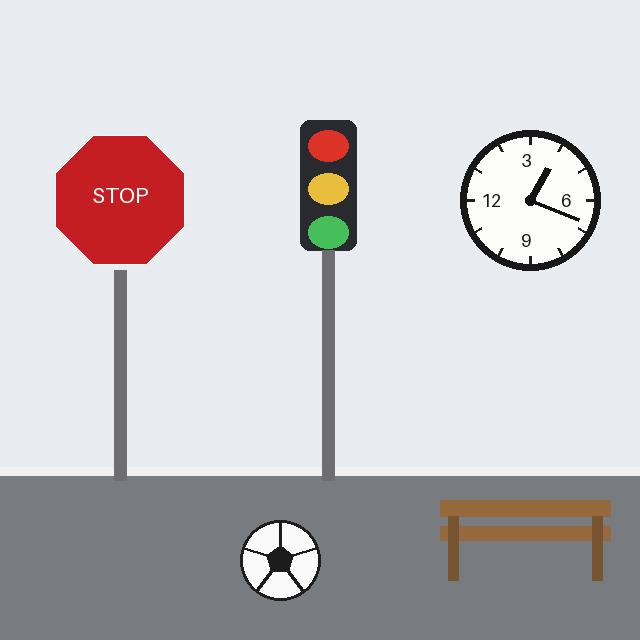

In [ ]:
import hashlib
import io
import json

threshold = 0.3  # @param {type:"number"}
nms_threshold = 0.3  # @param {type:"number"}

scene, references = tutorial_scene()
buffer = io.BytesIO()
scene.save(buffer, format='PNG')
print({'sample_kind': 'synthetic', 'size': list(scene.size), 'sha256': hashlib.sha256(buffer.getvalue()).hexdigest()[:16],
       'references': {label: len(boxes) for label, boxes in references.items()}})

input_manifest = validate_inputs(scene, threshold=threshold, nms_threshold=nms_threshold, names=['tutorial-scene'])
print({'verdict': input_manifest['verdict'], 'findings': input_manifest['findings'], 'inputs': input_manifest['inputs']})

coco_result = pipe.detect(scene, threshold=threshold, nms_threshold=nms_threshold)
for det in coco_result['detections']:
    print(f"{det['label']:>14s} {det['score']:.3f}  [{', '.join(f'{v:.0f}' for v in det['box'])}]")

coco_report = evaluation_report(coco_result, references, sample_kind='synthetic')
print({'verdict': coco_report['verdict'], 'n_detections': coco_report['n_detections']})
for metric in coco_report['metrics']:
    print(f"  {metric['reference']:>18s}  box_iou {metric['value']:.3f}  same-label detections {metric['n_detected_same_label']}")
hits = sum(1 for m in coco_report['metrics'] if m['value'] >= 0.5)
print(f'{hits}/{len(coco_report["metrics"])} drawn objects matched at IoU >= 0.5')
scene

**What to notice (Section 4):** the detections with their scores, one `box_iou` per drawn object, and the matched count.

<details><summary>Check your reasoning</summary>Four of five, in every recorded run: stop sign, traffic light, clock and bench at IoU 0.91–0.96. The drawn football is not proposed as a `sports ball` at all; the model offers `kite` and a second `clock` on that box. A flat, drawn ball has little of the texture a photographed one has. The report keeps the miss as a zero instead of dropping the reference, which is what makes the other four numbers believable.</details>

## 5. Two checks worth running once: channel order, and what it says about nothing · [Evaluation practice]

**Channel order.** Upstream reads images with `cv2.imread`, which yields **BGR**, and feeds that array to the network as raw 0–255 floats. It is an easy thing to get silently wrong, because RGB input still produces plausible-looking detections — it just produces worse ones. The cell below feeds the identical letterboxed tensor with the channels flipped so you can see the difference rather than take it on trust.

**Degenerate inputs.** A detector should be asked what it does with a blank page and with pure noise, because a model that invents confident objects on structure-free input will invent them on your input too.

**Predict before running:** with RGB instead of BGR, will the model find the same objects with the same scores, the same objects with lower scores, or fewer objects? And how many boxes will it return for a blank page at the demo thresholds?

In [ ]:
chw, ratio = preprocess(scene)
rgb_tensor = torch.from_numpy(chw[::-1].copy()).unsqueeze(0).to(pipe.device)
with torch.no_grad():
    rgb_raw = pipe.model(rgb_tensor)
rgb_kept = postprocess(rgb_raw, len(LABELS), conf_thre=threshold, nms_thre=nms_threshold)[0]
rgb_detections = sorted(
    ([LABELS[int(row[6])], float(row[4] * row[5])] for row in (rgb_kept.tolist() if rgb_kept is not None else [])),
    key=lambda pair: -pair[1],
)
print('BGR (upstream order):', [(d['label'], round(d['score'], 3)) for d in coco_result['detections']])
print('RGB (the mistake)   :', [(label, round(score, 3)) for label, score in rgb_detections])

degenerate = {}
for name, image in (('blank', blank_scene()), ('noise', noise_scene(0))):
    demo = pipe.detect(image, threshold=threshold, nms_threshold=nms_threshold)['detections']
    lenient = pipe.detect(image, threshold=EVAL_DETECTION_THRESHOLD, nms_threshold=EVAL_NMS_THRESHOLD)['detections']
    degenerate[name] = {'at_demo_thresholds': len(demo), 'at_evaluation_thresholds': len(lenient),
                        'top': [(d['label'], round(d['score'], 3)) for d in lenient[:3]]}
print(json.dumps(degenerate, indent=2))

BGR (upstream order): [('stop sign', 0.962), ('traffic light', 0.863), ('clock', 0.855), ('bench', 0.545), ('kite', 0.369), ('clock', 0.309)]
RGB (the mistake)   : [('clock', 0.873), ('traffic light', 0.869), ('stop sign', 0.839), ('clock', 0.441), ('kite', 0.339)]
{
  "blank": {
    "at_demo_thresholds": 0,
    "at_evaluation_thresholds": 0,
    "top": []
  },
  "noise": {
    "at_demo_thresholds": 0,
    "at_evaluation_thresholds": 1,
    "top": [
      [
        "bear",
        0.073
      ]
    ]
  }
}


**What to notice (Section 5):** the BGR and RGB lines side by side, and the two degenerate counts.

<details><summary>Check your reasoning</summary>Fewer and weaker. In the hosted T4 evaluation of record (18 October 2026, commit `ad795d2`, notebook blob `5fe2ef5d`), as in the Colab T4 run of 10 October 2026 and on the reference CPU before it, RGB input returned 5 detections instead of 6: the stop sign fell from 0.962 to 0.839, the bench disappeared, and a spurious second clock rose from 0.309 to 0.441. Nothing crashes and the output still looks plausible, which is exactly why the channel order is easy to get silently wrong. The blank and noise images give no boxes at the demo thresholds; any box there would be a false positive by construction.</details>

## 6. Sample data for adaptation, a validation pool, and the validation stage · [Evaluation practice]

The detector above knows 80 COCO classes. Suppose you need three classes it does not have. `sign_dataset` draws a deterministic 40-image labelled set over `SIGN_CLASSES` — `stop-sign`, `yield-sign`, `speed-limit-sign` — with 1–3 signs per image at jittered positions, sizes and background tints, and returns exact boxes because it knows where it drew them.

**Keep the two vocabularies apart.** COCO's `stop sign` (with a space) is a class the *pretrained* model predicts; `stop-sign` (hyphenated) is a class in *your* vocabulary that only exists after adaptation. They are not the same label and the notebook never treats them as interchangeable. `yield-sign` and `speed-limit-sign` have no COCO counterpart at all.

**Three kinds of evaluation data, and why.** The same generator also draws a **validation pool** of 40 images from its own seed (`VALIDATION_POOL`, seed 1161). Validation is what chooses the fine-tuning configuration in Section 8, so its score is optimistic by construction. The 10 images split off in Section 7 are the **exposed development test**: an earlier grid chose this notebook's default configuration on them (`docs/release-verification.md`), so they are shown for continuity and decide nothing. A **fresh test** of 200 images from a third seed (fresh test 3, seed 1162, amendment 2) is scored in Section 9, and only when every pre-registered setting holds (`docs/yolox-preregistration.md`). Every pool is pinned by SHA-256 and checked disjoint by image and by box layout; they are still the same renderer drawing the same three shapes, so even the fresh test measures in-distribution generalisation on drawn signs.

`validate_dataset` is the validation stage for this path and applies exactly the ceilings `finetune` applies, so a dataset it accepts cannot be refused later: record shape, box geometry inside the image, labels drawn from the vocabulary, at most 50 boxes per image (the head's label tensor width), at most 200 images, at most 20 epochs. It returns a dataset manifest, and it reports a class with no boxes as a **finding rather than an error** — that dataset is trainable, but that class's head outputs will stay untrained and you should know before you spend the compute.

This is drawn data. A model fine-tuned on it learns these renderings; that is what a bounded tutorial adaptation is for, and it is why none of the numbers later is a claim about photographs of real signs.

{
  "class_names": [
    "stop-sign",
    "yield-sign",
    "speed-limit-sign"
  ],
  "n_images": 40,
  "n_boxes": 82,
  "boxes_per_class": {
    "stop-sign": 21,
    "yield-sign": 34,
    "speed-limit-sign": 27
  },
  "epochs": 10,
  "verdict": "accepted",
  "findings": [],
  "model_id": "Megvii-BaseDetection/YOLOX",
  "model_revision": "0.1.1rc0"
}

record shape expected by finetune: a mapping with 'image' (PIL.Image.Image), 'boxes' (list of xyxy pixel boxes in that image's own coordinates) and 'labels' (list of class names, one per box, drawn from class_names)
COCO classes the pretrained model knows : ['stop sign', 'clock']
adaptation vocabulary (not COCO)        : ['stop-sign', 'yield-sign', 'speed-limit-sign']
{'validation_images': 40, 'validation_boxes': 79, 'validation_seed': 1161}

first six images, and the labels of the first: ['yield-sign']


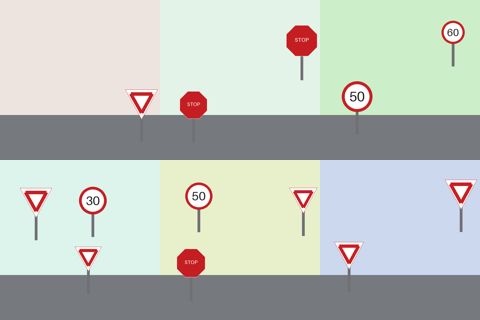

In [ ]:
N_IMAGES = 40  # @param {type:"integer"}
DATASET_SEED = 0  # @param {type:"integer"}

records = sign_dataset(N_IMAGES, seed=DATASET_SEED)
dataset_manifest = validate_dataset(records, SIGN_CLASSES, epochs=max(c['epochs'] for c in GRID))
print(json.dumps({k: v for k, v in dataset_manifest.items() if k != 'schema'}, indent=2))
print('\nrecord shape expected by finetune:', dataset_manifest['schema']['record'])
print('COCO classes the pretrained model knows :', [c for c in LABELS if 'sign' in c or c == 'clock'])
print('adaptation vocabulary (not COCO)        :', list(SIGN_CLASSES))

# The validation pool: its own seed, used only to choose the configuration in Section 8.
validation_records = sign_dataset(VALIDATION_POOL['n'], seed=VALIDATION_POOL['seed'])
validate_dataset(validation_records, SIGN_CLASSES)
print({'validation_images': len(validation_records), 'validation_boxes': sum(len(r['boxes']) for r in validation_records),
       'validation_seed': VALIDATION_POOL['seed']})

preview = Image.new('RGB', (480, 320))
for index, record in enumerate(records[:6]):
    preview.paste(record['image'].resize((160, 160)), (160 * (index % 3), 160 * (index // 3)))
print('\nfirst six images, and the labels of the first:', records[0]['labels'])
preview

## 7. Split, re-head, and measure the baseline *before* adapting · [Evaluation practice]

`split_records` is a seeded permutation into a training part (30 images) and a held-out part (10 images). The split happens before any weight is touched, and the held-out records are never shown to `finetune`. They are not an unbiased test, though: in September 2026 the repository chose the default epochs, learning rate and frozen backbone by a grid scored on held-out AP50 from this same split (four of these ten images were in that grid's held-out set, and three were its training images). So this notebook calls them the **exposed development test** and reports them for continuity only. The validation pool chooses the configuration, and the fresh test in Section 9 is the measurement.

`from_pretrained(class_names=...)` builds the same YOLOX-S and loads the same verified checkpoint, but rebuilds the classification branch for your vocabulary. It prints exactly which tensors it could not transfer — the three `head.cls_preds` weight/bias pairs, one per feature level — and everything else, including the whole backbone and the box and objectness heads, comes from the COCO checkpoint. The random initialisation is seeded, because those layers are the only untrained weights in the model and they are precisely what the baseline measures.

**The baseline is not zero, and that is the interesting part.** The classification head is random, but the box and objectness heads are COCO-trained and already know how to localise a sign-shaped thing, so the model scores some average precision by accident. Measuring it is what lets you say later that the fine-tune did something, rather than that a detector produced boxes. It is measured twice: on validation (the keep-baseline rule in Section 8 needs it) and on the exposed development test (for continuity).

**Predict before running:** will the baseline AP50 be near 0, near 0.2 or near 0.5? Which class could score by chance?

In [ ]:
HOLDOUT = 0.25  # @param {type:"number"}
SEED = 0  # @param {type:"integer"}

train_records, exposed_dev_test = split_records(records, holdout=HOLDOUT, seed=SEED)
print({'train': len(train_records), 'exposed_dev_test': len(exposed_dev_test), 'validation': len(validation_records),
       'train_boxes': sum(len(r['boxes']) for r in train_records),
       'exposed_dev_test_boxes': sum(len(r['boxes']) for r in exposed_dev_test)})

baseline_pipe = YoloxDetectionPipeline.from_pretrained(weights_dir=WEIGHTS_DIR, class_names=SIGN_CLASSES, seed=SEED)
print({'class_names': list(baseline_pipe.class_names), 'device': baseline_pipe.device, 'adapted': baseline_pipe.adapted})
print('tensors that could not transfer from the COCO checkpoint:')
for name in baseline_pipe.reinitialised:
    print('   ', name)
BASELINE_FINGERPRINT = baseline_pipe.state_fingerprint()


def _short(metrics):
    return {'ap': round(metrics['ap'], 4), 'ap50': round(metrics['ap50'], 4),
            'per_class_ap50': {k: round(v, 4) for k, v in metrics['per_class_ap50'].items()},
            'n_images': metrics['n_images'], 'n_references': metrics.get('n_references')}


baseline_val = baseline_pipe.evaluate(validation_records)
baseline = baseline_pipe.evaluate(exposed_dev_test)
print(json.dumps({'validation (chooses the configuration)': _short(baseline_val),
                  'exposed development test (descriptive only)': _short(baseline)}, indent=2))

{'train': 30, 'exposed_dev_test': 10, 'validation': 40, 'train_boxes': 61, 'exposed_dev_test_boxes': 21}


{'class_names': ['stop-sign', 'yield-sign', 'speed-limit-sign'], 'device': 'cuda:0', 'adapted': False}
tensors that could not transfer from the COCO checkpoint:
    head.cls_preds.0.bias
    head.cls_preds.0.weight
    head.cls_preds.1.bias
    head.cls_preds.1.weight
    head.cls_preds.2.bias
    head.cls_preds.2.weight


{
  "validation (chooses the configuration)": {
    "ap": 0.1767,
    "ap50": 0.1851,
    "per_class_ap50": {
      "stop-sign": 0.0554,
      "yield-sign": 0.0,
      "speed-limit-sign": 0.5
    },
    "n_images": 40,
    "n_references": 79
  },
  "exposed development test (descriptive only)": {
    "ap": 0.2083,
    "ap50": 0.2222,
    "per_class_ap50": {
      "stop-sign": 0.0,
      "yield-sign": 0.0,
      "speed-limit-sign": 0.6667
    },
    "n_images": 10,
    "n_references": 21
  }
}


**What to notice (Section 7):** the split sizes, the six re-initialised `head.cls_preds` tensors, and the two baseline scores.

<details><summary>Check your reasoning</summary>On the exposed development test every recorded run, including the hosted T4 evaluation of record (18 October 2026, commit `ad795d2`, notebook blob `5fe2ef5d`), measured AP 0.2083 and AP50 0.2222, with per-class AP50 stop 0.0, yield 0.0 and speed-limit 0.667. The box and objectness heads already find sign-shaped things; the random class head happens to rank the speed-limit boxes well. A non-zero baseline is the floor the fine-tune must beat, not something it achieved. On validation (40 images, 79 boxes) the same run measured the baseline at AP 0.1767 and AP50 0.1851 (per-class AP50 stop 0.0554, yield 0.0, speed-limit 0.5); that is the number the keep-baseline rule compares against.</details>

## 8. The bounded SimOTA fine-tune, and a pre-registered validation grid · [Concept]

This is the cell that makes the notebook an `E2E` tutorial rather than an inference demo, and it runs in the default path.

The loss and the label assignment are **upstream's**, in the carried `yolo_head` module: put the head in training mode, hand it images and a `(class, cx, cy, w, h)` target tensor, and it runs SimOTA — building an IoU-and-classification cost between every ground-truth object and every candidate anchor point, picking a dynamic number of positives per object, and returning the IoU, objectness and classification terms already weighted. What this repository owns is the bounded loop around it: the target conversion, batching, the optimiser, the seed and the ceilings.

**Which configuration, and who chose it.** The September 2026 defaults (six epochs at 1e-3, frozen backbone) were chosen on the split Section 7 now calls exposed. This cell instead runs the grid fixed in `docs/yolox-preregistration.md` and chooses on validation only:

| Config | Epochs | Learning rate |
|---|---|---|
| C0 (the default) | 6 | 1e-3 |
| C1 | 10 | 1e-3 |
| C2 | 8 | 2e-3 |

A challenger replaces C0 only if its validation AP@[.50:.95] is at least 0.03 higher and its AP50 at most 0.02 lower; if both qualify the larger gain wins, and ties go to the smaller config. Then the **keep-baseline rule**: the adapted model replaces the pretrained baseline only if it beats the baseline's validation AP by at least 0.03. With a GPU the grid runs by default (`RUN_GRID = "auto"`; in the T4 evaluation of record the three fine-tunes took 19.8 s together). On a CPU it is off by default: the cell trains only the recorded selection, C1 (10 epochs at learning rate 1e-3, chosen by the hosted T4 evaluation of record of 18 October 2026). **Only a T4 run can be the pre-registered evaluation** (amendment 1, `docs/yolox-preregistration-amendment-1.md`): on a CPU, or on any other GPU, the run is **exploratory** whatever `RUN_GRID` says, and Section 9 shows validation and the exposed development test but never scores the fresh test.

**What decides in practice.** In every recorded look all three configs reach validation AP50 1.0, so the AP50 guard decides nothing here and only AP@[.50:.95] decides. The 0.03 margin is a practical tolerance at the T4 noise floor (two T4 runs of C0 differed by 0.064 AP on ten images), not a significance test. Until amendment 2, CUDA training was not deterministic: a hosted reproduction (116b) selected C0 where the record selected C1. Section 8 now switches on deterministic kernels before training (`enable_determinism`: cuDNN deterministic, no benchmark, `torch.use_deterministic_algorithms(True)` without `warn_only`, `CUBLAS_WORKSPACE_CONFIG=:4096:8`, seeded torch/numpy/random) and prints a **grid hash**; two runs on a T4 must print the same hash before a new run of record is accepted. An op with no deterministic CUDA kernel stops the cell instead of running.

- **The backbone is frozen.** Only the head trains (~1.9 M of 8.9 M parameters). It is several times faster per step, and the September grid found that unfreezing it at 1e-3 *collapsed* the model to AP 0.0 on its held-out split — a handful of gradient steps on 30 small images is enough to destroy COCO-pretrained features. That was a held-out observation, so treat it as a lesson about step size, not a measured guarantee. The frozen backbone is also kept in eval mode so its BatchNorm running statistics are not quietly rewritten by tutorial batches.
- **The L1 box term stays off.** Upstream enables it only for the last 15 of 300 epochs; switching it on for a short run would change the loss scale for no benefit. You will see `l1_loss` report 0.0 throughout, and that is correct.

Watch `total_loss` fall and `num_fg` — the number of anchor points SimOTA assigned as positives per image — stay stable. A `num_fg` collapsing toward zero would mean the assignment had stopped finding anything to match.

**Every run of this cell starts from the verified base.** Each configuration rebuilds its model with `from_pretrained(class_names=SIGN_CLASSES, seed=SEED)` — the same COCO weights and, under the same seed, the same re-initialised classification layers the Section 7 baseline measured — so re-running the cell after changing a field trains from the start, never on top of an already adapted model. The cell first clears the previous run's selection, so an interrupted run leaves nothing Section 9 could score. Each grid row is written to `outputs/grid/run_<k>/` as it finishes, one folder per execution of this cell.

**Predict before running:** over six epochs, roughly how far will C0's `total_loss` fall, and will `num_fg` stay near 8? Will a longer or faster schedule beat C0 by 0.03 validation AP?

In [ ]:
RUN_GRID = "auto"  # @param ["auto", "on", "off"]
BATCH_SIZE = 2  # @param {type:"integer"}
FREEZE_BACKBONE = True  # @param {type:"boolean"}

import os
import time
from pathlib import Path

OUTPUTS = Path('outputs')
os.makedirs('outputs', exist_ok=True)
# Amendment 1 (A2): clear the previous run's state first, so an interrupted run leaves nothing Section 9 can use.
grid_status = {'complete': False, 'problems': ['Section 8 did not finish']}
selection = adapter = selected_pipe = run = None
grid_rows, grid_models = {}, {}
GRID_RUN = globals().get('GRID_RUN', 0) + 1
GRID_DIR = OUTPUTS / 'grid' / f'run_{GRID_RUN}'
GRID_ON = RUN_GRID == 'on' or (RUN_GRID == 'auto' and torch.cuda.is_available())
DEVICE_CLASS = device_class(torch)
DEVICE_NAME = torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'cpu'
settings_now = {
    'data_source': 'sample', 'n_images': N_IMAGES, 'dataset_seed': DATASET_SEED, 'holdout': HOLDOUT, 'split_seed': SEED,
    'training_digest': pool_digest(train_records), 'validation_pool': dict(VALIDATION_POOL),
    'validation_digest': pool_digest(validation_records), 'fresh_test_pool': dict(FRESH_TEST_POOL),
    'fresh_test_digest': FRESH_TEST_DIGEST, 'batch_size': BATCH_SIZE, 'adapt_seed': SEED, 'freeze_backbone': FREEZE_BACKBONE,
    'eval_threshold': EVAL_DETECTION_THRESHOLD, 'eval_nms_threshold': EVAL_NMS_THRESHOLD,
    'max_detections': MAX_EVAL_DETECTIONS, 'iou_thresholds': [float(t) for t in COCO_IOU_THRESHOLDS],
    'grid': [dict(c) for c in GRID], 'run_grid': GRID_ON, 'min_ap_gain': MIN_AP_GAIN, 'max_ap50_drop': MAX_AP50_DROP,
    'keep_baseline_gain': KEEP_BASELINE_GAIN, 'device_class': DEVICE_CLASS,
}
# Amendment 2 (B1): deterministic kernels and seeded torch/numpy/random BEFORE any training; never warn_only.
DETERMINISM = enable_determinism(torch, SEED)
settings_now['determinism'] = DETERMINISM
print('determinism:', DETERMINISM)
data_digests = {'training': settings_now['training_digest'], 'validation': settings_now['validation_digest']}
configs = GRID if GRID_ON else tuple(c for c in GRID if c['name'] == RECORDED_SELECTION)
print(f"device {DEVICE_NAME} ({DEVICE_CLASS}); grid {'ON' if GRID_ON else 'OFF'}: training {[c['name'] for c in configs]}"
      + ('' if GRID_ON else ' (the recorded selection only, so this run is exploratory)')
      + ('' if DEVICE_CLASS == 'cuda-t4' else '; not a T4, so this run is exploratory'))

for config in configs:
    started = time.perf_counter()
    try:
        # YXD-m2: every config starts from the verified base and the same seeded head the baseline measured.
        candidate = YoloxDetectionPipeline.from_pretrained(weights_dir=WEIGHTS_DIR, class_names=SIGN_CLASSES, seed=SEED)
        candidate_run = candidate.finetune(
            train_records,
            epochs=config['epochs'],
            batch_size=BATCH_SIZE,
            learning_rate=config['learning_rate'],
            seed=SEED,
            freeze_backbone=FREEZE_BACKBONE,
            progress=lambda row, name=config['name'], total=config['epochs']: print(
                f"{name} epoch {row['epoch']}/{total}  total {row['total_loss']:.4f}  iou {row['iou_loss']:.4f}  "
                f"conf {row['conf_loss']:.4f}  cls {row['cls_loss']:.4f}  l1 {row['l1_loss']:.4f}  num_fg {row['num_fg']:.2f}"
            ),
        )
        candidate_val = candidate.evaluate(validation_records)
        row = config_record(config, candidate_run, candidate_val, digests=data_digests, fingerprint=candidate.state_fingerprint())
        grid_models[config['name']] = (candidate, candidate_run)
    except (RuntimeError, ValueError, MemoryError) as exc:
        if is_determinism_error(exc):
            raise RuntimeError(f"{config['name']}: an op has no deterministic CUDA kernel; STOP and report it "
                               f'(amendment 2 forbids warn_only): {exc}') from exc
        row = config_record(config, None, None, digests=data_digests, error=f'{type(exc).__name__}: {exc}')
    row['finetune_seconds'] = round(time.perf_counter() - started, 1)
    grid_rows[config['name']] = row
    atomic_write_json(GRID_DIR / f"{config['name']}.json", row)
    print({k: row.get(k) for k in ('name', 'status', 'val_ap', 'val_ap50', 'final_total_loss', 'finetune_seconds', 'error')})

GRID_HASH = grid_hash(grid_rows)
print(f'grid hash {GRID_HASH}  (two deterministic runs print the same hash)')
grid_status = grid_check(grid_rows, settings_now, data_digests)
if not grid_models:
    raise RuntimeError('no grid configuration completed: ' + '; '.join(grid_status['problems']))
selection = select_config(grid_rows, baseline_val['ap'])
adapter, run = grid_models[selection['selected_config']]
selected_pipe = baseline_pipe if selection['selected_system'] == BASELINE_SYSTEM else adapter
FINETUNE_SECONDS = grid_rows[selection['selected_config']]['finetune_seconds']
if selected_pipe is baseline_pipe:
    print('The keep-baseline rule kept the pretrained baseline (a negative result): Sections 10-11 use and export the '
          'baseline, not the rejected adapted config.')
print(json.dumps({'grid_complete': grid_status['complete'], 'problems': grid_status['problems'],
                  'selected_config': selection['selected_config'], 'selected_system': selection['selected_system'],
                  'reason': selection['reason'], 'keep_baseline_rule': selection['keep_baseline_rule']}, indent=2))
print(json.dumps({'optimizer': run['optimizer'], 'loss': run['loss'], 'use_l1': run['use_l1'],
                  'freeze_backbone': run['freeze_backbone'], 'trainable_parameters': run['trainable_parameters'],
                  'total_parameters': run['total_parameters'], 'epochs': run['epochs'], 'batch_size': run['batch_size'],
                  'learning_rate': run['learning_rate'], 'seed': run['seed']}, indent=2))
first, last = run['history'][0]['total_loss'], run['history'][-1]['total_loss']
print(f"{selection['selected_config']}: total_loss {first:.4f} -> {last:.4f} over {run['epochs']} epochs in {FINETUNE_SECONDS} s")

determinism: {'cublas_workspace_config': ':4096:8', 'cudnn_deterministic': True, 'cudnn_benchmark': False, 'deterministic_algorithms': True, 'warn_only': False}
device Tesla T4 (cuda-t4); grid ON: training ['C0', 'C1', 'C2']


<isolated cell 9>:488: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=False):


C0 epoch 1/6  total 6.2880  iou 1.6569  conf 2.5065  cls 2.1246  l1 0.0000  num_fg 8.21


C0 epoch 2/6  total 3.7558  iou 1.7774  conf 1.1950  cls 0.7834  l1 0.0000  num_fg 7.87


C0 epoch 3/6  total 2.8003  iou 1.4016  conf 0.7617  cls 0.6370  l1 0.0000  num_fg 8.08


...

C2 epoch 5/8  total 2.3578  iou 1.2288  conf 0.6629  cls 0.4661  l1 0.0000  num_fg 8.02


C2 epoch 6/8  total 2.2845  iou 1.2774  conf 0.5520  cls 0.4551  l1 0.0000  num_fg 8.08


C2 epoch 7/8  total 1.8787  iou 1.0071  conf 0.4782  cls 0.3934  l1 0.0000  num_fg 8.44


C2 epoch 8/8  total 1.6945  iou 0.8995  conf 0.4358  cls 0.3592  l1 0.0000  num_fg 8.73


{'name': 'C2', 'status': 'complete', 'val_ap': 0.8296297020369339, 'val_ap50': 1.0, 'final_total_loss': 1.69447, 'finetune_seconds': 6.7, 'error': None}
grid hash 184785885a816d4becfec2789c796d112be29dbe5f5b4760f2ab7fdb39753793  (two deterministic runs print the same hash)
{
  "grid_complete": true,
  "problems": [],
  "selected_config": "C1",
  "selected_system": "C1",
  "reason": "C1 beat C0 by 0.1900 validation AP (margin 0.03) with AP50 at most 0.02 lower",
  "keep_baseline_rule": "C1 beats the pretrained baseline by 0.7170 validation AP (>= 0.03): the adapted model is the selected system"
}
{
  "optimizer": "SGD(momentum=0.9, weight_decay=5e-4)",
  "loss": "upstream YOLOXHead SimOTA (IoU + objectness + classification)",
  "use_l1": false,
  "freeze_backbone": true,
  "trainable_parameters": 1891096,
  "total_parameters": 8938456,
  "epochs": 10,
  "batch_size": 2,
  "learning_rate": 0.001,
  "seed": 0
}
C1: total_loss 6.2880 -> 1.5216 over 10 epochs in 8.2 s


**What to notice (Section 8):** one line per epoch per config, `l1` at 0.0, `num_fg` steady, each config's validation AP, and the selection with its reason.

<details><summary>Check your reasoning</summary>In the hosted T4 evaluation of record (18 October 2026, commit `ad795d2`, notebook blob `5fe2ef5d`), the selected C1's `total_loss` fell from 6.288 to 1.384 over ten epochs (C0: 6.288 to 1.876 over six) and `num_fg` stayed between 7.9 and 8.9: SimOTA kept finding about eight positives per image. Only 1.9 M of 8.9 M parameters trained. Validation AP@[.50:.95] was 0.6966 for C0, 0.8554 for C1 and 0.7122 for C2, with AP50 1.0 for all three. C1 beat C0 by 0.1587, above the 0.03 margin; C2 beat it by only 0.0155. Only C1 qualified, so C1 was selected, and it beat the baseline's 0.1767 by 0.6786, so the adapted C1 is the selected system. C0 and C1 share a seed and their first epoch is identical, but on the T4 their losses split at epoch 2 (3.7556 against 3.7558): CUDA kernels were not deterministic then: the reproduction 116b selected C0 (C0 0.8624, C1 0.8818), which is why amendment 2 makes training deterministic and adds fresh test 3. C2's loss rose in its last two epochs (1.872, 2.089, 2.602). A falling loss shows the head fits the 30 training images; whether that transfers is Section 9's question.</details>

## 9. Evaluate: validation, the exposed development test, and the fresh test · [Evaluation practice]

The same `evaluate` call as the baseline, with the same thresholds, so the numbers are comparable and the only thing that changed is the weights.

`ap50` is average precision at IoU 0.50; `ap` is COCO's primary metric, AP@[.50:.95], the mean over ten IoU thresholds from 0.50 to 0.95 — it is always lower, because it demands progressively tighter boxes. Evaluation uses the *evaluation* thresholds (`0.01 / 0.65`) rather than the demo pair, since average precision rewards recall, and caps detections at 100 per image as COCO does. Tied scores are one operating point, so a result never depends on the order of the images.

**Before the fresh test is touched,** the cell re-checks four things: every pre-registered setting (`preregistered_differences`, over all of them, including that the device is a T4), that the grid of *this* Section 8 run is complete and ran with those settings (recomputed here, never taken from memory), that the models in hand are the selected system and the baseline (by state fingerprint), and that the 200 generated images match their committed digest. If all hold, it scores the fresh test. The evaluation of record already exists (the hosted T4 run of 18 October 2026, carried as `RECORDED_EVALUATION`), so every such scoring, your first included, is labelled `reproduction`, is written to `_reproduction_<n>` files that never overwrite the main ones, and prints whether it matches the record. The per-image results (each image's boxes and what each system found, plus the match tables the bootstrap resamples) are saved beside the report, so a reproduction's interval can be re-checked without re-running the model. Anything else is `not scored (exploratory)`, written to `_exploratory_<n>` files, and the cell says why. `docs/release-verification.md` records which hosted run is the evaluation of record.

**Reading rule.** The primary endpoint is fresh-test AP@[.50:.95], selected system minus baseline, with a paired 95 % bootstrap interval over images (10 000 resamples, fixed seed). The verdict is *improved* only if the interval's lower bound is above 0 and the gain is at least 0.03; *worse* if its upper bound is below 0; otherwise *no detectable difference*. AP50 is secondary because it saturates. The baseline's classification layers are untrained, so an *improved* verdict is expected; the informative parts are the size of the gain, the width of the interval, and that it held on images no choice was made on.

What these numbers are: evidence that a bounded fine-tune on 30 drawn images moved a score on drawn images it never trained on. What they are not: these are not a detection benchmark. Every pool comes from the same generator with the same three shapes, so a high fresh-test AP says the task is easy and the adaptation worked on renderings — not that the model would find a real sign in a real photograph.

Every run of Sections 8–9 is appended to `run_history` with its validation scores and its `test_look`, so the activity at the end (Section 14) compares settings on validation, never on the fresh test.

**Predict before running:** on the exposed development test, will C0's AP50 be near 0.5, near 0.9 or 1.0? And AP@[.50:.95]?

In [ ]:
import os

if selection is None or adapter is None:
    raise RuntimeError('Section 8 did not finish (interrupted or failed), so there is no selected system. '
                       'Run Section 8 again, then this cell. Nothing was scored.')
adapter_val = adapter.evaluate(validation_records)
selected_val = baseline_val if selected_pipe is baseline_pipe else adapter_val
adapted = adapter.evaluate(exposed_dev_test)
print(f"validation AP@[.50:.95]: baseline {baseline_val['ap']:.4f}, {selection['selected_config']} {adapter_val['ap']:.4f}"
      f" -> selected system: {selection['selected_system']}")
print('\nexposed development test (10 images, scored by the September 2026 grid; descriptive only, decides nothing):')
print(f"{'metric':<10s} {'baseline':>10s} {'adapted':>10s} {'change':>10s}")
for key in ('ap', 'ap50'):
    print(f'{key:<10s} {baseline[key]:>10.4f} {adapted[key]:>10.4f} {adapted[key] - baseline[key]:>+10.4f}')
print('implementation note:', adapted['implementation'])

# Before the fresh test is touched, re-check every pre-registered setting, the grid, the models in hand and the pool.
differences = preregistration_differences(settings_now)
# Amendment 1 (A2): recompute from this Section 8 run's rows; never trust a status or selection left in memory.
grid_status = grid_check(grid_rows, settings_now, data_digests)
selection_matches_grid = (selection['selected_config'] in grid_rows  # all three configs: grid_check
                          and selection['fingerprint'] == grid_rows.get(selection['selected_config'], {}).get('fingerprint')
                          and adapter.state_fingerprint() == selection['fingerprint'])
expected_fingerprint = BASELINE_FINGERPRINT if selected_pipe is baseline_pipe else selection['fingerprint']
state_matches = (selection_matches_grid and selected_pipe.state_fingerprint() == expected_fingerprint
                 and baseline_pipe.state_fingerprint() == BASELINE_FINGERPRINT)
masked = os.environ.get('DIMER_MASK_FRESH_TEST') == '1'
fresh_records, fresh_digest_ok = None, None
if not differences and grid_status['complete'] and state_matches and not masked:
    try:
        fresh_records = sign_dataset(FRESH_TEST_POOL['n'], seed=FRESH_TEST_POOL['seed'])
        fresh_digest_ok = pool_digest(fresh_records) == FRESH_TEST_DIGEST
    except (ValueError, OSError, MemoryError) as exc:
        print(f'The fresh test could not be generated ({type(exc).__name__}: {exc}).')
        fresh_digest_ok = False
    if not fresh_digest_ok:
        print('The generated fresh test does not match its committed digest, so this runtime did not draw the pinned '
              'images (a different Pillow build can do this). This run is exploratory and the fresh test is not scored.')
        fresh_records = None
mode = scoring_mode(differences=differences, grid=grid_status, state_matches=state_matches,
                    fresh_digest_ok=fresh_digest_ok, masked=masked)
reasons = (([f'settings differ from the pre-registration: {differences}'] if differences else [])
           + grid_status['problems']
           + ([] if state_matches else ['the model in hand is not the selected system of this Section 8 run'])
           + (['the fresh pool failed its digest check'] if fresh_digest_ok is False else [])
           + (['DIMER_MASK_FRESH_TEST=1 (a development check)'] if masked else []))
ledger = LookLedger(OUTPUTS / 'work' / 'look_ledger.json', OUTPUTS, 'yolox_detection')
test_look, suffix = ledger.plan(mode, RECORDED_EVALUATION)
evaluation_report = {
    'test_look': test_look, 'scoring_mode': mode, 'preregistered': mode == 'preregistered',
    'preregistered_settings_hold': not differences, 'settings_differing': differences, 'reasons': reasons,
    'masked': masked, 'device': {'class': DEVICE_CLASS, 'name': DEVICE_NAME}, 'grid_dir': str(GRID_DIR),
    'determinism': DETERMINISM, 'grid_hash': GRID_HASH, 'fresh_test_pool': dict(FRESH_TEST_POOL),
    'grid': grid_status, 'grid_rows': grid_rows, 'selection': selection,
    'recorded_evaluation': RECORDED_EVALUATION, 'notebook': NOTEBOOK_SOURCE,
    'validation': {'baseline': _short(baseline_val), 'selected_config': _short(adapter_val)},
    'exposed_development_test': {'descriptives_decide_nothing': True, 'baseline': _short(baseline), 'adapted': _short(adapted)},
    'fresh_test': None,
}
if mode == 'preregistered':
    selected_fresh = selected_pipe.evaluate(fresh_records, keep_matches=True)
    baseline_fresh = baseline_pipe.evaluate(fresh_records, keep_matches=True)
    same_model = selected_pipe is baseline_pipe
    boot = None if same_model else paired_bootstrap(selected_fresh['matches'], baseline_fresh['matches'])
    evaluation_report['fresh_test'] = {
        'pool': dict(FRESH_TEST_POOL), 'digest': FRESH_TEST_DIGEST, 'selected_system': selection['selected_system'],
        'selected': _short(selected_fresh), 'baseline': _short(baseline_fresh), 'bootstrap': boot,
        'verdict': reading_verdict(boot, same_model=same_model),
        'tied_score_groups': {'selected': selected_fresh['tied_score_groups'], 'baseline': baseline_fresh['tied_score_groups']},
    }
    # Display only: the per-image results and the match tables, so a reproduction's bootstrap can be re-checked.
    per_image_rows = per_image_summary(selected_fresh['matches'], baseline_fresh['matches'])
    per_image_path = OUTPUTS / f'yolox_detection_fresh_test_per_image{suffix}.json'
    atomic_write_json(per_image_path, {
        'test_look': test_look, 'bootstrap': None if boot is None else {k: boot[k] for k in ('n_boot', 'seed', 'resampling_unit')},
        'per_image': per_image_rows,
        'matches': {'selected': matches_to_json(selected_fresh['matches']), 'baseline': matches_to_json(baseline_fresh['matches'])},
    })
    evaluation_report['fresh_test']['per_image_file'] = str(per_image_path)
    evaluation_report['record_comparison'] = compare_with_record(RECORDED_EVALUATION, evaluation_report['fresh_test'], selection)
report_path = OUTPUTS / f'yolox_detection_evaluation_report{suffix}.json'
atomic_write_json(report_path, evaluation_report)
ledger.record(mode, suffix)  # a look counts only once its report is on disk
print({'test_look': test_look, 'written': str(report_path)})
if evaluation_report['fresh_test'] is not None:
    fresh = evaluation_report['fresh_test']
    print(json.dumps({'selected': fresh['selected'], 'baseline': fresh['baseline'], 'verdict': fresh['verdict'],
                      'ap_difference': None if fresh['bootstrap'] is None else round(fresh['bootstrap']['primary_ap_difference'], 4),
                      'ci95': None if fresh['bootstrap'] is None else [round(v, 4) for v in fresh['bootstrap']['primary_ap_ci95']]},
                     indent=2))
    complete = {name: sum(r[name]['true_positives_iou0.5'] == r['references'] for r in per_image_rows) for name in ('selected', 'baseline')}
    print(f"per-image results for {len(per_image_rows)} images written to {per_image_path}; every box found at IoU 0.5 on "
          f"{complete['selected']} images (selected) and {complete['baseline']} (baseline)")
    comparison = evaluation_report.get('record_comparison')
    if comparison is not None:
        print('reproduction of the pre-registered evaluation of', comparison['record']['date'],
              f"(commit {comparison['record']['commit'][:7]}):",
              'matches the record' if comparison['matches'] else f"differs from the record in {comparison['differing']}")
        if not comparison['matches']:
            print(json.dumps({k: comparison['fields'][k] for k in comparison['differing']}))
else:
    print('fresh test not scored:', '; '.join(reasons) or test_look)

run_history = globals().get('run_history', [])
run_history.append({'freeze_backbone': FREEZE_BACKBONE, 'batch_size': BATCH_SIZE, 'grid_on': GRID_ON,
                    'selected_config': selection['selected_config'], 'val_ap': round(adapter_val['ap'], 4),
                    'val_ap50': round(adapter_val['ap50'], 4), 'finetune_seconds': FINETUNE_SECONDS, 'test_look': test_look})
for number, row in enumerate(run_history, start=1):
    print(f'run {number}:', row)

validation AP@[.50:.95]: baseline 0.1767, C1 0.8937 -> selected system: C1

exposed development test (10 images, scored by the September 2026 grid; descriptive only, decides nothing):
metric       baseline    adapted     change
ap             0.2083     0.9043    +0.6960
ap50           0.2222     1.0000    +0.7778
implementation note: package-local average_precision: COCO matching and 101-point interpolation, tied scores as one operating point, without pycocotools' area ranges or crowd handling — not comparable to published COCO numbers


{'test_look': 'pre-registered evaluation (this runtime)', 'written': 'outputs/yolox_detection_evaluation_report.json'}
{
  "selected": {
    "ap": 0.8933,
    "ap50": 1.0,
    "per_class_ap50": {
      "stop-sign": 1.0,
      "yield-sign": 1.0,
      "speed-limit-sign": 1.0
    },
    "n_images": 200,
    "n_references": 386
  },
  "baseline": {
    "ap": 0.1317,
    "ap50": 0.1388,
    "per_class_ap50": {
      "stop-sign": 0.0219,
      "yield-sign": 0.0,
      "speed-limit-sign": 0.3944
    },
    "n_images": 200,
    "n_references": 386
  },
  "verdict": "improved",
  "ap_difference": 0.7616,
  "ci95": [
    0.7381,
    0.782
  ]
}
per-image results for 200 images written to outputs/yolox_detection_fresh_test_per_image.json; every box found at IoU 0.5 on 200 images (selected) and 35 (baseline)
run 1: {'freeze_backbone': True, 'batch_size': 2, 'grid_on': True, 'selected_config': 'C1', 'val_ap': 0.8937, 'val_ap50': 1.0, 'finetune_seconds': 8.2, 'test_look': 'pre-registered evaluation

**What to notice (Section 9):** the validation scores, the exposed-development-test table, and the fresh-test result or the reason it was not scored.

<details><summary>Check your reasoning</summary>In the hosted T4 evaluation of record (18 October 2026, commit `ad795d2`, notebook blob `5fe2ef5d`), the selected C1 scored AP 0.8516 and AP50 1.0 on the exposed development test (baseline 0.2083 and 0.2222). For C0, AP50 was 1.0 in every recorded run and AP@[.50:.95] 0.7766 in the Colab T4 run of 10 October 2026 (commit `2c3d8bc`, notebook blob `fe56cb69`, configuration C0); earlier revisions recorded 0.8110 (reference CPU) and 0.8403 (Kaggle T4), both on 15 September 2026 with an earlier notebook revision. The AP50 is saturated: ten images from the training generator are too easy to separate a good adapter from a perfect one. The AP@[.50:.95] spread between the two T4 records (0.064 on the same ten images) is run-to-run and revision-to-revision variation, not a device effect, and it is why the grid margin is 0.03 and the fresh test has 200 images. On the fresh test (200 images, 399 boxes) the evaluation of record measured the selected C1 at AP 0.8573 (AP50 1.0) against the baseline's 0.1363 (AP50 0.1449): a gain of +0.7211 with a paired bootstrap 95 % interval of [0.6983, 0.7435], so the verdict is *improved*, and the interval's half-width is 0.0226. A large gain was expected because the baseline's classification layers are untrained. Your own run with the same settings is a reproduction, and Section 9 prints whether it matches the record.</details>

## 10. Inference on new data · [Concept]

The exposed development test was drawn from the same seed as the training set. These three images come from seed 99, which no pool uses, so their layouts, sizes, tints and sign choices were never part of any split. They are a picture of the selected model at work, viewed in every run, and they decide nothing.

The detections use the **demo thresholds** again, because this is the "what would I actually deploy" view rather than the scoring view. Each detection is checked against the drawn truth with `box_iou` on the same label.

**Predict before running:** how many of the five signs on the three new images will be found with the right label?

{"image": 0, "truth": ["yield-sign", "yield-sign"], "detections": [["yield-sign", 0.909], ["yield-sign", 0.882]], "same_label_iou": [0.935, 0.955]}
{"image": 1, "truth": ["speed-limit-sign", "yield-sign"], "detections": [["yield-sign", 0.9], ["speed-limit-sign", 0.875]], "same_label_iou": [0.929, 0.947]}
{"image": 2, "truth": ["stop-sign"], "detections": [["stop-sign", 0.907]], "same_label_iou": [0.891]}


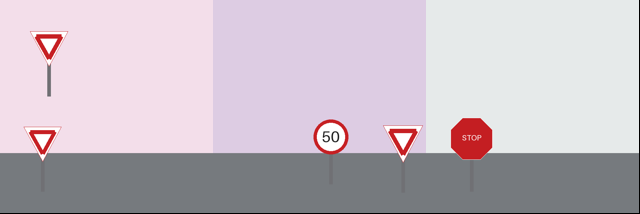

In [ ]:
NEW_DATA_SEED = 99  # @param {type:"integer"}

if selected_pipe is baseline_pipe:
    print('The keep-baseline rule kept the pretrained baseline, so these detections come from the baseline, not from an adapted model.')
new_records = sign_dataset(3, seed=NEW_DATA_SEED)
new_data_rows = []
for index, record in enumerate(new_records):
    out = selected_pipe.detect(record['image'], threshold=threshold, nms_threshold=0.45)
    ious = []
    for box, label in zip(record['boxes'], record['labels'], strict=True):
        same_label = [d for d in out['detections'] if d['label'] == label]
        ious.append(round(max((box_iou(d['box'], box) for d in same_label), default=0.0), 3))
    row = {'image': index, 'truth': record['labels'],
           'detections': [(d['label'], round(d['score'], 3)) for d in out['detections']],
           'same_label_iou': ious}
    new_data_rows.append(row)
    print(json.dumps(row))

contact = Image.new('RGB', (640, 214))
for index, record in enumerate(new_records):
    contact.paste(record['image'].resize((213, 213)), (213 * index, 0))
contact

**What to notice (Section 10):** one row per image with the truth, the detections and the same-label IoU.

<details><summary>Check your reasoning</summary>All five, with the right labels, same-label IoU 0.881–0.942 and no spurious boxes, in the hosted T4 evaluation of record (18 October 2026, commit `ad795d2`, notebook blob `5fe2ef5d`, selected configuration C1). The Colab T4 run of 10 October 2026 (configuration C0) also found all five, at IoU 0.82–0.93. That is encouraging for drawn signs from an unseen seed, but they come from the same generator: same shapes, same colours, same rendering. It is not evidence about photographs.</details>

## 11. Export the artifact, then reload it as if from a cold start · [Engineering]

`save_artifact` writes one file for the **selected system**: normally the adapted `state_dict` of the selected configuration, or, if the keep-baseline rule kept the pretrained baseline, that baseline (the rejected adapted config is not shipped as the result). The file holds the weights plus the metadata needed to rebuild the model — the format tag, the pinned model identity, the upstream code revision, the class vocabulary, the architecture constants and the digest of the base weights it started from. It is written to a temporary file and renamed, so an interrupted save never leaves half a file. It is a plain `torch.save` of tensors and simple values, with no archive to extract and nothing that requires `weights_only=False` to read back.

`load_artifact` is the fresh-reload check: it rebuilds the model from the file alone, without reference to the model object still in memory, and refuses an artifact whose format tag or pinned identity does not match this package. The cell then re-scores the **validation** pool with the reloaded model and asserts the numbers are identical — a reload that quietly lost the adaptation would show up here as a different AP, and the assertion would stop the notebook. The reload never touches the fresh test.

The last part of the cell tampers with a copy of the artifact and confirms it is refused, because "it loads" is only evidence if something that should not load is also tried.

In [ ]:
artifact_path = OUTPUTS / ARTIFACT_FILE
descriptor = selected_pipe.save_artifact(artifact_path, notes=f"standalone tutorial run; selected system {selection['selected_system']}")
print(json.dumps({k: v for k, v in descriptor.items() if k != 'base_state_digest'}, indent=2))

reloaded = YoloxDetectionPipeline.load_artifact(artifact_path)
print({'source': reloaded.source, 'class_names': list(reloaded.class_names), 'adapted': reloaded.adapted})
reloaded_metrics = reloaded.evaluate(validation_records)
print({'reloaded_val_ap': round(reloaded_metrics['ap'], 4), 'reloaded_val_ap50': round(reloaded_metrics['ap50'], 4)})
assert abs(reloaded_metrics['ap'] - selected_val['ap']) < 1e-9, 'the reloaded artifact does not reproduce the selected score'
assert abs(reloaded_metrics['ap50'] - selected_val['ap50']) < 1e-9
print(f"fresh reload reproduces the validation scores of the selected system ({selection['selected_system']}) exactly")

tampered = OUTPUTS / 'tampered-artifact.pt'
payload = torch.load(artifact_path, map_location='cpu', weights_only=True)
payload['format'] = 'not-a-dimer-artifact/9'
torch.save(payload, tampered)
try:
    YoloxDetectionPipeline.load_artifact(tampered)
except ValueError as exc:
    print('tampered artifact refused ->', exc)
else:
    raise AssertionError('a tampered artifact was accepted')
finally:
    tampered.unlink(missing_ok=True)

{
  "path": "outputs/yolox-detection-adapter.pt",
  "bytes": 36000287,
  "sha256": "253dd2459f8a472087e97fe5856dab15178aa5e87f6bd642f071578b9832fa3f",
  "format": "dimer-yolox-detection-adapter/1",
  "class_names": [
    "stop-sign",
    "yield-sign",
    "speed-limit-sign"
  ],
  "tensors": 462,
  "model_id": "Megvii-BaseDetection/YOLOX",
  "model_revision": "0.1.1rc0"
}
{'source': 'artifact:yolox-detection-adapter.pt', 'class_names': ['stop-sign', 'yield-sign', 'speed-limit-sign'], 'adapted': True}


{'reloaded_val_ap': 0.8937, 'reloaded_val_ap50': 1.0}
fresh reload reproduces the validation scores of the selected system (C1) exactly
tampered artifact refused -> artifact format 'not-a-dimer-artifact/9' != 'dimer-yolox-detection-adapter/1'


## 12. Machine-readable outputs and provenance · [Engineering]

Everything the notebook established, written to `outputs/` as JSON beside the artifact: the pinned identity and manifest digest, the runtime, the input and dataset manifests, the COCO detections and their per-object IoU, the grid, the selection and its reason, the baseline and adapted metrics on validation and on the exposed development test, the new-data rows, the artifact descriptor, and the `test_look` with the settings that differed from the pre-registration. A later reader can tell what was measured, on what, with which weights, without rerunning anything. Every file is written to a temporary name and renamed. An exploratory run writes `_exploratory_<n>` files and a reproduction `_reproduction_<n>` files, so neither ever overwrites the pre-registered result.

In [ ]:
import platform

export = {
    'notebook': NOTEBOOK_SOURCE,
    'repository_revision': NOTEBOOK_SOURCE['repository_revision'],
    'model': {'model_id': MODEL_ID, 'revision': MODEL_REVISION, 'license': MODEL_LICENSE,
              'upstream_code_revision': UPSTREAM_CODE_REVISION, 'release_asset': RELEASE_ASSET_URL,
              'manifest_sha256': [entry['sha256'] for entry in MANIFEST['files']],
              'depth': MODEL_DEPTH, 'width': MODEL_WIDTH, 'input_size': list(INPUT_SIZE)},
    'runtime': {'python': platform.python_version(), 'torch': torch.__version__,
                'torchvision': torchvision.__version__, 'device': adapter.device,
                'cuda': torch.cuda.is_available(), 'precision': 'float32'},
    'coco_demonstration': {'input_manifest': input_manifest, 'detections': coco_result['detections'],
                           'evaluation': coco_report},
    'degenerate_inputs': degenerate,
    'channel_order': {'bgr': [(d['label'], round(d['score'], 4)) for d in coco_result['detections']],
                      'rgb': [(label, round(score, 4)) for label, score in rgb_detections]},
    'evaluation': {'test_look': test_look, 'scoring_mode': mode, 'preregistered': mode == 'preregistered',
                   'settings_differing': differences, 'report': str(report_path)},
    'adaptation': {'dataset': dataset_manifest,
                   'split': {'train': len(train_records), 'exposed_dev_test': len(exposed_dev_test),
                             'validation': len(validation_records)},
                   'grid': grid_rows, 'selection': selection, 'run': run,
                   'baseline_validation': baseline_val, 'adapted_validation': adapter_val,
                   'baseline_exposed_dev_test': baseline, 'adapted_exposed_dev_test': adapted,
                   'new_data': new_data_rows, 'selected_system': selection['selected_system'], 'artifact': descriptor},
}
path = OUTPUTS / f'yolox_detection_results{suffix}.json'
atomic_write_json(path, export)
print({'written': str(path), 'bytes': path.stat().st_size, 'artifact': str(artifact_path), 'test_look': test_look})
print(sorted(p.name for p in OUTPUTS.iterdir()))

{'written': 'outputs/yolox_detection_results.json', 'bytes': 27763, 'artifact': 'outputs/yolox-detection-adapter.pt', 'test_look': 'pre-registered evaluation (this runtime)'}
['grid', 'work', 'yolox-detection-adapter.pt', 'yolox_detection_evaluation_report.json', 'yolox_detection_fresh_test_per_image.json', 'yolox_detection_results.json']


## 13. Optional: your own image, or your own labelled dataset · [Engineering]

Both branches are off by default so the cell above completes a full `Run all` without stopping for an upload.

**`USE_BYOD_IMAGE`** runs one image — from `BYOD_IMAGE_PATH`, or exactly one file from the upload dialog — through the same `validate_inputs` → `detect` → `evaluation_report` contract as the sample, with the pretrained COCO model. There are no reference boxes for your image, so the evaluation report will say `not-measurable` — which is the correct answer, not a failure.

**`USE_BYOD_DATASET`** is the one that matters for an adaptation profile. Supply your own labelled records and they go through the *same* local stages the sample did: validate, split, baseline, fine-tune with the configuration Section 8 selected, evaluate. It does not degrade into inference-only just because the data is yours (NOTEBOOK_SPEC 2.5 DAT14). Put the images and an `annotations.json` in a directory and set `BYOD_DATASET_DIR` to it (any Jupyter runtime), or leave it empty and select the images and `annotations.json` together in the upload dialog. `annotations.json` is a list of `{'file': 'name.png', 'boxes': [[x0, y0, x1, y1], ...], 'labels': [name, ...]}` objects with xyxy boxes in that image's pixels; `read_detection_records` refuses a path outside the directory, a missing file and an undecodable image by name, and `validate_dataset` then applies the same ceilings as for the sample. `BYOD_CLASS_NAMES` is a comma-separated vocabulary; leave it empty to use the sorted set of labels in the annotations. At least **8 records** are needed, so the 25 % held-out split has two or more images; for a usable measurement aim for dozens. The cell then exports the artifact, reloads it and asserts identical held-out scores as in Section 11, and writes `outputs/byod_yolox_result.json`. Labelling images is outside this notebook's scope — export boxes in xyxy pixel coordinates from whatever tool you use.

**A BYOD run is exploratory.** It scores only its own held-out part and never the tutorial's fresh test, and its result file says so. A refused input prints one line that names the file and the rule, writes nothing, and keeps the outputs of the earlier sections; fix the input and run this cell again.

The cell rejects one deliberately incompatible input so you can see what a refusal looks like before you trust an acceptance.

In [ ]:
USE_BYOD_IMAGE = False  # @param {type:"boolean"}
BYOD_IMAGE_PATH = ""  # @param {type:"string"}
USE_BYOD_DATASET = False  # @param {type:"boolean"}
BYOD_DATASET_DIR = ""  # @param {type:"string"}
BYOD_CLASS_NAMES = ""  # @param {type:"string"}

# What a refusal looks like, always run: the validator names the first violated ceiling.
for description, thunk in (
    ('an image that is not a PIL image', lambda: validate_inputs('/path/to/image.png')),
    ('a box outside its image', lambda: validate_dataset(
        [{'image': blank_scene(), 'boxes': [[0, 0, 9999, 10]], 'labels': [SIGN_CLASSES[0]]}], SIGN_CLASSES)),
):
    try:
        thunk()
    except (TypeError, ValueError) as exc:
        print(f'refused {description} -> {type(exc).__name__}: {exc}')

BYOD_DIR = OUTPUTS / 'byod'
BYOD_KEPT = 'Nothing was written for this BYOD run; the outputs of the earlier sections are kept.'


class ByodRefused(Exception):
    """A BYOD input this notebook will not use; the message names the file and the rule."""


def _upload(target):
    try:
        from google.colab import files  # type: ignore[import-not-found]
    except ImportError as exc:
        raise ByodRefused('no upload dialog in this runtime; set BYOD_IMAGE_PATH or BYOD_DATASET_DIR instead') from exc
    uploaded = files.upload()
    target.mkdir(parents=True, exist_ok=True)
    for upload_name, upload_data in uploaded.items():
        (target / Path(upload_name).name).write_bytes(upload_data)
    return uploaded


if USE_BYOD_IMAGE:
    try:
        if BYOD_IMAGE_PATH:
            if not Path(BYOD_IMAGE_PATH).is_file():
                raise ByodRefused(f'BYOD_IMAGE_PATH {BYOD_IMAGE_PATH!r} is not a file')
            name, data = Path(BYOD_IMAGE_PATH).name, Path(BYOD_IMAGE_PATH).read_bytes()
        else:
            uploaded = _upload(BYOD_DIR / 'image')
            if len(uploaded) != 1:
                raise ByodRefused(f'Upload exactly one image (received {len(uploaded)}); or set BYOD_IMAGE_PATH and run this cell again.')
            ((name, data),) = uploaded.items()
        byod_image = load_byod_image(name, data)
        print(validate_inputs(byod_image, threshold=threshold, nms_threshold=nms_threshold, names=[name])['verdict'])
    except (ByodRefused, ValueError, TypeError, OSError) as exc:
        print(f'BYOD image refused: {exc}. {BYOD_KEPT}')
    else:
        byod_result = pipe.detect(byod_image, threshold=threshold, nms_threshold=nms_threshold)
        for det in byod_result['detections'][:20]:
            print(f"{det['label']:>14s} {det['score']:.3f}")
        print(evaluation_report(byod_result, None, sample_kind='byod')['verdict'])
else:
    print('BYOD image branch is off; set USE_BYOD_IMAGE = True (and optionally BYOD_IMAGE_PATH) and re-run this cell.')

if USE_BYOD_DATASET:
    # Exploratory by construction: a BYOD run scores only its own held-out part, never the tutorial's fresh test.
    byod_config = next(c for c in GRID if c['name'] == selection['selected_config'])
    try:
        if BYOD_DATASET_DIR:
            dataset_dir = Path(BYOD_DATASET_DIR)
            if not dataset_dir.is_dir():
                raise ByodRefused(f'BYOD_DATASET_DIR {BYOD_DATASET_DIR!r} is not a directory')
        else:
            dataset_dir = BYOD_DIR / 'dataset'
            _upload(dataset_dir)
        byod_records = read_detection_records(dataset_dir)
        if len(byod_records) < 8:
            raise ByodRefused(f'the BYOD dataset has {len(byod_records)} records; at least 8 are needed so the held-out split has 2 or more images')
        byod_names = [n.strip() for n in BYOD_CLASS_NAMES.split(',') if n.strip()] or sorted({label for r in byod_records for label in r['labels']})
        byod_manifest = validate_dataset(byod_records, byod_names, epochs=byod_config['epochs'])
    except (ByodRefused, FileNotFoundError, ValueError, TypeError, OSError) as exc:
        print(f'BYOD dataset refused: {exc}. {BYOD_KEPT}')
    else:
        print(json.dumps({k: v for k, v in byod_manifest.items() if k != 'schema'}, indent=2))
        byod_train, byod_held = split_records(byod_records, holdout=HOLDOUT, seed=SEED)
        byod_pipe = YoloxDetectionPipeline.from_pretrained(weights_dir=WEIGHTS_DIR, class_names=byod_names, seed=SEED)
        byod_baseline = byod_pipe.evaluate(byod_held)
        print('baseline:', {k: round(byod_baseline[k], 4) for k in ('ap', 'ap50')})
        byod_run = byod_pipe.finetune(byod_train, epochs=byod_config['epochs'], batch_size=BATCH_SIZE, learning_rate=byod_config['learning_rate'], seed=SEED, freeze_backbone=FREEZE_BACKBONE)
        byod_adapted = byod_pipe.evaluate(byod_held)
        print('adapted :', {k: round(byod_adapted[k], 4) for k in ('ap', 'ap50')})
        byod_artifact = OUTPUTS / 'byod-adapter.pt'
        byod_descriptor = byod_pipe.save_artifact(byod_artifact, notes='BYOD tutorial run')
        byod_reloaded_metrics = YoloxDetectionPipeline.load_artifact(byod_artifact).evaluate(byod_held)
        assert abs(byod_reloaded_metrics['ap'] - byod_adapted['ap']) < 1e-9, 'the reloaded BYOD artifact does not reproduce the adapted score'
        assert abs(byod_reloaded_metrics['ap50'] - byod_adapted['ap50']) < 1e-9
        byod_reload_check = {'reloaded_ap': byod_reloaded_metrics['ap'], 'reloaded_ap50': byod_reloaded_metrics['ap50'], 'identical': True}
        print('fresh reload reproduces the BYOD adapted scores exactly')
        byod_export = {'notebook': NOTEBOOK_SOURCE, 'model_id': MODEL_ID, 'model_revision': MODEL_REVISION, 'dataset_dir': str(dataset_dir),
                       'test_look': TEST_LOOK_EXPLORATORY, 'note': 'BYOD: scored on its own held-out part only; the fresh test is never scored',
                       'config': byod_config, 'class_names': byod_names, 'dataset': {k: v for k, v in byod_manifest.items() if k != 'schema'},
                       'split': {'train': len(byod_train), 'held_out': len(byod_held), 'holdout': HOLDOUT, 'seed': SEED},
                       'run': byod_run, 'baseline': byod_baseline, 'adapted': byod_adapted, 'artifact': byod_descriptor, 'reload_check': byod_reload_check}
        atomic_write_json(OUTPUTS / 'byod_yolox_result.json', byod_export)
        print({'written': str(OUTPUTS / 'byod_yolox_result.json'), 'test_look': TEST_LOOK_EXPLORATORY})
else:
    print('BYOD dataset branch is off; set USE_BYOD_DATASET = True and BYOD_DATASET_DIR (or upload), then re-run this cell.')

refused an image that is not a PIL image -> TypeError: image must be a PIL.Image.Image, got str
refused a box outside its image -> ValueError: record 0: box [0, 0, 9999, 10] falls outside the 640x640 image
BYOD image branch is off; set USE_BYOD_IMAGE = True (and optionally BYOD_IMAGE_PATH) and re-run this cell.
BYOD dataset branch is off; set USE_BYOD_DATASET = True and BYOD_DATASET_DIR (or upload), then re-run this cell.


## Interpretation and limits

**What this notebook established, in this runtime.** The pinned `yolox_s.pth` release asset was downloaded, digest-verified against a committed SHA-256 before anything unpickled it, and loaded into YOLOX-S built from vendored upstream code. The pretrained detector found four of the five drawn COCO objects with per-object IoU around 0.91–0.96 and missed the fifth entirely. A three-class vocabulary that does not exist in COCO was adapted onto it by a bounded SimOTA fine-tune of the head alone, scored against a held-out split with COCO-style average precision before and after, run on images from an unseen seed, exported as a single artifact and reloaded from that artifact to identical scores. Its configuration was chosen on a validation pool by the rule in `docs/yolox-preregistration.md`, and the fresh test was scored only if every pre-registered setting held — Section 9 printed which.

**What it did not establish.** Nothing here is a benchmark and nothing here is about photographs. Both datasets are drawn in code with Pillow: flat colours, hard edges, no lighting, no occlusion, no motion blur, no scale variety beyond the jitter the generator applies. An AP50 of 1.0 on the ten-image exposed development test says the task is easy and the plumbing works; it is not evidence about real signs, and AP@[.50:.95] is the more honest summary — the boxes are right, not tight. Even the 200-image fresh test is the same renderer drawing the same shapes: it measures in-distribution generalisation, and the reading rule (Section 9) says how large a difference has to be before it means anything. Upstream's published 40.5 AP for YOLOX-S on COCO test-dev is neither reproduced nor checked here, and the average-precision helper carried in Section 2 is a small faithful implementation without pycocotools' area ranges, crowd handling or official matching, so its numbers are not comparable to published COCO results.

**The misses are the useful part.** The drawn football is never proposed as a `sports ball`; the model offers `kite` and a second `clock` on that box instead, and the evaluation report records a zero rather than quietly dropping the reference. Earlier probing found something sharper: a plain white disc with two hands is not read as a clock at all, and drawing it that way made the *ball* become the clock — the numerals in the sample's clock face are there because of that. Treat a detector's confidence on rendered graphics as a statement about rendered graphics.

**If you adapt this to your own data.** The September 2026 defaults were chosen on the split this notebook now calls the exposed development test, which is why the grid is re-run on validation; neither choice transfers automatically to your data. The frozen backbone is right for a few dozen images and a few epochs; with real data and real compute, unfreeze it and lower the learning rate — the September grid saw a full fine-tune at 1e-3 collapse to AP 0.0 on its held-out split, which is what a too-large step on pretrained features looks like. Six to ten epochs is a tutorial budget, not a recipe. And the thresholds are yours: the demo pair for looking at results, the evaluation pair for scoring, neither calibrated for anything.

**What a green run proves.** Successful execution proves that the recorded repository revision, the pinned dependency set and the pinned checkpoint together reproduce these stages in a fresh runtime, without the repository being cloned or installed and without any DIMER worker or service. It does **not** establish benchmark superiority, fitness for any deployment, or that the adapted model generalises beyond the drawn data it was fitted to.

**Reproducibility.** Every random choice is seeded — dataset generation, the split, the re-headed classification layers and the training shuffle — and the seeds are form parameters at the top of their cells. Precision is float32 on CPU and GPU alike; no autocast, no quantisation, no compiled kernels. On a CPU, re-running unchanged on the same machine is expected to reproduce the numbers exactly. Since amendment 2, CUDA training runs with deterministic kernels; before it, GPU runs varied: the two recorded T4 runs of C0 differ by 0.064 AP@[.50:.95] on the same ten exposed images (different notebook revisions, so code and run-to-run variation are mixed). That spread is why the grid margin is 0.03 and why a repeat hosted run is reported as a reproduction, not a second result. Changing `DATASET_SEED` or `SEED` makes a run exploratory and changes its numbers, which is a useful thing to do once to see how much of the result is the seed.

## 14. Activity: change one thing — unfreeze the backbone · [Concept]

Optional; **Predict → Change one thing → Run → Observe → Explain**. It changes nothing unless you do it.

1. **Predict:** with `FREEZE_BACKBONE = False` the whole network trains at the same learning rate. Will held-out AP rise, stay or fall? Will the fine-tune take longer?
2. **Change:** in Section 8 set `FREEZE_BACKBONE = False`. Change nothing else.
3. **Run:** select the Section 8 cell and choose *Runtime → Run after*. Section 8 rebuilds each model from the verified base with the same seeded head, so this is one clean run with the new setting, not a second run on top of the first. The run is **exploratory**: Section 9 says so, does not score the fresh test, and writes `_exploratory_<n>` files beside the earlier results; the artifact is overwritten (download `outputs/` first if you want to keep it).
4. **Observe:** Section 9 prints `run_history` with both runs: validation AP, AP50 and the fine-tune seconds. Compare `num_fg` and the trainable parameters in Section 8.
5. **Explain:** in one sentence, why can training more of a pretrained network make it worse on 30 images?

<details><summary>Check your reasoning</summary>The September 2026 grid ran this exact change on its held-out split (so it is a development observation, not a test result): with the backbone unfrozen at 1e-3 AP and AP50 collapsed to 0.0, and the run took about 4.5× longer (91.3 s against 20.2 s on the reference CPU). A step size that suits a new head is far too large for COCO-pretrained features; a few dozen gradient steps on 30 drawn images destroy what the backbone knew, and the head has nothing left to read. With real data you would unfreeze with a much smaller learning rate, and choose on a validation split, as here.</details>

## Troubleshooting

| Symptom | Likely cause | What to do |
|---|---|---|
| Section 1 stops with `This notebook needs a Linux x86_64 runtime` | a local Windows or macOS kernel, or an ARM machine | Use Google Colab, Kaggle or a Linux x86_64 Jupyter; the lock holds manylinux x86_64 wheels. |
| Section 1 fails while downloading, or `The pinned uv wheel failed its size/SHA-256 check` | a network failure, or an altered download | Run the Section 1 install cell again; a repeated mismatch means the download is being altered — never edit the digest. |
| `holds Python …, not 3.12.12` in Section 1 | an older `dimer_isolated_env/` folder from another notebook version | Delete that folder (or start a fresh runtime) and run the install cell again. |
| `The isolated environment's Python process exited` | the worker ran out of memory | Lower `BATCH_SIZE` in Section 8, restart the session and choose *Runtime → Run all*. A changed batch size makes the run exploratory: the fresh test is not scored. |
| Section 9 prints `fresh test not scored` | the device is not a T4 (a CPU or another GPU), a setting differs from the pre-registration, the grid was off or incomplete, or the fresh pool failed its digest check | Expected on CPU. For the pre-registered evaluation use a T4 GPU runtime with every field at its default. |
| The release-asset download in Section 3 fails, or a `sha256` mismatch | `github.com` is unreachable, or the file changed | Run Section 3 again; a digest mismatch is never loaded — do not edit the manifest. |
| `Section 8 did not finish` in Section 9 | Section 8 was interrupted or failed, so no selection exists | Run Section 8 again, then Section 9; nothing was scored. |
| Validation AP 0.0 after Section 8 | `FREEZE_BACKBONE = False` at learning rate 1e-3 (the measured collapse), or a too-large `LEARNING_RATE` | Restore the defaults and run again from Section 8. |
| `BYOD image refused: Upload exactly one image` in Section 13 | the dialog was cancelled, or several files were chosen | Run the cell again and choose one image, or set `BYOD_IMAGE_PATH`. |
| `…: not an image Pillow can decode` or `image … not found` in Section 13 | a corrupt file, or a name in `annotations.json` that is not in the directory | Fix the named file or entry and run Section 13 again. |
| `BYOD dataset refused: the BYOD dataset has N records; at least 8 are needed` | too few labelled images | Add labelled images; a few dozen give a more useful measurement. |
| A `ValueError` naming a record, box or label | `annotations.json` breaks the dataset contract (Section 13) | Fix the named record and run Section 13 again. |
| `the reloaded artifact does not reproduce the adapted score` | the artifact did not round-trip | Re-run from Section 8; do not ship the artifact if it repeats. |

## Conclusion (your notes)

Optional. Fill in from your own run, one sentence each:

1. On the drawn COCO scene the detector matched ___ of 5 objects; the miss was ___, called ___.
2. Feeding RGB instead of BGR changed ___.
3. The grid selected ___ (validation AP ___ against C0's ___); Section 9 labelled the fresh test ___; the new-data images gave ___ of 5 correct.
4. With `FREEZE_BACKBONE = False` (Section 14), validation AP ___ and the fine-tune took ___.
5. What I would need before trusting this adapted detector on real photographs: ___.

## References

[1] Z. Ge, S. Liu, F. Wang, Z. Li, and J. Sun, "YOLOX: Exceeding YOLO series in 2021," arXiv:2107.08430, 2021. [Online]. Available: https://arxiv.org/abs/2107.08430 — the anchor-free design, the decoupled head and SimOTA.

[2] Megvii-BaseDetection, "YOLOX," GitHub repository, Apache-2.0. [Online]. Available: https://github.com/Megvii-BaseDetection/YOLOX — the model code carried in Section 2 is vendored from it at a pinned commit; `docs/UPSTREAM.md` records the revision, the per-file digests and the three edits applied.

[3] Megvii-BaseDetection, "YOLOX release 0.1.1rc0," GitHub release. [Online]. Available: https://github.com/Megvii-BaseDetection/YOLOX/releases/tag/0.1.1rc0 — the immutable tag whose assets carry the `yolox_s.pth` this notebook verifies.

[4] T.-Y. Lin et al., "Microsoft COCO: Common objects in context," in Proc. Eur. Conf. Comput. Vis. (ECCV), 2014, pp. 740–755. [Online]. Available: https://arxiv.org/abs/1405.0312 — the 80 classes the pretrained checkpoint predicts, and the average-precision protocol the evaluation helper approximates.

[5] K. Valcorza, "yolox-detection-pipeline: model card," GitHub. [Online]. Available: https://github.com/kurtvalcorza/yolox-detection-pipeline/blob/main/MODEL_CARD.md

[6] K. Valcorza, "yolox-detection-pipeline," GitHub repository. [Online]. Available: https://github.com/kurtvalcorza/yolox-detection-pipeline — this notebook's source: the package carried in Section 2, its tests, `docs/yolox-preregistration.md`, and `docs/release-verification.md` with the September 2026 grid and the recorded runs.